<a href="https://colab.research.google.com/github/Raka7317/set_project_work/blob/main/GramBeddings_REVISED_FINAL.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# GramBeddings — revised implementation (responses to Editor, Reviewer 1, Reviewer 4, Reviewer 5)

Hybrid phishing-URL detector (TF-IDF/SGD + DeepTCN-attention + Isolation Forest, fused by a Random-Forest meta-learner) with drift monitoring and active learning.

**How to run (Colab, GPU):** put `first_dataset.csv` and `second_dataset.csv` in `MyDrive/data/`, then *Run all*. Figures go to `MyDrive/*.png` (300 dpi), all revision tables/JSON/Markdown to `MyDrive/revision_results/`.
The last cell prints and saves `claims_and_limitations.md`, generated from the numbers of **your** run.

## Reviewer comment → where it is addressed

| # | Comment | Where in this notebook |
|---|---|---|
| R1-1 | formulation, pseudo-code, hyper-parameter justification | markdown cell below; meta-RF grid (§4), ML-branch grid + drift-severity grid (§7), detector grid + budget/noise/delay grids (§6) |
| R1-2, R5 | recent / transformer baselines under identical splits | §1b char-Transformer, char-BiGRU; §1c fine-tuned pretrained transformer; §1a classical |
| R1-3, R4-4, R5 | statistical significance, uncertainty | §2 paired bootstrap CIs + McNemar; §2b Wilcoxon / paired-t over 30 disjoint blocks (Holm); §8 repeated independent runs |
| R1-4 | leakage / cross-validation protocol / external data | §0 URL overlap, §5c domain-disjoint evaluation, §8 domain-grouped re-training, §5b extra OOD datasets |
| R1-5 | figures, notation, prose | all figures saved at 300 dpi; notation table below; wording fixes printed in the report |
| R4-1 | which labels are available online | §6 `label_frac` (10 % / 1 %), label-free Page-Hinkley trigger, delayed oracle |
| R4-2 | score perturbation ≠ real drift | §6 B = **input-level** drift (URLs are modified); A is labelled as a score-perturbation stress test |
| R4-3 | same perturbation after retraining? | `REAPPLY_PERTURBATION_AFTER_RETRAIN = True`; §6 reports both protocols |
| R4-5 | RF importance ≠ decision weight | §3 permutation importance; Graph 7 retitled |
| R4-6 | overstatements | report §7 gives replacement wording |
| R5 | temporal validation | §9 (needs a timestamped CSV — otherwise reported as a limitation) |
| R5 | delayed / noisy oracle | §6 |
| R5 | OOD AUC drop, more OOD data | §5a/5b per-branch AUC, shift-aware fallback, threshold re-calibration, extra datasets |
| Editor | code availability | deposit this notebook + `revision_results/` on Zenodo (cannot be done from here) |


In [3]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


## Method: formulation, notation and pseudo-code (R1-1)

**Notation.** URL $u$; stream $x_1,\dots,x_n$; labels $y\in\{0,1\}$ (1 = phishing); splits $\mathcal{T}$ (train), $\mathcal{V}$ (validation), $\mathcal{E}$ (evaluation).

**ML branch.** $\phi_{ng}(u)$ = TF-IDF over character $n$-grams, $n\in[2,6]$, 80 000 features, sublinear tf; $\phi_{lex}(u)\in\mathbb{R}^{15}$ z-scored lexical features. $x=[\phi_{ng};\phi_{lex}]$,
$p_{ML}(u)=\sigma(w^\top x+b)$, trained with log-loss + $L_2$ ($\alpha=10^{-5}$), fixed class weights, SGD.

**DL branch (DeepTCN + attention).** Characters → embedding $E\in\mathbb{R}^{L\times128}$ ($L=200$) → three Conv1D (k = 3; 256, 256, 128 ch.) + BatchNorm + dropout 0.4 → hidden states $h_1..h_L$. Attention $\alpha_t=\mathrm{softmax}_t(v^\top h_t)$, context $c=\sum_t\alpha_t h_t$, $p_{DL}=\sigma(W_2\,\mathrm{ReLU}(W_1c))$. Adam, lr $5\!\cdot\!10^{-4}$, cosine schedule, 10 epochs, checkpoint = best validation F1.

**Anomaly branch.** Isolation Forest (200 trees) fitted on legitimate training URLs (lexical features); $a(u)=\mathrm{minmax}(-s_{iso}(u))$.

**Fusion.** $s(u)=h_{RF}\big(p_{ML},p_{DL},a\big)$, a Random Forest (200 trees, depth 6, balanced) fitted on $\mathcal{V}$ **only**. Decision $\hat y=\mathbb{1}[s>\tau]$, with $\tau=\arg\max_\tau F_1$ over 5-fold **out-of-fold** predictions on $\mathcal{V}$ ($\mathcal{E}$ is never used to choose $\tau$).

**Detectors on stream $t=1,2,\dots$** (error $e_t=\mathbb{1}[\hat y_t\neq y_t]$, confidence $c_t=1-|s_t-\tau|$)
* Page-Hinkley (label-free, on $c_t$): $U_t=\sum_{i\le t}(c_i-\bar c_i-\delta)$, alarm if $U_t-\min_{i\le t}U_i>\lambda$.
* ADWIN-style (needs labels, on $e_t$): split window $W=W_0\cup W_1$, alarm if $|\mu_0-\mu_1|\ge\sqrt{\big(\tfrac1{2n_0}+\tfrac1{2n_1}\big)\ln\tfrac{4n}{\delta}}$ — a simplified fixed-max-window (1000) variant, not the full bucket-based ADWIN.
* DDM (needs labels): alarm if $p_t+s_t>p_{min}+s_{min}+k\,s_{min}$, $k=3$.
* KS-test on lexical features (label-free), $\alpha=0.01$.

**Algorithm 1 — causal, drift-triggered active learning**
```
input: stream, branches, meta-learner h, threshold tau, query budget B, look-back W_q, wait W_w, label delay D, oracle noise eps
for t = 1..n:
    s_t <- h(p_ML(x_t), p_DL(x_t), a(x_t));  yhat_t <- [s_t > tau]
    update Page-Hinkley with c_t                         # label-free
    if y_t is observed (probability rho): update ADWIN, DDM with e_t
    if a detector fires and no round is pending: arm a query at t + W_w
    if armed time reached:
        pool <- unqueried samples in [t - W_q, t]        # causal: only already-seen samples
        Q    <- B most uncertain (|s - tau| < c) of pool (optionally topped up at random)
        labels <- oracle(Q) with flip-probability eps; they arrive at t + D
    when labels arrive:
        SGD.partial_fit(Q); DeepTCN.finetune(Q); refit meta-learner on V; re-score the remaining stream
        (stress test A: re-apply the SAME perturbation); reset detectors
report metrics only on samples that were never queried
```

**What is and is not swept (honest scope).** Swept: meta-RF depth/trees, ML-branch n-gram range / vocabulary / $\alpha$, detector thresholds, query budget, oracle noise and delay, drift severity, label availability, query strategy, meta-learner update rule. **Not** swept: DeepTCN width/depth/dropout, Isolation-Forest settings, fine-tuning schedule → stated as a limitation.

**Data-integrity protocol (R1-4).** TF-IDF, scalers, SGD, Isolation Forest and DeepTCN are fitted on $\mathcal{T}$ only; the meta-learner and $\tau$ only on $\mathcal{V}$; $\mathcal{E}$ is used once for reporting. Residual duplicates between $\mathcal{T}$ and $\mathcal{E}$ and shared domains are quantified (§0, §5c) and a domain-grouped re-training (§8) removes them entirely.


In [4]:
!pip install -q transformers   # only needed for the pretrained-transformer baseline (section 1c)

In [5]:
# ==========================================================
# REVISION (reviewer response) — CHANGES vs. the 26-Aug version:
#   FIX-1  Decision threshold is now tuned on out-of-fold VALIDATION scores (was: eval_df labels).
#   FIX-2  The score perturbation is RE-APPLIED after each retraining round (flag below). Before, the
#          re-scored stream was clean, so "recovery" was partly the perturbation disappearing.
#   FIX-3  Oracle queries are CAUSAL: window = [i-2000, i] (was [i-2000, i+500) = unseen future samples).
#   FIX-4  Train/eval URL-overlap check, global seeds.
#   NEW    Section at the very end: bootstrap CIs + paired tests, permutation importance, branch
#          ablation, OOD analysis, detector sensitivity, INPUT-level drift, label-availability,
#          delayed / noisy oracle, budget sensitivity.  Results -> Drive/revision_results/
# ==========================================================
# RESEARCH-GRADE HYBRID PHISHING URL DETECTION SYSTEM
# WITH ACTIVE LEARNING LOOP — FULL SINGLE CELL
# INCLUDES: All original graphs (1-10) + Drift Dashboard +
#           Active Learning Loop + New Graphs (11-13)
#
# PERF PATCH (this version only, nothing else changed):
#   1. ADWIN.update() vectorized to O(window) per call via cumulative
#      sums (each candidate split's means are O(1) lookups instead of
#      re-slicing + re-averaging the window), instead of the previous
#      O(window^2) nested-mean loop. Same drift-detection semantics:
#      still returns on the first (smallest) split index that satisfies
#      the eps_cut condition, numerically identical to before.
#   2. Inside the Active Learning retraining round: the queried-batch
#      and remaining-stream TF-IDF, lexical, and Isolation Forest
#      features are now sliced from the already-computed X_ng_eval /
#      X_lex_eval / a_eval arrays instead of being recomputed via
#      tfidf.transform() / lexical_features() / iso.score_samples().
#      These feature transforms are static (tfidf, scaler_lex, iso,
#      scaler_anom are never refit during AL), so slicing is numerically
#      identical to recomputation, just without the redundant work.
#
# BUGFIX (this version only):
#   3. `n_eval` was referenced in the "LATENCY & COMPUTATIONAL COST
#      ANALYSIS" section (right after Step 7-9) but was previously only
#      defined much later, inside Step 10 (Drift Detection). This caused
#      a NameError: name 'n_eval' is not defined. Fixed by defining
#      n_eval = len(eval_df) immediately after eval_df is created in
#      Step 1, so it's available to every later section. The later
#      (now redundant) definition inside Step 10 has been removed.
# ==========================================================

# ── MUST be the very first line ──
get_ipython().run_line_magic('matplotlib', 'inline')

import matplotlib
matplotlib.rcParams['figure.dpi'] = 100
matplotlib.rcParams['savefig.dpi'] = 300   # R1-5: publication-quality figures
matplotlib.rcParams['figure.facecolor'] = 'white'
matplotlib.rcParams['savefig.facecolor'] = 'white'

from IPython.display import display as ipy_display

print("\n================ STEP 0: SETUP ================")

from google.colab import drive
# force_remount=True: without this, Colab reuses a stale FUSE mount from
# an earlier session and silently fails to see files added to Drive
# afterward (e.g. "No such file or directory: '/content/drive/MyDrive/data'"
# even though the folder is visible in the Drive web UI). Forcing a fresh
# remount every run guarantees the filesystem view is current.
drive.mount("/content/drive", force_remount=True)

import os
_data_dir = "/content/drive/MyDrive/data"
if os.path.isdir(_data_dir):
    print(f"Contents of {_data_dir}: {os.listdir(_data_dir)}")
else:
    print(f"WARNING: {_data_dir} does not exist yet from Colab's view.")
    print("Contents of MyDrive root:", os.listdir("/content/drive/MyDrive"))
    print("→ Create/upload the 'data' folder in this Drive account, or fix BASE below to match the real path.")

import os, math, re, time, warnings, copy
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import SGDClassifier
from sklearn.ensemble import IsolationForest, RandomForestClassifier
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    precision_recall_curve, roc_curve, auc, confusion_matrix
)
from scipy.sparse import hstack
from scipy.stats import ks_2samp

sns.set(style="whitegrid")
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
import random as _random
_random.seed(42); np.random.seed(42); torch.manual_seed(42)
if torch.cuda.is_available(): torch.cuda.manual_seed_all(42)
print("Device:", device)


def save_and_show(path):
    plt.savefig(path, dpi=300, bbox_inches='tight', facecolor='white')
    ipy_display(plt.gcf())
    plt.close()
    print(f"Saved → {path}")


# ==========================================================
print("\n================ STEP 1: DATA LOADING ================")

BASE = "/content/drive/MyDrive/data"

def load_data(path):
    df = pd.read_csv(path)
    # "status" added: first_dataset.csv uses this column name for its label
    df = df.rename(columns={
        "URL": "url", "Label": "labels", "label": "labels",
        "ClassLabel": "labels", "status": "labels", "Status": "labels"
    })
    df = df[["url", "labels"]].dropna()
    # Map string labels to 0/1 if needed (bad = phishing = 1, good = legit = 0)
    if df["labels"].dtype == object:
        df["labels"] = df["labels"].map({"bad": 1, "good": 0, "phishing": 1, "legitimate": 0})
    df["labels"] = df["labels"].astype(int)
    return df

# ── Training / val / eval source dataset ──
# first_dataset.csv → "status" column: 1 = legitimate, 0 = phishing.
# GramBeddings' internal convention (used by the SGD class-weight fix,
# TCN training, meta-learner, drift detectors, etc.) is 1 = phishing,
# 0 = legitimate — so this file's labels must be flipped on load.
full_df = load_data(os.path.join(BASE, "first_dataset.csv"))
full_df["labels"] = 1 - full_df["labels"]

# ── Out-of-distribution benchmark dataset ──
# second_dataset.csv → "label" column: 1 = phishing/malicious, 0 = benign/safe.
# This already matches GramBeddings' internal convention (1 = phishing),
# so NO flip is applied here.
phi_df = load_data(os.path.join(BASE, "second_dataset.csv"))

from sklearn.model_selection import train_test_split

# 70 / 15 / 15 split, stratified so the ~72:28 class ratio is preserved
train_df, temp_df = train_test_split(
    full_df, test_size=0.30, stratify=full_df["labels"], random_state=42
)
val_df, eval_df = train_test_split(
    temp_df, test_size=0.50, stratify=temp_df["labels"], random_state=42
)

train_df = train_df.reset_index(drop=True)
val_df   = val_df.reset_index(drop=True)
eval_df  = eval_df.reset_index(drop=True)

n_eval = len(eval_df)   # needed later by the Latency Analysis section
_tr_urls = set(train_df.url.astype(str))
print(f"[Leakage check] eval URLs also present in train: {int(eval_df.url.astype(str).isin(_tr_urls).sum())} / {n_eval}")
print(f"[Leakage check] val  URLs also present in train: {int(val_df.url.astype(str).isin(_tr_urls).sum())} / {len(val_df)}")

print("Train:", train_df.shape)
print("Val  :", val_df.shape,  "<-- meta-learner training set")
print("Eval :", eval_df.shape, "<-- final clean evaluation")
print("PHI  :", phi_df.shape)

print("\nClass Distribution (Train)")
print(train_df.labels.value_counts(normalize=True))



================ STEP 0: SETUP ================
Mounted at /content/drive
Contents of /content/drive/MyDrive/data: ['first_dataset.csv', 'second_dataset.csv']
Device: cuda

================ STEP 1: DATA LOADING ================
[Leakage check] eval URLs also present in train: 2952 / 123302
[Leakage check] val  URLs also present in train: 2917 / 123301
Train: (575407, 2)
Val  : (123301, 2) <-- meta-learner training set
Eval : (123302, 2) <-- final clean evaluation
PHI  : (160064, 2)

Class Distribution (Train)
labels
0    0.519493
1    0.480507
Name: proportion, dtype: float64


In [6]:
print("\n================ STEP 2: LEXICAL FEATURES (15 FEATURES) ================")

BRAND_KEYWORDS = [
    'secure', 'login', 'verify', 'account', 'update',
    'bank', 'paypal', 'amazon', 'apple', 'microsoft'
]

def lexical_features(url):
    u = str(url).lower()
    length          = len(u)
    digit_count     = sum(c.isdigit() for c in u)
    special_count   = sum(not c.isalnum() for c in u)
    dot_count       = u.count('.')
    hyphen_count    = u.count('-')
    pct_count       = u.count('%')
    at_count        = u.count('@')
    log_len         = math.log2(length + 1)
    slash_count     = u.count('/')
    digit_ratio     = digit_count / (length + 1)
    hyphen_ratio    = hyphen_count / (length + 1)
    has_query       = int('?' in u)
    subdomain_depth = max(0, dot_count - 1)
    has_ip          = int(bool(re.search(r'\d{1,3}\.\d{1,3}\.\d{1,3}\.\d{1,3}', u)))
    brand_hit       = int(any(kw in u for kw in BRAND_KEYWORDS))
    return [
        length, digit_count, special_count, dot_count, hyphen_count,
        pct_count, at_count, log_len,
        slash_count, digit_ratio, hyphen_ratio, has_query,
        subdomain_depth, has_ip, brand_hit
    ]

LEX_NAMES = [
    "length", "digit_count", "special_count", "dot_count", "hyphen_count",
    "pct_count", "at_count", "log_len", "slash_count", "digit_ratio",
    "hyphen_ratio", "has_query", "subdomain_depth", "has_ip", "brand_hit"
]

X_lex_train_raw = np.array([lexical_features(u) for u in train_df.url])
X_lex_val_raw   = np.array([lexical_features(u) for u in val_df.url])
X_lex_eval_raw  = np.array([lexical_features(u) for u in eval_df.url])
X_lex_phi_raw   = np.array([lexical_features(u) for u in phi_df.url])

X_lex_train = X_lex_train_raw.copy()
X_lex_val   = X_lex_val_raw.copy()
X_lex_eval  = X_lex_eval_raw.copy()
X_lex_phi   = X_lex_phi_raw.copy()

scaler_lex  = StandardScaler()
X_lex_train = scaler_lex.fit_transform(X_lex_train)
X_lex_val   = scaler_lex.transform(X_lex_val)
X_lex_eval  = scaler_lex.transform(X_lex_eval)
X_lex_phi   = scaler_lex.transform(X_lex_phi)

print(f"Lexical feature dim: {X_lex_train.shape[1]}")



================ STEP 2: LEXICAL FEATURES (15 FEATURES) ================
Lexical feature dim: 15


In [7]:
# ==========================================================
print("\n================ STEP 3: TF-IDF FEATURES (80K vocab) ================")

tfidf = TfidfVectorizer(
    analyzer="char",
    ngram_range=(2, 6),
    min_df=2,
    max_features=80000,
    sublinear_tf=True,
)

X_ng_train = tfidf.fit_transform(train_df.url)
X_ng_val   = tfidf.transform(val_df.url)
X_ng_eval  = tfidf.transform(eval_df.url)
X_ng_phi   = tfidf.transform(phi_df.url)

print("TF-IDF Feature Dimension:", X_ng_train.shape[1])

X_train_ml = hstack([X_ng_train, X_lex_train]).tocsr()
X_val_ml   = hstack([X_ng_val,   X_lex_val  ]).tocsr()
X_eval_ml  = hstack([X_ng_eval,  X_lex_eval ]).tocsr()
X_phi_ml   = hstack([X_ng_phi,   X_lex_phi  ]).tocsr()

print("Final ML Feature Size:", X_train_ml.shape[1])



================ STEP 3: TF-IDF FEATURES (80K vocab) ================
TF-IDF Feature Dimension: 80000
Final ML Feature Size: 80015


In [8]:
# ==========================================================
print("\n================ STEP 4: ONLINE ML MODEL (SGD) ================")

# FIXED: use a precomputed, FIXED class-weight dict instead of the string
# "balanced". The string form makes sklearn recompute balanced weights on
# every partial_fit() call, which requires BOTH classes to be present in
# that specific batch -- this breaks later in the Active Learning loop
# whenever an uncertainty-sampled query batch happens to be single-class
# (ValueError: "classes should have valid labels that are in y"). A fixed
# dict, computed once from the full training distribution, is used as a
# static lookup and works with partial_fit on any batch composition.
from sklearn.utils.class_weight import compute_class_weight
_cw = compute_class_weight(class_weight="balanced", classes=np.array([0, 1]), y=train_df.labels)
SGD_CLASS_WEIGHT = {0: _cw[0], 1: _cw[1]}
print(f"Fixed SGD class_weight dict: {SGD_CLASS_WEIGHT}")

clf = SGDClassifier(
    loss="log_loss",
    class_weight=SGD_CLASS_WEIGHT,
    alpha=1e-5,
    max_iter=1000,
    tol=1e-4,
    random_state=42,
    n_jobs=-1,
)
clf.fit(X_train_ml, train_df.labels)

p_ml_val  = clf.predict_proba(X_val_ml)[:, 1]
p_ml_eval = clf.predict_proba(X_eval_ml)[:, 1]
p_ml_phi  = clf.predict_proba(X_phi_ml)[:, 1]

print("ML branch trained.")



================ STEP 4: ONLINE ML MODEL (SGD) ================
Fixed SGD class_weight dict: {0: np.float64(0.9624765823631741), 1: np.float64(1.0405679109686894)}
ML branch trained.


In [9]:
# ==========================================================
print("\n================ STEP 5: ISOLATION FOREST ================")

iso = IsolationForest(
    n_estimators=200,
    contamination=0.05,
    max_samples='auto',
    random_state=42,
    n_jobs=-1,
)
iso.fit(X_lex_train[train_df.labels.values == 0])

a_val  = -iso.score_samples(X_lex_val)
a_eval = -iso.score_samples(X_lex_eval)
a_phi  = -iso.score_samples(X_lex_phi)

scaler_anom = MinMaxScaler()
a_val  = scaler_anom.fit_transform(a_val.reshape(-1, 1)).flatten()
a_eval = scaler_anom.transform(a_eval.reshape(-1, 1)).flatten()
a_phi  = scaler_anom.transform(a_phi.reshape(-1, 1)).flatten()

print("Isolation Forest trained.")



================ STEP 5: ISOLATION FOREST ================
Isolation Forest trained.


In [10]:
# ==========================================================
print("\n================ STEP 6: DEEP TCN + ATTENTION ================")

MAX_LEN = 200

chars    = sorted(set("".join(train_df.url.astype(str))))
char2idx = {c: i + 1 for i, c in enumerate(chars)}
char2idx["<PAD>"] = 0

def encode(u):
    s = [char2idx.get(c, 0) for c in str(u)[:MAX_LEN]]
    return s + [0] * (MAX_LEN - len(s))

class URLDS(Dataset):
    def __init__(self, urls, y):
        self.X = [encode(u) for u in urls]
        self.y = y.values if hasattr(y, 'values') else list(y)
    def __len__(self):
        return len(self.y)
    def __getitem__(self, i):
        return torch.tensor(self.X[i]), torch.tensor(self.y[i], dtype=torch.float)

train_dl = DataLoader(URLDS(train_df.url, train_df.labels), batch_size=512, shuffle=True,  num_workers=2, pin_memory=True)
val_dl   = DataLoader(URLDS(val_df.url,   val_df.labels),   batch_size=512, shuffle=False, num_workers=2, pin_memory=True)
eval_dl  = DataLoader(URLDS(eval_df.url,  eval_df.labels),  batch_size=512, shuffle=False, num_workers=2, pin_memory=True)
phi_dl   = DataLoader(URLDS(phi_df.url,   phi_df.labels),   batch_size=512, shuffle=False, num_workers=2, pin_memory=True)

class DeepTCN(nn.Module):
    def __init__(self, vocab_size):
        super().__init__()
        self.emb     = nn.Embedding(vocab_size, 128, padding_idx=0)
        self.conv1   = nn.Conv1d(128, 256, kernel_size=3, padding=1)
        self.conv2   = nn.Conv1d(256, 256, kernel_size=3, padding=1)
        self.conv3   = nn.Conv1d(256, 128, kernel_size=3, padding=1)
        self.bn      = nn.BatchNorm1d(128)
        self.dropout = nn.Dropout(0.4)
        self.attn    = nn.Linear(128, 1)
        self.fc1     = nn.Linear(128, 64)
        self.fc2     = nn.Linear(64, 1)

    def forward(self, x):
        x   = self.emb(x).transpose(1, 2)
        x   = torch.relu(self.conv1(x))
        x   = torch.relu(self.conv2(x))
        x   = torch.relu(self.conv3(x))
        x   = self.bn(x)
        x   = self.dropout(x).transpose(1, 2)
        w   = torch.softmax(self.attn(x).squeeze(-1), dim=1)
        ctx = (x * w.unsqueeze(-1)).sum(1)
        out = torch.relu(self.fc1(ctx))
        # Use squeeze(1) instead of squeeze() to avoid collapsing batch-size-1
        return self.fc2(out).squeeze(1)

model = DeepTCN(len(char2idx)).to(device)
print(f"Model parameters: {sum(p.numel() for p in model.parameters()):,}")

opt   = torch.optim.Adam(model.parameters(), lr=0.0005, weight_decay=1e-5)
lossf = nn.BCEWithLogitsLoss()
sched = torch.optim.lr_scheduler.CosineAnnealingLR(opt, T_max=10, eta_min=1e-5)

best_f1    = 0
best_state = None
epoch_losses = []
epoch_val_f1 = []

for e in range(10):
    model.train()
    total_loss = 0
    for X, y in train_dl:
        X, y = X.to(device), y.to(device)
        opt.zero_grad()
        loss = lossf(model(X), y)
        loss.backward()
        nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        opt.step()
        total_loss += loss.item()
    sched.step()

    model.eval()
    val_preds, val_true = [], []
    with torch.no_grad():
        for X, y in val_dl:
            probs = torch.sigmoid(model(X.to(device))).cpu().numpy()
            val_preds.extend(probs)
            val_true.extend(y.numpy())
    val_f1 = f1_score(val_true, (np.array(val_preds) > 0.5).astype(int))
    epoch_losses.append(total_loss / len(train_dl))
    epoch_val_f1.append(val_f1)
    if val_f1 > best_f1:
        best_f1    = val_f1
        best_state = {k: v.cpu().clone() for k, v in model.state_dict().items()}
    print(f"Epoch {e+1:2d} | Loss: {total_loss/len(train_dl):.4f} | Val F1: {val_f1:.4f}")

model.load_state_dict(best_state)
print(f"\nLoaded best checkpoint — Val F1: {best_f1:.4f}")

def dl_scores(dl, net=None):
    if net is None:
        net = model
    net.eval()
    s = []
    with torch.no_grad():
        for X, _ in dl:
            s.extend(torch.sigmoid(net(X.to(device))).cpu().numpy())
    return np.array(s)

p_dl_val  = dl_scores(val_dl)
p_dl_eval = dl_scores(eval_dl)
p_dl_phi  = dl_scores(phi_dl)



================ STEP 6: DEEP TCN + ATTENTION ================
Model parameters: 439,298
Epoch  1 | Loss: 0.1757 | Val F1: 0.9656
Epoch  2 | Loss: 0.0902 | Val F1: 0.9665
Epoch  3 | Loss: 0.0714 | Val F1: 0.9763
Epoch  4 | Loss: 0.0591 | Val F1: 0.9754
Epoch  5 | Loss: 0.0500 | Val F1: 0.9809
Epoch  6 | Loss: 0.0417 | Val F1: 0.9822
Epoch  7 | Loss: 0.0337 | Val F1: 0.9833
Epoch  8 | Loss: 0.0266 | Val F1: 0.9838
Epoch  9 | Loss: 0.0212 | Val F1: 0.9845
Epoch 10 | Loss: 0.0176 | Val F1: 0.9844

Loaded best checkpoint — Val F1: 0.9845


In [11]:
# ==========================================================
print("\n================ STEP 7-9: FUSION + META (NO LEAKAGE) ================")

meta_X_val  = np.column_stack([p_ml_val,  p_dl_val,  a_val])
meta_X_eval = np.column_stack([p_ml_eval, p_dl_eval, a_eval])

meta_clf = RandomForestClassifier(
    n_estimators=200,
    max_depth=6,
    class_weight='balanced',
    random_state=42,
    n_jobs=-1,
)
meta_clf.fit(meta_X_val, val_df.labels)

print("Meta-learner feature importances [ML, DL, Anomaly]:")
print(np.round(meta_clf.feature_importances_, 4))

S_eval = meta_clf.predict_proba(meta_X_eval)[:, 1]
S_phi  = meta_clf.predict_proba(np.column_stack([p_ml_phi, p_dl_phi, a_phi]))[:, 1]

# FIX-1 (revision): the threshold used to be tuned on eval_df.labels (test-set tuning).
# It is now chosen on OUT-OF-FOLD (5-fold) meta-learner predictions over the VALIDATION set only;
# eval_df is never used to select tau.
from sklearn.model_selection import StratifiedKFold, cross_val_predict
_meta_oof = cross_val_predict(
    RandomForestClassifier(n_estimators=200, max_depth=6, class_weight='balanced',
                           random_state=42, n_jobs=-1),
    meta_X_val, val_df.labels.values,
    cv=StratifiedKFold(n_splits=5, shuffle=True, random_state=42),
    method='predict_proba')[:, 1]
prec, rec, thr = precision_recall_curve(val_df.labels.values, _meta_oof)
f1_arr   = 2 * prec * rec / (prec + rec + 1e-9)
best_thr = thr[np.argmax(f1_arr[:-1])]
print(f"\nBest Threshold (tuned on VALIDATION out-of-fold scores): {best_thr:.4f}")

yhat_eval = (S_eval > best_thr).astype(int)
yhat_phi  = (S_phi  > best_thr).astype(int)

def print_metrics(y, yhat, s, name):
    print(f"\n{'='*45}")
    print(f"  {name}")
    print(f"{'='*45}")
    print(f"  Accuracy : {accuracy_score(y, yhat):.6f}")
    print(f"  Precision: {precision_score(y, yhat):.6f}")
    print(f"  Recall   : {recall_score(y, yhat):.6f}")
    print(f"  F1 Score : {f1_score(y, yhat):.6f}")
    fpr, tpr, _ = roc_curve(y, s)
    print(f"  AUC      : {auc(fpr, tpr):.6f}")

print_metrics(eval_df.labels, (p_ml_eval > 0.5).astype(int), p_ml_eval, "ML Branch")
print_metrics(eval_df.labels, (p_dl_eval > 0.5).astype(int), p_dl_eval, "DL Branch")
print_metrics(eval_df.labels, yhat_eval, S_eval, "HYBRID — GramBeddings (Final)")
print_metrics(phi_df.labels,  yhat_phi,  S_phi,  "HYBRID — PhiUSIIL (Out-of-Distribution)")



================ STEP 7-9: FUSION + META (NO LEAKAGE) ================
Meta-learner feature importances [ML, DL, Anomaly]:
[0.4505 0.5329 0.0166]

Best Threshold (tuned on VALIDATION out-of-fold scores): 0.4943

  ML Branch
  Accuracy : 0.965378
  Precision: 0.967771
  Recall   : 0.959914
  F1 Score : 0.963827
  AUC      : 0.992835

  DL Branch
  Accuracy : 0.983415
  Precision: 0.986395
  Recall   : 0.978987
  F1 Score : 0.982677
  AUC      : 0.998287

  HYBRID — GramBeddings (Final)
  Accuracy : 0.983593
  Precision: 0.985822
  Recall   : 0.979949
  F1 Score : 0.982877
  AUC      : 0.997895

  HYBRID — PhiUSIIL (Out-of-Distribution)
  Accuracy : 0.958285
  Precision: 0.994695
  Recall   : 0.963207
  F1 Score : 0.978698
  AUC      : 0.658688


In [12]:
# ==========================================================
print("\n================ LATENCY & COMPUTATIONAL COST ANALYSIS ================")
print("  (Addresses reviewer point 5: Isolation Forest contributes only ~2% to")
print("   the meta-learner — is its per-sample runtime cost justified?)")

N_LATENCY_SAMPLES = min(2000, n_eval)
lat_idx = np.arange(N_LATENCY_SAMPLES)

# --- ML Branch (SGD, CPU) ---
X_ml_lat = X_eval_ml[lat_idx]
_ = clf.predict_proba(X_ml_lat[:50])                      # warm-up
t0 = time.perf_counter()
_ = clf.predict_proba(X_ml_lat)
t1 = time.perf_counter()
sgd_per_sample_ms = (t1 - t0) * 1000 / N_LATENCY_SAMPLES

# --- Isolation Forest (CPU) ---
X_lex_lat = X_lex_eval[lat_idx]
_ = iso.score_samples(X_lex_lat[:50])                      # warm-up
t0 = time.perf_counter()
_ = iso.score_samples(X_lex_lat)
t1 = time.perf_counter()
iso_per_sample_ms = (t1 - t0) * 1000 / N_LATENCY_SAMPLES

# --- Meta-Learner (Random Forest, CPU) — given branch outputs already computed ---
meta_X_lat = meta_X_eval[lat_idx]
_ = meta_clf.predict_proba(meta_X_lat[:50])                # warm-up
t0 = time.perf_counter()
_ = meta_clf.predict_proba(meta_X_lat)
t1 = time.perf_counter()
meta_per_sample_ms = (t1 - t0) * 1000 / N_LATENCY_SAMPLES

# --- DL Branch (TCN+Attention) — single-sample latency, matches live per-URL
#     scoring at deployment (e.g. a browser extension scoring one URL at a time) ---
model.eval()
lat_urls    = eval_df.url.iloc[lat_idx].values
lat_encoded = torch.tensor([encode(u) for u in lat_urls])
with torch.no_grad():
    for k in range(50):                                    # warm-up
        _ = model(lat_encoded[k:k+1].to(device))
if device.type == "cuda":
    torch.cuda.synchronize()
t0 = time.perf_counter()
with torch.no_grad():
    for k in range(N_LATENCY_SAMPLES):
        _ = model(lat_encoded[k:k+1].to(device))
if device.type == "cuda":
    torch.cuda.synchronize()
t1 = time.perf_counter()
tcn_single_per_sample_ms = (t1 - t0) * 1000 / N_LATENCY_SAMPLES

# --- DL Branch (TCN+Attention) — batched throughput, matches realistic
#     production batching (e.g. offline/queue-based scoring) ---
BATCH_LAT = 512
with torch.no_grad():
    _ = model(lat_encoded[:min(BATCH_LAT, N_LATENCY_SAMPLES)].to(device))   # warm-up
if device.type == "cuda":
    torch.cuda.synchronize()
t0 = time.perf_counter()
with torch.no_grad():
    for bstart in range(0, N_LATENCY_SAMPLES, BATCH_LAT):
        _ = model(lat_encoded[bstart:bstart + BATCH_LAT].to(device))
if device.type == "cuda":
    torch.cuda.synchronize()
t1 = time.perf_counter()
tcn_batched_per_sample_ms = (t1 - t0) * 1000 / N_LATENCY_SAMPLES

hybrid_single_sample_ms = sgd_per_sample_ms + iso_per_sample_ms + tcn_single_per_sample_ms + meta_per_sample_ms

latency_table = pd.DataFrame([
    {"Component": "ML Branch (SGD, CPU)",                       "Per-sample (ms)": sgd_per_sample_ms,          "Batch size": N_LATENCY_SAMPLES, "Device": "CPU"},
    {"Component": "Isolation Forest (CPU)",                      "Per-sample (ms)": iso_per_sample_ms,          "Batch size": N_LATENCY_SAMPLES, "Device": "CPU"},
    {"Component": "DL Branch (TCN+Attn, single-sample)",         "Per-sample (ms)": tcn_single_per_sample_ms,   "Batch size": 1,                 "Device": str(device)},
    {"Component": f"DL Branch (TCN+Attn, batch={BATCH_LAT})",    "Per-sample (ms)": tcn_batched_per_sample_ms,  "Batch size": BATCH_LAT,         "Device": str(device)},
    {"Component": "Meta-Learner (Random Forest, CPU)",           "Per-sample (ms)": meta_per_sample_ms,         "Batch size": N_LATENCY_SAMPLES, "Device": "CPU"},
    {"Component": "Hybrid Pipeline (single-sample, sum of parts)","Per-sample (ms)": hybrid_single_sample_ms,   "Batch size": 1,                 "Device": "Mixed"},
])
print("\n" + latency_table.to_string(index=False))
latency_table.to_csv("/content/drive/MyDrive/latency_benchmark_table.csv", index=False)
print("\n  Saved → /content/drive/MyDrive/latency_benchmark_table.csv")

iso_share_of_hybrid = iso_per_sample_ms / hybrid_single_sample_ms * 100
iso_meta_weight_pct = meta_clf.feature_importances_[2] * 100
print(f"\n  Isolation Forest share of total hybrid single-sample latency : {iso_share_of_hybrid:.2f}%")
print(f"  Isolation Forest weight in meta-learner (Step 7-9)            : {iso_meta_weight_pct:.2f}%")
print(f"  → Isolation Forest costs {iso_share_of_hybrid:.1f}% of pipeline latency for "
      f"{iso_meta_weight_pct:.1f}% of the fused decision's weight.")



================ LATENCY & COMPUTATIONAL COST ANALYSIS ================
  (Addresses reviewer point 5: Isolation Forest contributes only ~2% to
   the meta-learner — is its per-sample runtime cost justified?)

                                    Component  Per-sample (ms)  Batch size Device
                         ML Branch (SGD, CPU)         0.000650        2000    CPU
                       Isolation Forest (CPU)         0.016641        2000    CPU
          DL Branch (TCN+Attn, single-sample)         0.670586           1   cuda
              DL Branch (TCN+Attn, batch=512)         0.073104         512   cuda
            Meta-Learner (Random Forest, CPU)         0.027177        2000    CPU
Hybrid Pipeline (single-sample, sum of parts)         0.715053           1  Mixed

  Saved → /content/drive/MyDrive/latency_benchmark_table.csv

  Isolation Forest share of total hybrid single-sample latency : 2.33%
  Isolation Forest weight in meta-learner (Step 7-9)            : 1.66%
  → Isola


================ GRAPH: LATENCY COMPARISON ================


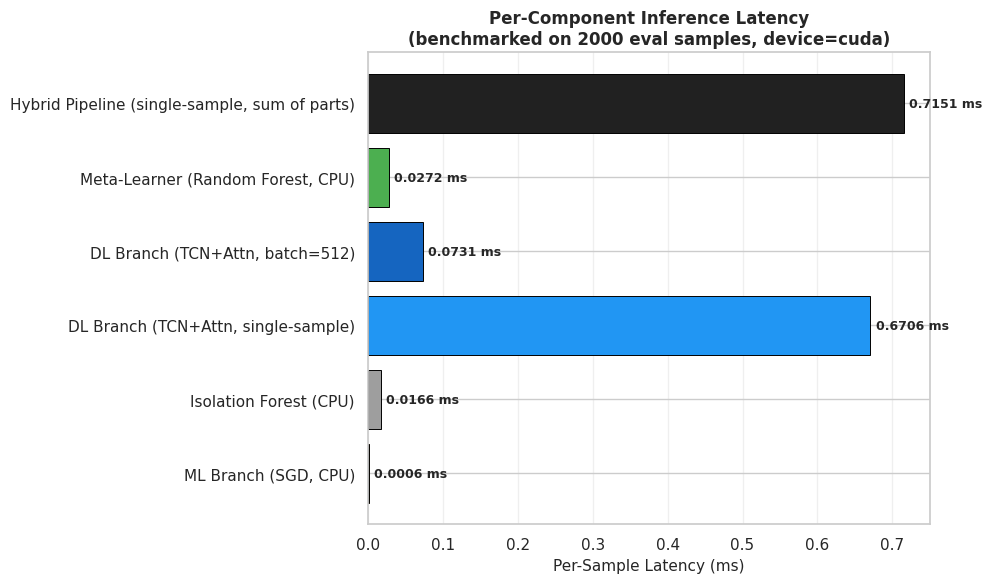

Saved → /content/drive/MyDrive/graph_latency_comparison.png


In [13]:
print("\n================ GRAPH: LATENCY COMPARISON ================")
fig, ax = plt.subplots(figsize=(10, 6))
comp_names = latency_table["Component"].tolist()
comp_vals  = latency_table["Per-sample (ms)"].tolist()
colors_lat = ['#FF9800', '#9E9E9E', '#2196F3', '#1565C0', '#4CAF50', '#212121']
bars = ax.barh(comp_names, comp_vals, color=colors_lat[:len(comp_names)], edgecolor='black', linewidth=0.7)
for bar, val in zip(bars, comp_vals):
    ax.text(val + max(comp_vals) * 0.01, bar.get_y() + bar.get_height() / 2,
            f'{val:.4f} ms', va='center', fontsize=9, fontweight='bold')
ax.set_xlabel("Per-Sample Latency (ms)", fontsize=11)
ax.set_title(f"Per-Component Inference Latency\n(benchmarked on {N_LATENCY_SAMPLES} eval samples, device={device})",
             fontsize=12, fontweight='bold')
ax.grid(axis='x', alpha=0.3)
plt.tight_layout()
save_and_show("/content/drive/MyDrive/graph_latency_comparison.png")



================ STEP 10: DRIFT DETECTION (ENHANCED) ================

[Feature Distribution Drift — Train vs PhiUSIIL (OOD)]
  ⚠  DRIFT in 'length': KS=0.1547, p=0.0
  ⚠  DRIFT in 'digit_count': KS=0.477, p=0.0
  ⚠  DRIFT in 'special_count': KS=0.4083, p=0.0
  ⚠  DRIFT in 'dot_count': KS=0.421, p=0.0
  ⚠  DRIFT in 'hyphen_count': KS=0.0733, p=0.0
  ⚠  DRIFT in 'pct_count': KS=0.0486, p=0.0
  ⚠  DRIFT in 'log_len': KS=0.1547, p=0.0
  ⚠  DRIFT in 'slash_count': KS=0.5129, p=0.0
  ⚠  DRIFT in 'digit_ratio': KS=0.4536, p=0.0
  ⚠  DRIFT in 'hyphen_ratio': KS=0.1274, p=0.0
  ⚠  DRIFT in 'has_query': KS=0.02, p=0.0
  ⚠  DRIFT in 'subdomain_depth': KS=0.421, p=0.0
  ⚠  DRIFT in 'has_ip': KS=0.4758, p=0.0
  ⚠  DRIFT in 'brand_hit': KS=0.0725, p=0.0

[Simulating Concept Drift — Adversarial Score Injection]
  Drift injected from index 92476 to 123301
  Running drift detection loop...
    [0/123302] processed...
    [10000/123302] processed...
    [20000/123302] processed...
    [30000/123302] p

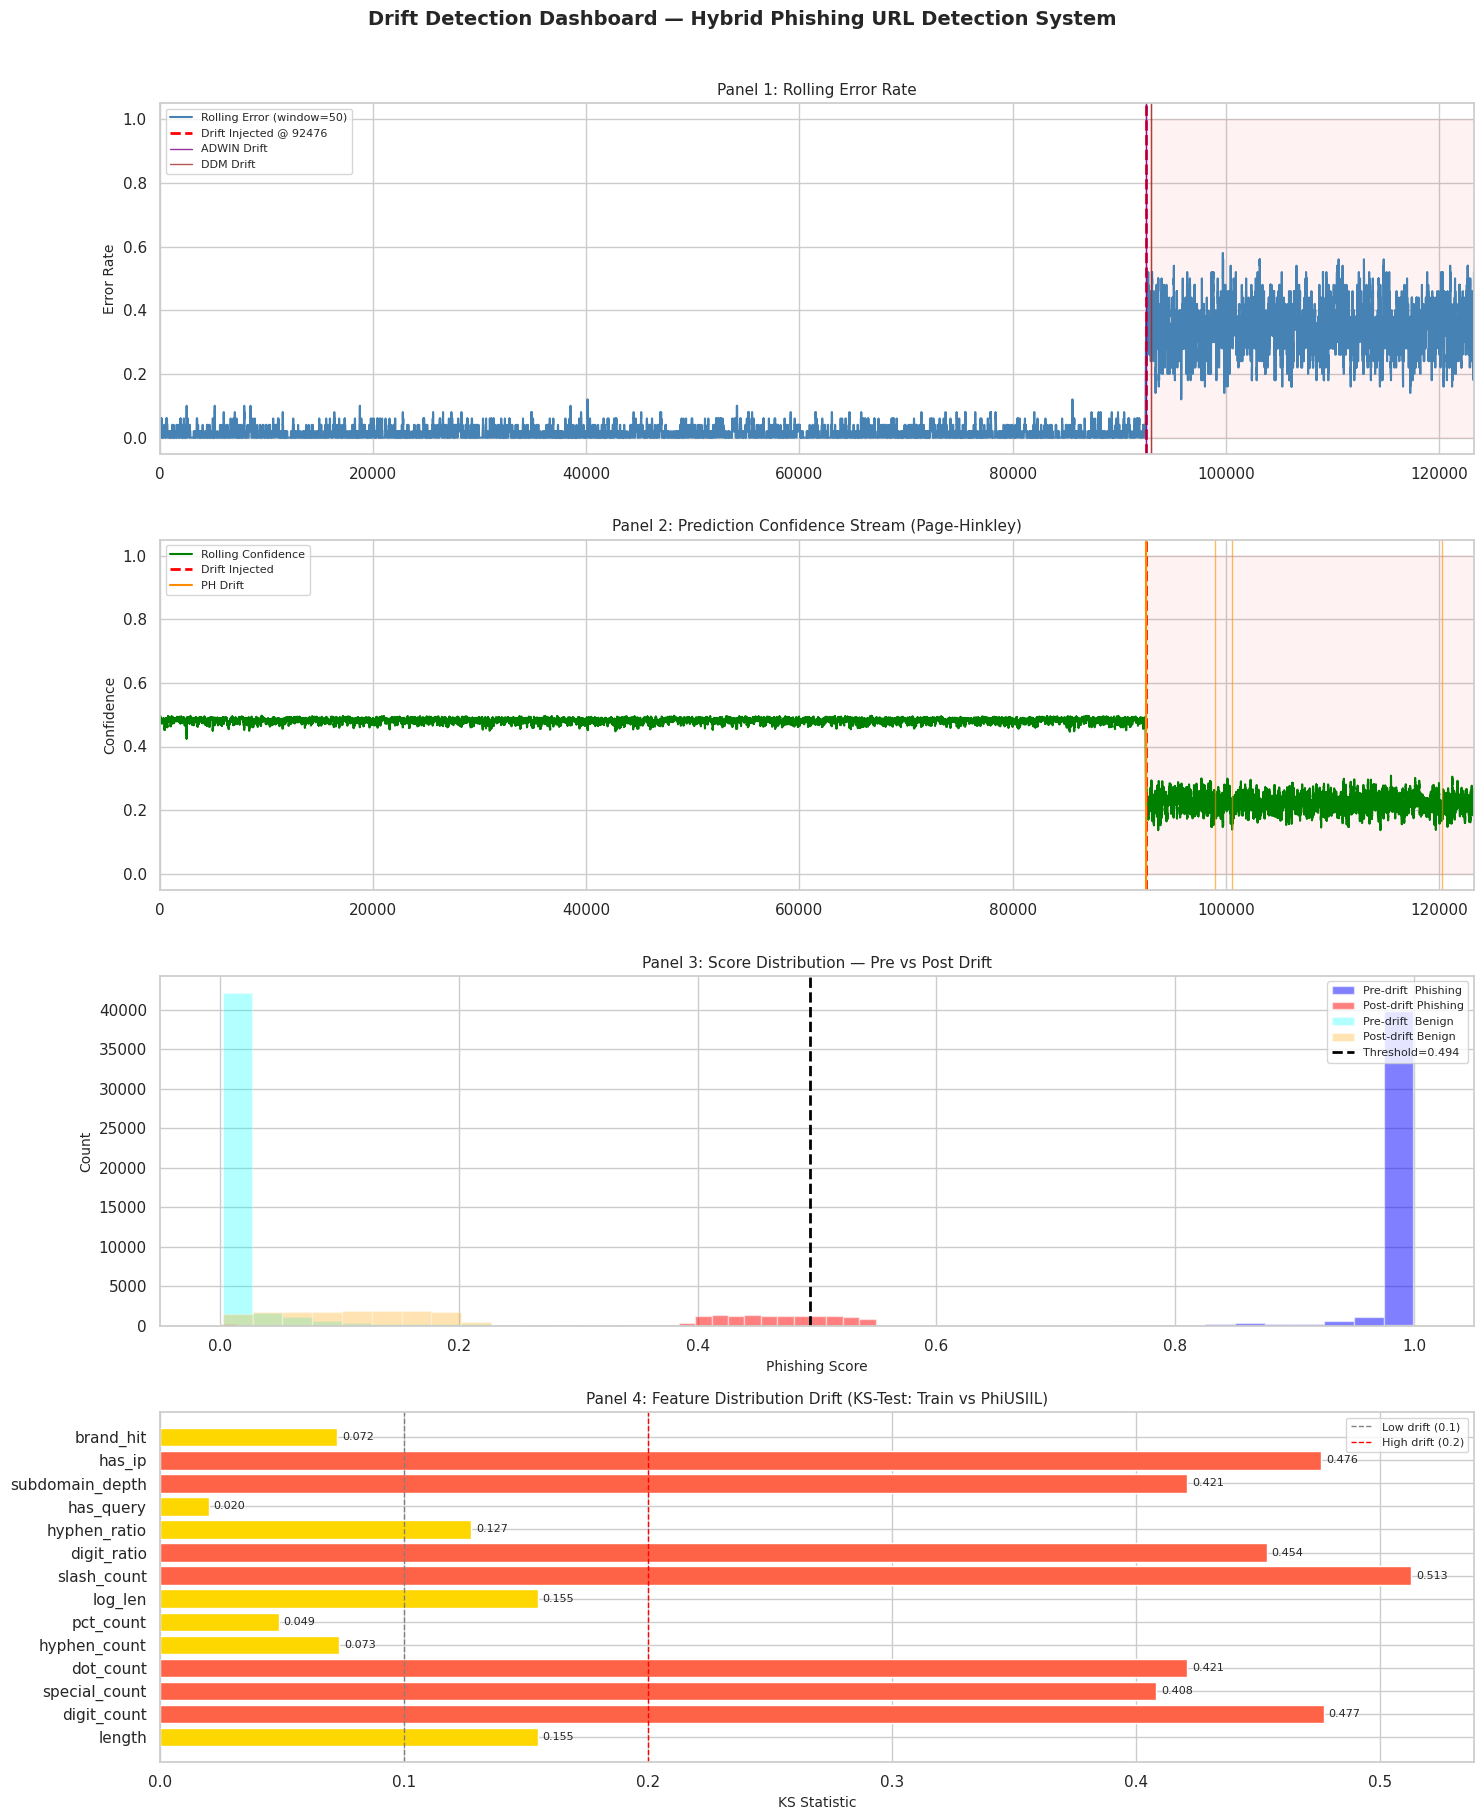

Saved → /content/drive/MyDrive/drift_detection_dashboard.png


In [14]:
# ==========================================================
print("\n================ STEP 10: DRIFT DETECTION (ENHANCED) ================")

class PageHinkley:
    def __init__(self, delta=0.005, lam=8):
        self.delta = delta
        self.lam   = lam
        self.reset()

    def reset(self):
        self.mean    = 0
        self.sum     = 0
        self.min_val = 0
        self.t       = 0

    def update(self, x):
        self.t   += 1
        self.mean += (x - self.mean) / self.t
        self.sum  += x - self.mean - self.delta
        self.min_val = min(self.min_val, self.sum)
        if self.sum - self.min_val > self.lam:
            self.reset()
            return True
        return False


class ADWIN:
    # PERF FIX: the original implementation looped over every candidate
    # split index and, for each one, sliced the window and called
    # .mean() on both halves — that's O(window) work per split and
    # O(window) splits, i.e. O(window^2) per single update() call, and
    # update() is called once per stream sample. Below, a single cumsum
    # over the window turns each split's mu0/mu1 into an O(1) lookup, so
    # the whole scan is O(window) per update() call instead of
    # O(window^2). The drift condition and the "return on first
    # satisfying split" behavior are unchanged, so results are
    # numerically identical to before — this is a pure speed fix.
    def __init__(self, delta=0.002, min_window=30, max_window=1000):
        self.delta      = delta
        self.min_window = min_window
        self.max_window = max_window
        self.window     = []

    def update(self, x):
        self.window.append(x)
        if len(self.window) > self.max_window:
            self.window = self.window[-self.max_window:]
        n = len(self.window)
        if n < self.min_window * 2:
            return False

        W = np.asarray(self.window, dtype=np.float64)
        cumsum = np.cumsum(W)
        total  = cumsum[-1]

        splits = np.arange(self.min_window, n - self.min_window)
        if splits.size == 0:
            return False

        n0 = splits.astype(np.float64)
        n1 = (n - splits).astype(np.float64)
        sum0 = cumsum[splits - 1]
        mu0  = sum0 / n0
        mu1  = (total - sum0) / n1

        eps_cut = np.sqrt((1.0 / (2 * n0) + 1.0 / (2 * n1)) * np.log(4 * n / self.delta))
        diff    = np.abs(mu0 - mu1)
        hit     = diff >= eps_cut

        if np.any(hit):
            first_hit_pos = np.argmax(hit)   # first True == smallest qualifying split, same as the old loop
            split = int(splits[first_hit_pos])
            self.window = list(W[split:])
            return True
        return False


class DDM:
    def __init__(self, warning_level=2.0, drift_level=3.0):
        self.warning_level = warning_level
        self.drift_level   = drift_level
        self.reset()

    def reset(self):
        self.n     = 1
        self.p     = 1
        self.s     = 0
        self.p_min = float('inf')
        self.s_min = float('inf')

    def update(self, error):
        self.n += 1
        self.p  = self.p + (error - self.p) / self.n
        self.s  = np.sqrt(max(self.p * (1 - self.p) / self.n, 1e-12))
        if self.p + self.s < self.p_min + self.s_min:
            self.p_min = self.p
            self.s_min = self.s
        if self.s_min < 1e-9:
            return "NORMAL"
        level = (self.p + self.s - self.p_min - self.s_min) / self.s_min
        if level > self.drift_level:
            self.reset()
            return "DRIFT"
        elif level > self.warning_level:
            return "WARNING"
        return "NORMAL"


def detect_feature_drift(X_ref, X_new, feature_names, alpha=0.01):
    drifted = []
    for i, name in enumerate(feature_names):
        stat, p = ks_2samp(X_ref[:, i], X_new[:, i])
        if p < alpha:
            drifted.append((name, round(stat, 4), round(p, 6)))
    return drifted

print("\n[Feature Distribution Drift — Train vs PhiUSIIL (OOD)]")
feature_drifts = detect_feature_drift(X_lex_train, X_lex_phi, LEX_NAMES)
if feature_drifts:
    for fname, stat, pval in feature_drifts:
        print(f"  ⚠  DRIFT in '{fname}': KS={stat}, p={pval}")
else:
    print("  No significant feature drift detected.")

print("\n[Simulating Concept Drift — Adversarial Score Injection]")

drift_start = int(n_eval * 0.75)
noise_scale = 0.45

# The perturbation is a deterministic function of the stream index (pre-drawn uniforms, same seed and
# same draw order as the original loop), so the IDENTICAL perturbation can be re-applied to any
# re-scored part of the stream (needed for equivalent pre/post-retraining conditions, R4-3).
_U_drift  = np.random.default_rng(42).random(n_eval - drift_start)
_y_stream = eval_df.labels.values

def perturb_scores(scores, start_idx):
    """Apply the adversarial score perturbation to scores[k] = stream index start_idx+k.
    NOTE: it is label-dependent (it needs the true class), i.e. an oracle adversary stress test,
    applied AFTER the model - it is NOT an input-distribution shift."""
    scores = np.asarray(scores, dtype=float)
    out = scores.copy()
    j = np.arange(start_idx, start_idx + len(scores))
    m = j >= drift_start
    if m.any():
        jj = j[m]; u = _U_drift[jj - drift_start]; lab = _y_stream[jj]
        down = noise_scale + (0.6 - noise_scale) * u
        up   = 0.2 * u
        out[m] = np.where(lab == 1, np.maximum(0.0, scores[m] - down), np.minimum(1.0, scores[m] + up))
    return out

S_eval_sim = perturb_scores(S_eval, 0)

yhat_sim = (S_eval_sim > best_thr).astype(int)
print(f"  Drift injected from index {drift_start} to {n_eval-1}")

ph2   = PageHinkley(delta=0.005, lam=8)
adwin = ADWIN(delta=0.002, min_window=30, max_window=1000)
ddm   = DDM(warning_level=2.0, drift_level=3.0)

WINDOW         = 50
ph_drifts      = []
adwin_drifts   = []
ddm_drifts     = []
ddm_warnings   = []
rolling_errors = []
conf_stream    = []

print("  Running drift detection loop...")
for i in range(n_eval):
    if i % 10000 == 0:
        print(f"    [{i}/{n_eval}] processed...")
    true_label = eval_df.labels.iloc[i]
    pred_label = yhat_sim[i]
    score      = S_eval_sim[i]
    err        = int(pred_label != true_label)

    conf = abs(score - best_thr)
    conf_stream.append(conf)
    rolling_errors.append(err)

    if ph2.update(1 - conf):
        ph_drifts.append(i)

    if adwin.update(float(err)):
        adwin_drifts.append(i)

    status = ddm.update(err)
    if status == "DRIFT":
        ddm_drifts.append(i)
    elif status == "WARNING":
        ddm_warnings.append(i)

print(f"  Drift detection loop complete.")

print(f"\n{'='*55}")
print(f"  DRIFT DETECTION SUMMARY")
print(f"{'='*55}")
print(f"  Drift injected at index        : {drift_start}")
print(f"  Page-Hinkley (confidence-based): {len(ph_drifts):>4} drift(s)   {ph_drifts[:8]}")
print(f"  ADWIN        (error-based)     : {len(adwin_drifts):>4} drift(s)   {adwin_drifts[:8]}")
print(f"  DDM          (error-based)     : {len(ddm_drifts):>4} drift(s)   {ddm_drifts[:8]}")
print(f"  DDM          Warnings          : {len(ddm_warnings):>4}")
print(f"  KS-Test Feature Drifts         : {len(feature_drifts):>4} feature(s)")
print(f"{'='*55}")

print("\n[Performance: Before vs After Drift Injection]")
pre_true  = eval_df.labels.iloc[:drift_start].values
pre_pred  = yhat_sim[:drift_start]
post_true = eval_df.labels.iloc[drift_start:].values
post_pred = yhat_sim[drift_start:]

print(f"\n  Pre-drift  (idx 0–{drift_start-1}):")
print(f"    Accuracy : {accuracy_score(pre_true, pre_pred):.6f}")
print(f"    F1 Score : {f1_score(pre_true, pre_pred):.6f}")
print(f"\n  Post-drift (idx {drift_start}–{n_eval-1}):")
print(f"    Accuracy : {accuracy_score(post_true, post_pred):.6f}")
print(f"    F1 Score : {f1_score(post_true, post_pred):.6f}")


# ==========================================================
# ORIGINAL GRAPH: DRIFT DETECTION DASHBOARD
# ==========================================================
fig, axes = plt.subplots(4, 1, figsize=(15, 18))
fig.suptitle(
    "Drift Detection Dashboard — Hybrid Phishing URL Detection System",
    fontsize=14, fontweight='bold', y=1.01
)

roll_err = pd.Series(rolling_errors).rolling(WINDOW, min_periods=1).mean()
ax = axes[0]
ax.plot(roll_err, color='steelblue', linewidth=1.5, label=f'Rolling Error (window={WINDOW})')
ax.axvline(drift_start, color='red', linestyle='--', linewidth=2, label=f'Drift Injected @ {drift_start}')
for d in adwin_drifts:
    ax.axvline(d, color='purple', alpha=0.5, linewidth=1)
for d in ddm_drifts:
    ax.axvline(d, color='brown', alpha=0.5, linewidth=1)
if adwin_drifts:
    ax.axvline(adwin_drifts[0], color='purple', alpha=0.8, linewidth=1, label='ADWIN Drift')
if ddm_drifts:
    ax.axvline(ddm_drifts[0], color='brown', alpha=0.8, linewidth=1, label='DDM Drift')
ax.set_ylabel("Error Rate", fontsize=10)
ax.set_title("Panel 1: Rolling Error Rate", fontsize=11)
ax.legend(fontsize=8); ax.set_xlim(0, n_eval)
ax.fill_between(range(drift_start, n_eval), 0, 1, alpha=0.05, color='red')

roll_conf = pd.Series(conf_stream).rolling(WINDOW, min_periods=1).mean()
ax = axes[1]
ax.plot(roll_conf, color='green', linewidth=1.5, label='Rolling Confidence')
ax.axvline(drift_start, color='red', linestyle='--', linewidth=2, label='Drift Injected')
for d in ph_drifts:
    ax.axvline(d, color='darkorange', alpha=0.6, linewidth=1)
if ph_drifts:
    ax.axvline(ph_drifts[0], color='darkorange', linewidth=1.5, label='PH Drift')
ax.set_ylabel("Confidence", fontsize=10)
ax.set_title("Panel 2: Prediction Confidence Stream (Page-Hinkley)", fontsize=11)
ax.legend(fontsize=8); ax.set_xlim(0, n_eval)
ax.fill_between(range(drift_start, n_eval), 0, 1, alpha=0.05, color='red')

ax = axes[2]
pre_phi_scores  = S_eval_sim[:drift_start][eval_df.labels.iloc[:drift_start].values == 1]
post_phi_scores = S_eval_sim[drift_start:][eval_df.labels.iloc[drift_start:].values == 1]
pre_ben_scores  = S_eval_sim[:drift_start][eval_df.labels.iloc[:drift_start].values == 0]
post_ben_scores = S_eval_sim[drift_start:][eval_df.labels.iloc[drift_start:].values == 0]
ax.hist(pre_phi_scores,  bins=40, alpha=0.5, color='blue',   label='Pre-drift  Phishing')
ax.hist(post_phi_scores, bins=40, alpha=0.5, color='red',    label='Post-drift Phishing')
ax.hist(pre_ben_scores,  bins=40, alpha=0.3, color='cyan',   label='Pre-drift  Benign')
ax.hist(post_ben_scores, bins=40, alpha=0.3, color='orange', label='Post-drift Benign')
ax.axvline(best_thr, color='black', linestyle='--', linewidth=2, label=f'Threshold={best_thr:.3f}')
ax.set_xlabel("Phishing Score", fontsize=10)
ax.set_ylabel("Count", fontsize=10)
ax.set_title("Panel 3: Score Distribution — Pre vs Post Drift", fontsize=11)
ax.legend(fontsize=8)

ax = axes[3]
if feature_drifts:
    feat_names = [fd[0] for fd in feature_drifts]
    ks_stats   = [fd[1] for fd in feature_drifts]
    bar_colors = ['tomato' if s > 0.2 else 'gold' for s in ks_stats]
    bars = ax.barh(feat_names, ks_stats, color=bar_colors)
    ax.axvline(0.1, color='grey', linestyle='--', linewidth=1, label='Low drift (0.1)')
    ax.axvline(0.2, color='red',  linestyle='--', linewidth=1, label='High drift (0.2)')
    ax.set_xlabel("KS Statistic", fontsize=10)
    ax.set_title("Panel 4: Feature Distribution Drift (KS-Test: Train vs PhiUSIIL)", fontsize=11)
    ax.legend(fontsize=8)
    for bar, val in zip(bars, ks_stats):
        ax.text(val + 0.002, bar.get_y() + bar.get_height()/2, f'{val:.3f}', va='center', fontsize=8)
else:
    ax.text(0.5, 0.5, "No significant feature drift detected\n(KS p-value > 0.01 for all features)",
            ha='center', va='center', transform=ax.transAxes, fontsize=12)
    ax.set_title("Panel 4: Feature Distribution Drift (KS-Test)", fontsize=11)

plt.tight_layout()
save_and_show("/content/drive/MyDrive/drift_detection_dashboard.png")



================ STEP 11: ROLLING WINDOW ACCURACY ================


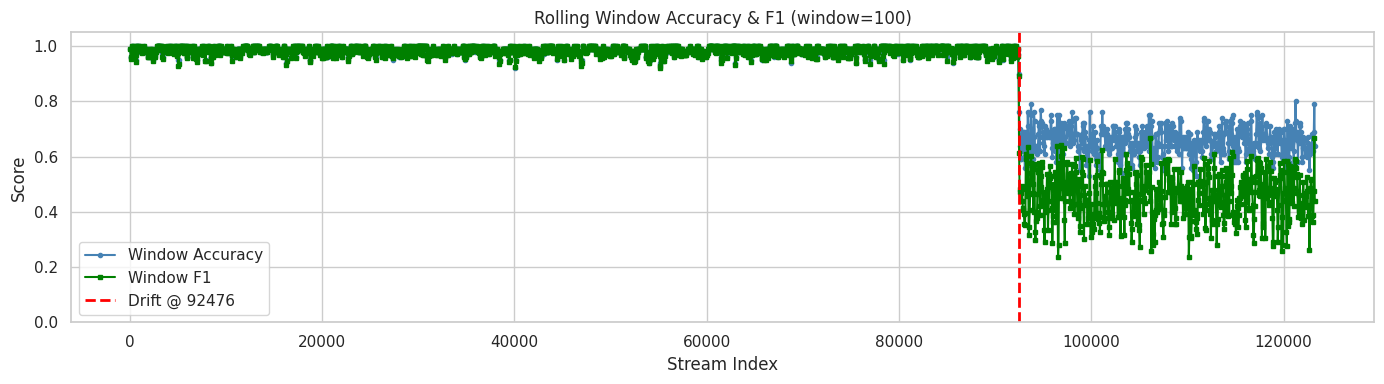

Saved → /content/drive/MyDrive/rolling_window_metrics.png


In [15]:
# ==========================================================
# STEP 11: ROLLING WINDOW METRICS OVER TIME
# ==========================================================
print("\n================ STEP 11: ROLLING WINDOW ACCURACY ================")

win_size = 100
win_acc  = []
win_f1   = []
win_idx  = []

for start in range(0, n_eval - win_size, win_size // 2):
    end = start + win_size
    yt  = eval_df.labels.iloc[start:end].values
    yp  = yhat_sim[start:end]
    if len(np.unique(yt)) < 2:
        continue
    win_acc.append(accuracy_score(yt, yp))
    win_f1.append(f1_score(yt, yp))
    win_idx.append(start + win_size // 2)

fig, ax = plt.subplots(figsize=(14, 4))
ax.plot(win_idx, win_acc, marker='o', markersize=3, label='Window Accuracy', color='steelblue')
ax.plot(win_idx, win_f1,  marker='s', markersize=3, label='Window F1',       color='green')
ax.axvline(drift_start, color='red', linestyle='--', linewidth=2, label=f'Drift @ {drift_start}')
ax.set_xlabel("Stream Index"); ax.set_ylabel("Score")
ax.set_title(f"Rolling Window Accuracy & F1 (window={win_size})")
ax.legend(); ax.set_ylim(0, 1.05)
plt.tight_layout()
save_and_show("/content/drive/MyDrive/rolling_window_metrics.png")



================ GRAPH 1: DATA EXPLORATION ================


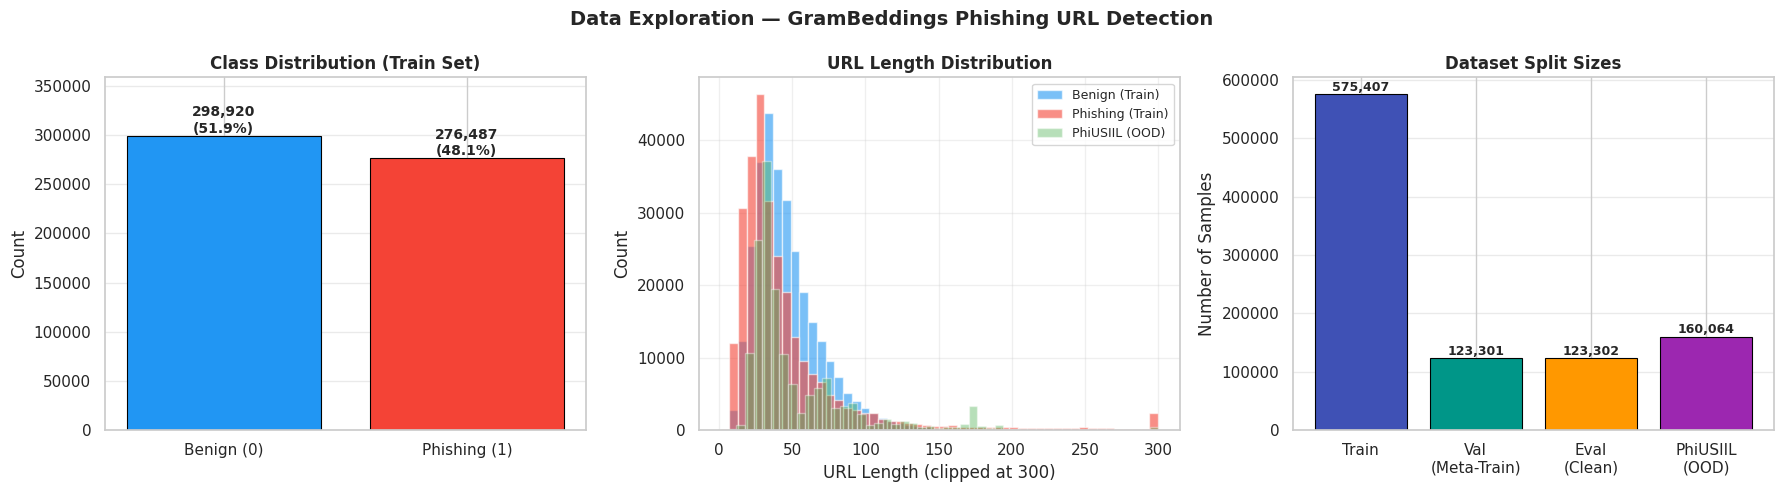

Saved → /content/drive/MyDrive/graph1_data_exploration.png


In [16]:
# ==========================================================
# GRAPH 1: DATA EXPLORATION
# ==========================================================
print("\n================ GRAPH 1: DATA EXPLORATION ================")

train_df['url_len'] = train_df.url.apply(len)
phi_df['url_len']   = phi_df.url.apply(len)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
fig.suptitle("Data Exploration — GramBeddings Phishing URL Detection", fontsize=14, fontweight='bold')

ax = axes[0]
class_counts = train_df.labels.value_counts()
bars = ax.bar(['Benign (0)', 'Phishing (1)'], class_counts.values,
               color=['#2196F3', '#F44336'], edgecolor='black', linewidth=0.8)
for bar, val in zip(bars, class_counts.values):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 500,
            f'{val:,}\n({val/len(train_df)*100:.1f}%)',
            ha='center', va='bottom', fontsize=10, fontweight='bold')
ax.set_title("Class Distribution (Train Set)", fontsize=12, fontweight='bold')
ax.set_ylabel("Count")
ax.set_ylim(0, class_counts.max() * 1.2)
ax.grid(axis='y', alpha=0.4)

ax = axes[1]
ax.hist(train_df[train_df.labels==0]['url_len'].clip(0,300), bins=50, alpha=0.6, color='#2196F3', label='Benign (Train)')
ax.hist(train_df[train_df.labels==1]['url_len'].clip(0,300), bins=50, alpha=0.6, color='#F44336', label='Phishing (Train)')
ax.hist(phi_df['url_len'].clip(0,300), bins=50, alpha=0.4, color='#4CAF50', label='PhiUSIIL (OOD)')
ax.set_title("URL Length Distribution", fontsize=12, fontweight='bold')
ax.set_xlabel("URL Length (clipped at 300)")
ax.set_ylabel("Count")
ax.legend(fontsize=9); ax.grid(alpha=0.3)

ax = axes[2]
datasets  = ['Train', 'Val\n(Meta-Train)', 'Eval\n(Clean)', 'PhiUSIIL\n(OOD)']
sizes     = [len(train_df), len(val_df), len(eval_df), len(phi_df)]
colors_ds = ['#3F51B5', '#009688', '#FF9800', '#9C27B0']
bars = ax.bar(datasets, sizes, color=colors_ds, edgecolor='black', linewidth=0.8)
for bar, val in zip(bars, sizes):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 1000,
            f'{val:,}', ha='center', va='bottom', fontsize=9, fontweight='bold')
ax.set_title("Dataset Split Sizes", fontsize=12, fontweight='bold')
ax.set_ylabel("Number of Samples")
ax.grid(axis='y', alpha=0.4)

plt.tight_layout()
save_and_show("/content/drive/MyDrive/graph1_data_exploration.png")



================ GRAPH 2: LEXICAL FEATURES ================


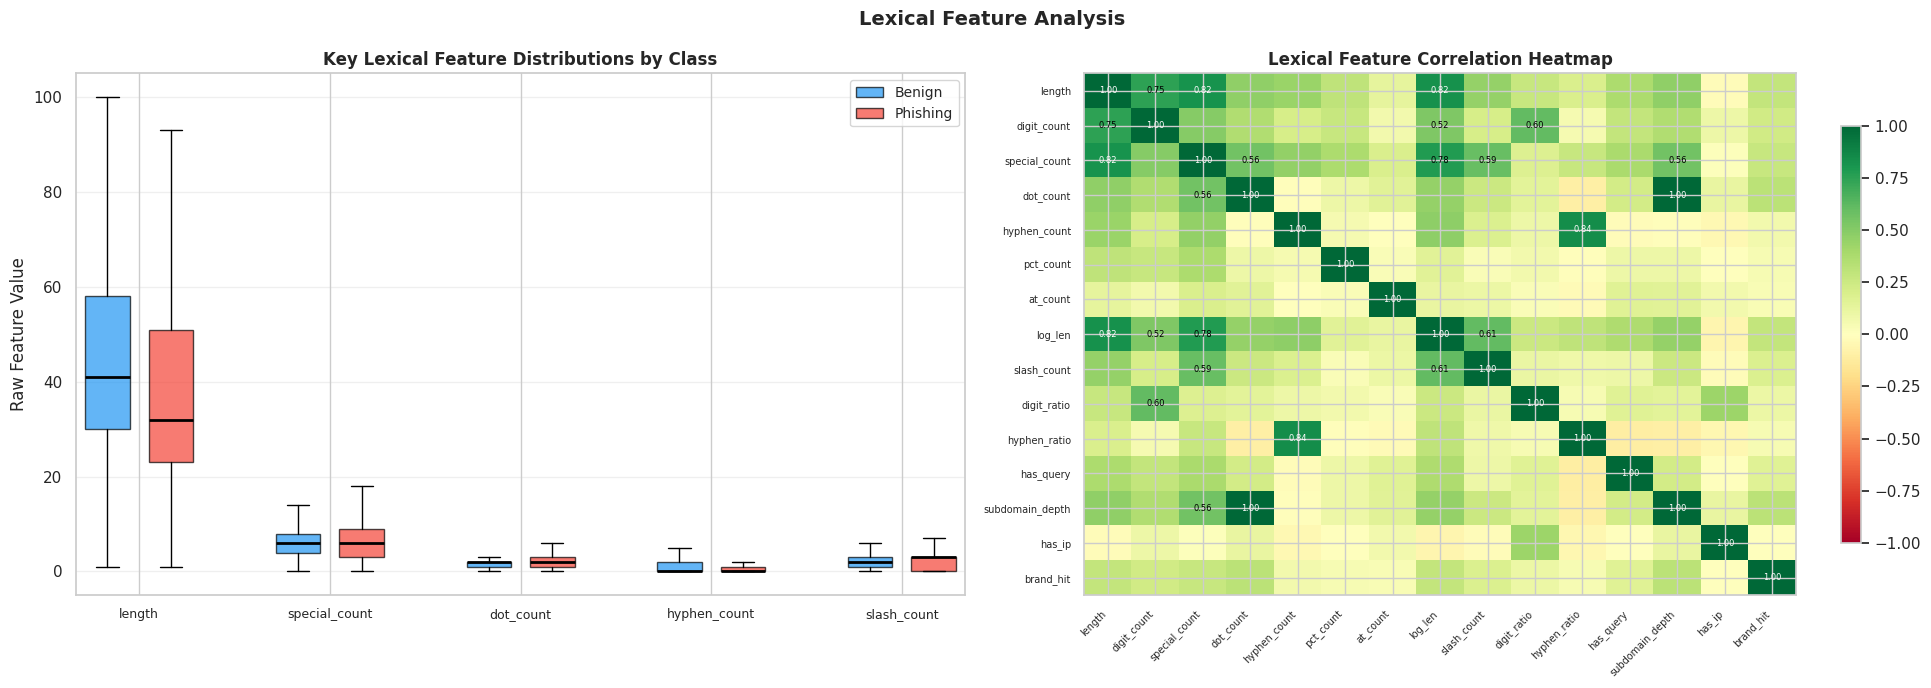

Saved → /content/drive/MyDrive/graph2_lexical_features.png


In [17]:
# ==========================================================
# GRAPH 2: LEXICAL FEATURE ANALYSIS
# ==========================================================
print("\n================ GRAPH 2: LEXICAL FEATURES ================")

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
fig.suptitle("Lexical Feature Analysis", fontsize=14, fontweight='bold')

ax = axes[0]
key_feats     = [0, 2, 3, 4, 8]
key_names     = ['length', 'special_count', 'dot_count', 'hyphen_count', 'slash_count']
benign_data   = [X_lex_train_raw[train_df.labels.values == 0, i] for i in key_feats]
phishing_data = [X_lex_train_raw[train_df.labels.values == 1, i] for i in key_feats]
positions_b   = np.arange(len(key_feats)) * 3
positions_p   = positions_b + 1

bp1 = ax.boxplot(benign_data,   positions=positions_b, widths=0.7, patch_artist=True,
                 boxprops=dict(facecolor='#2196F3', alpha=0.7),
                 medianprops=dict(color='black', linewidth=2), showfliers=False)
bp2 = ax.boxplot(phishing_data, positions=positions_p, widths=0.7, patch_artist=True,
                 boxprops=dict(facecolor='#F44336', alpha=0.7),
                 medianprops=dict(color='black', linewidth=2), showfliers=False)
ax.set_xticks(positions_b + 0.5)
ax.set_xticklabels(key_names, fontsize=9)
ax.set_title("Key Lexical Feature Distributions by Class", fontsize=12, fontweight='bold')
ax.set_ylabel("Raw Feature Value")
ax.legend([bp1['boxes'][0], bp2['boxes'][0]], ['Benign', 'Phishing'], fontsize=10)
ax.grid(axis='y', alpha=0.3)

ax = axes[1]
df_lex = pd.DataFrame(X_lex_train_raw, columns=LEX_NAMES)
corr   = df_lex.corr()
im     = ax.imshow(corr.values, cmap='RdYlGn', vmin=-1, vmax=1, aspect='auto')
ax.set_xticks(range(len(LEX_NAMES))); ax.set_xticklabels(LEX_NAMES, rotation=45, ha='right', fontsize=7)
ax.set_yticks(range(len(LEX_NAMES))); ax.set_yticklabels(LEX_NAMES, fontsize=7)
for i in range(len(LEX_NAMES)):
    for j in range(len(LEX_NAMES)):
        if abs(corr.values[i, j]) > 0.5:
            ax.text(j, i, f'{corr.values[i,j]:.2f}', ha='center', va='center', fontsize=6,
                    color='black' if abs(corr.values[i, j]) < 0.8 else 'white')
plt.colorbar(im, ax=ax, shrink=0.8)
ax.set_title("Lexical Feature Correlation Heatmap", fontsize=12, fontweight='bold')

plt.tight_layout()
save_and_show("/content/drive/MyDrive/graph2_lexical_features.png")



================ GRAPH 3: TCN TRAINING CURVES ================


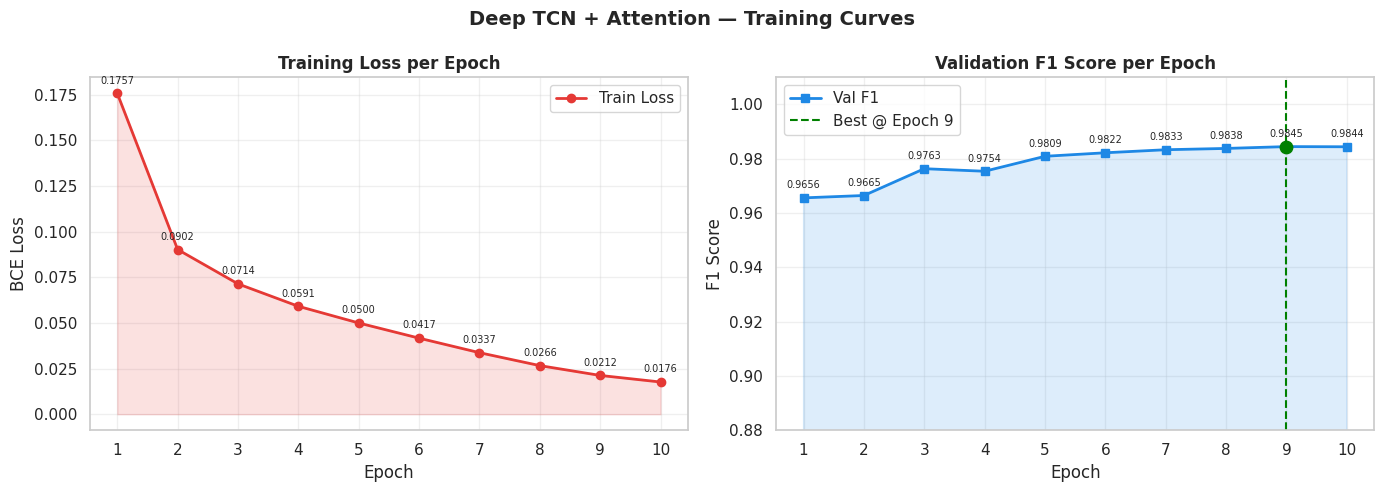

Saved → /content/drive/MyDrive/graph3_training_curves.png


In [18]:
# ==========================================================
# GRAPH 3: TCN TRAINING CURVES
# ==========================================================
print("\n================ GRAPH 3: TCN TRAINING CURVES ================")

epochs = list(range(1, len(epoch_losses) + 1))

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
fig.suptitle("Deep TCN + Attention — Training Curves", fontsize=14, fontweight='bold')

ax = axes[0]
ax.plot(epochs, epoch_losses, marker='o', color='#E53935', linewidth=2, markersize=6, label='Train Loss')
ax.fill_between(epochs, epoch_losses, alpha=0.15, color='#E53935')
ax.set_title("Training Loss per Epoch", fontsize=12, fontweight='bold')
ax.set_xlabel("Epoch"); ax.set_ylabel("BCE Loss")
ax.set_xticks(epochs)
for x, y in zip(epochs, epoch_losses):
    ax.annotate(f'{y:.4f}', (x, y), textcoords="offset points", xytext=(0, 7), ha='center', fontsize=7)
ax.grid(alpha=0.3); ax.legend()

ax = axes[1]
ax.plot(epochs, epoch_val_f1, marker='s', color='#1E88E5', linewidth=2, markersize=6, label='Val F1')
ax.fill_between(epochs, epoch_val_f1, alpha=0.15, color='#1E88E5')
best_ep = epoch_val_f1.index(max(epoch_val_f1)) + 1
ax.axvline(best_ep, color='green', linestyle='--', linewidth=1.5, label=f'Best @ Epoch {best_ep}')
ax.scatter([best_ep], [max(epoch_val_f1)], color='green', zorder=5, s=80)
ax.set_title("Validation F1 Score per Epoch", fontsize=12, fontweight='bold')
ax.set_xlabel("Epoch"); ax.set_ylabel("F1 Score")
ax.set_xticks(epochs); ax.set_ylim(0.88, 1.01)
for x, y in zip(epochs, epoch_val_f1):
    ax.annotate(f'{y:.4f}', (x, y), textcoords="offset points", xytext=(0, 7), ha='center', fontsize=7)
ax.grid(alpha=0.3); ax.legend()

plt.tight_layout()
save_and_show("/content/drive/MyDrive/graph3_training_curves.png")



================ GRAPH 4: ROC & PR CURVES ================


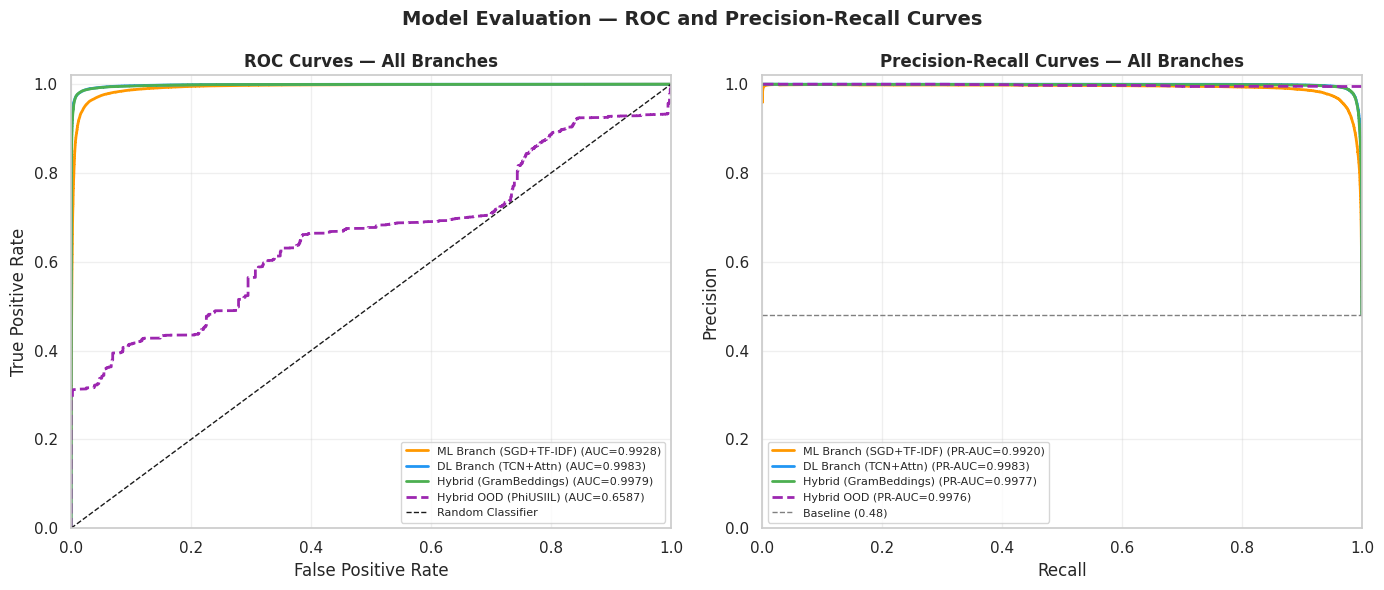

Saved → /content/drive/MyDrive/graph4_roc_pr_curves.png


In [19]:
# ==========================================================
# GRAPH 4: ROC & PR CURVES
# ==========================================================
print("\n================ GRAPH 4: ROC & PR CURVES ================")

eval_true = eval_df.labels.values

fig, axes = plt.subplots(1, 2, figsize=(14, 6))
fig.suptitle("Model Evaluation — ROC and Precision-Recall Curves", fontsize=14, fontweight='bold')

branches = [
    ("ML Branch (SGD+TF-IDF)", p_ml_eval, '#FF9800'),
    ("DL Branch (TCN+Attn)",   p_dl_eval, '#2196F3'),
    ("Hybrid (GramBeddings)",  S_eval,    '#4CAF50'),
]

ax = axes[0]
for name, scores, color in branches:
    fpr, tpr, _ = roc_curve(eval_true, scores)
    ax.plot(fpr, tpr, color=color, linewidth=2, label=f'{name} (AUC={auc(fpr, tpr):.4f})')
fpr_phi, tpr_phi, _ = roc_curve(phi_df.labels.values, S_phi)
ax.plot(fpr_phi, tpr_phi, color='#9C27B0', linewidth=2, linestyle='--',
        label=f'Hybrid OOD (PhiUSIIL) (AUC={auc(fpr_phi, tpr_phi):.4f})')
ax.plot([0, 1], [0, 1], 'k--', linewidth=1, label='Random Classifier')
ax.set_title("ROC Curves — All Branches", fontsize=12, fontweight='bold')
ax.set_xlabel("False Positive Rate"); ax.set_ylabel("True Positive Rate")
ax.legend(fontsize=8, loc='lower right'); ax.grid(alpha=0.3)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)

ax = axes[1]
for name, scores, color in branches:
    prec_c, rec_c, _ = precision_recall_curve(eval_true, scores)
    ax.plot(rec_c, prec_c, color=color, linewidth=2, label=f'{name} (PR-AUC={auc(rec_c, prec_c):.4f})')
prec_phi, rec_phi, _ = precision_recall_curve(phi_df.labels.values, S_phi)
ax.plot(rec_phi, prec_phi, color='#9C27B0', linewidth=2, linestyle='--',
        label=f'Hybrid OOD (PR-AUC={auc(rec_phi, prec_phi):.4f})')
ax.axhline(eval_true.mean(), color='gray', linestyle='--', linewidth=1, label=f'Baseline ({eval_true.mean():.2f})')
ax.set_title("Precision-Recall Curves — All Branches", fontsize=12, fontweight='bold')
ax.set_xlabel("Recall"); ax.set_ylabel("Precision")
ax.legend(fontsize=8, loc='lower left'); ax.grid(alpha=0.3)
ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)

plt.tight_layout()
save_and_show("/content/drive/MyDrive/graph4_roc_pr_curves.png")



================ GRAPH 5: CONFUSION MATRICES ================


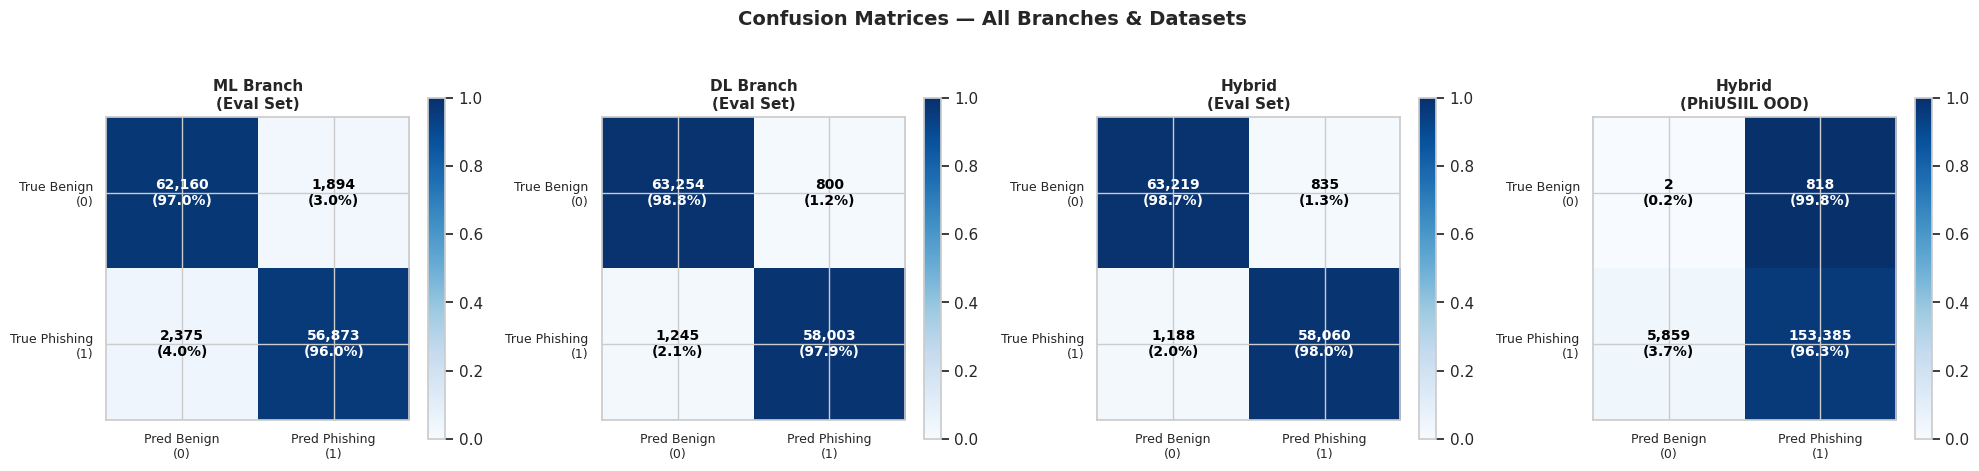

Saved → /content/drive/MyDrive/graph5_confusion_matrices.png


In [20]:
# ==========================================================
# GRAPH 5: CONFUSION MATRICES
# ==========================================================
print("\n================ GRAPH 5: CONFUSION MATRICES ================")

fig, axes = plt.subplots(1, 4, figsize=(20, 5))
fig.suptitle("Confusion Matrices — All Branches & Datasets", fontsize=14, fontweight='bold')

configs = [
    ("ML Branch\n(Eval Set)",  eval_df.labels.values, (p_ml_eval > 0.5).astype(int)),
    ("DL Branch\n(Eval Set)",  eval_df.labels.values, (p_dl_eval > 0.5).astype(int)),
    ("Hybrid\n(Eval Set)",     eval_df.labels.values, yhat_eval),
    ("Hybrid\n(PhiUSIIL OOD)", phi_df.labels.values,  yhat_phi),
]

for ax, (title, y_true, y_pred) in zip(axes, configs):
    cm      = confusion_matrix(y_true, y_pred)
    cm_norm = cm.astype(float) / cm.sum(axis=1, keepdims=True)
    im = ax.imshow(cm_norm, cmap='Blues', vmin=0, vmax=1)
    for i in range(2):
        for j in range(2):
            ax.text(j, i, f'{cm[i,j]:,}\n({cm_norm[i,j]*100:.1f}%)',
                    ha='center', va='center', fontsize=10,
                    color='white' if cm_norm[i,j] > 0.6 else 'black', fontweight='bold')
    ax.set_xticks([0,1]); ax.set_yticks([0,1])
    ax.set_xticklabels(['Pred Benign\n(0)', 'Pred Phishing\n(1)'], fontsize=9)
    ax.set_yticklabels(['True Benign\n(0)', 'True Phishing\n(1)'], fontsize=9)
    ax.set_title(title, fontsize=11, fontweight='bold')
    plt.colorbar(im, ax=ax, shrink=0.8)

plt.tight_layout()
save_and_show("/content/drive/MyDrive/graph5_confusion_matrices.png")



================ GRAPH 6: MODEL COMPARISON ================


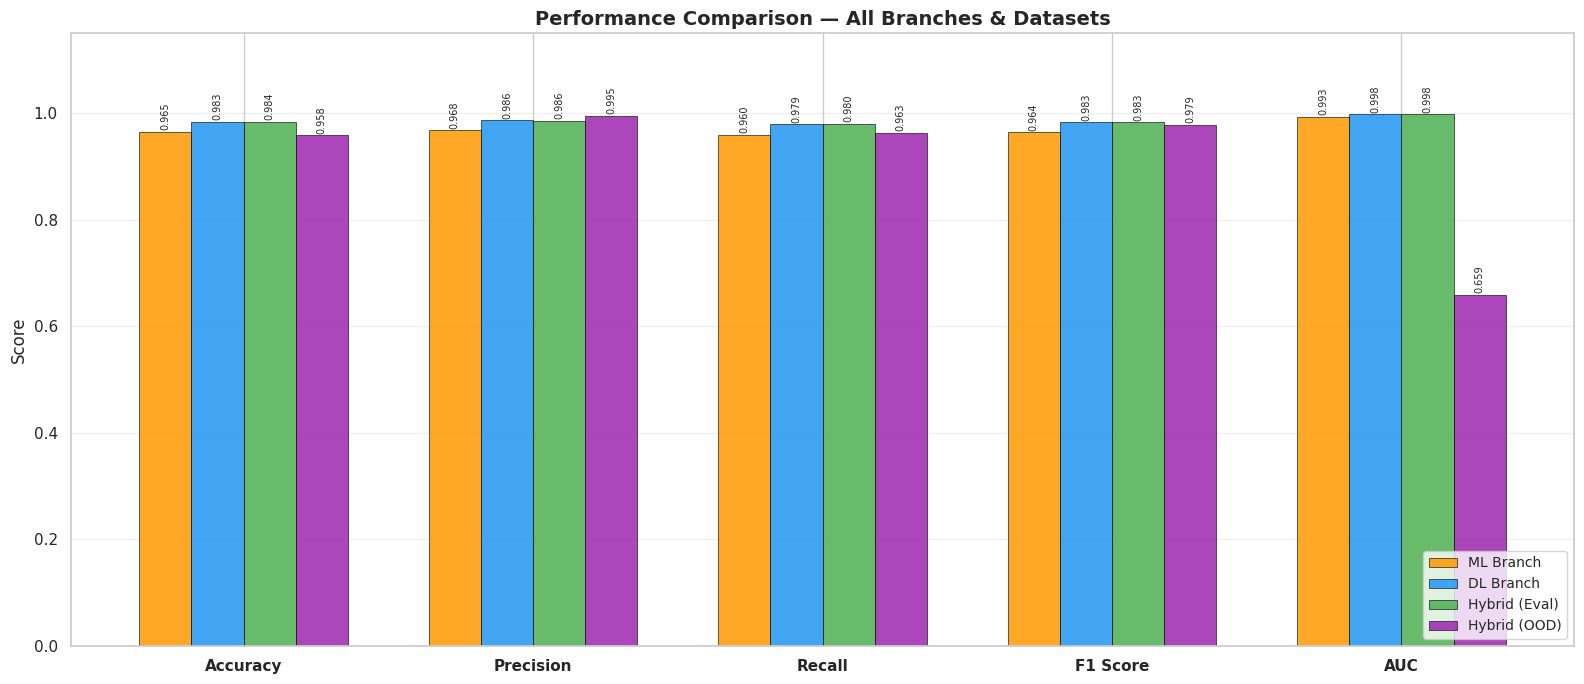

Saved → /content/drive/MyDrive/graph6_model_comparison.png


In [21]:
# ==========================================================
# GRAPH 6: MODEL PERFORMANCE COMPARISON
# ==========================================================
print("\n================ GRAPH 6: MODEL COMPARISON ================")

metrics_data = {}
for name, preds_raw, preds_bin, true in [
    ("ML Branch",     p_ml_eval, (p_ml_eval > 0.5).astype(int), eval_true),
    ("DL Branch",     p_dl_eval, (p_dl_eval > 0.5).astype(int), eval_true),
    ("Hybrid (Eval)", S_eval,    yhat_eval,                      eval_true),
    ("Hybrid (OOD)",  S_phi,     yhat_phi,                       phi_df.labels.values),
]:
    fpr_, tpr_, _ = roc_curve(true, preds_raw)
    metrics_data[name] = {
        'Accuracy':  accuracy_score(true, preds_bin),
        'Precision': precision_score(true, preds_bin),
        'Recall':    recall_score(true, preds_bin),
        'F1 Score':  f1_score(true, preds_bin),
        'AUC':       auc(fpr_, tpr_),
    }

metric_names = list(list(metrics_data.values())[0].keys())
model_names  = list(metrics_data.keys())
n_metrics    = len(metric_names)
n_models     = len(model_names)

fig, ax = plt.subplots(figsize=(16, 7))
x        = np.arange(n_metrics)
width    = 0.18
colors_m = ['#FF9800', '#2196F3', '#4CAF50', '#9C27B0']

for i, (model_name, color) in enumerate(zip(model_names, colors_m)):
    vals = [metrics_data[model_name][m] for m in metric_names]
    bars = ax.bar(x + i * width, vals, width, label=model_name, color=color,
                  alpha=0.85, edgecolor='black', linewidth=0.5)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.003,
                f'{val:.3f}', ha='center', va='bottom', fontsize=7, rotation=90)

ax.set_xticks(x + width * (n_models - 1) / 2)
ax.set_xticklabels(metric_names, fontsize=11, fontweight='bold')
ax.set_ylabel("Score", fontsize=12)
ax.set_title("Performance Comparison — All Branches & Datasets", fontsize=14, fontweight='bold')
ax.set_ylim(0, 1.15)
ax.legend(fontsize=10, loc='lower right')
ax.grid(axis='y', alpha=0.3)

plt.tight_layout()
save_and_show("/content/drive/MyDrive/graph6_model_comparison.png")



================ GRAPH 7: META-LEARNER & ANOMALY ================


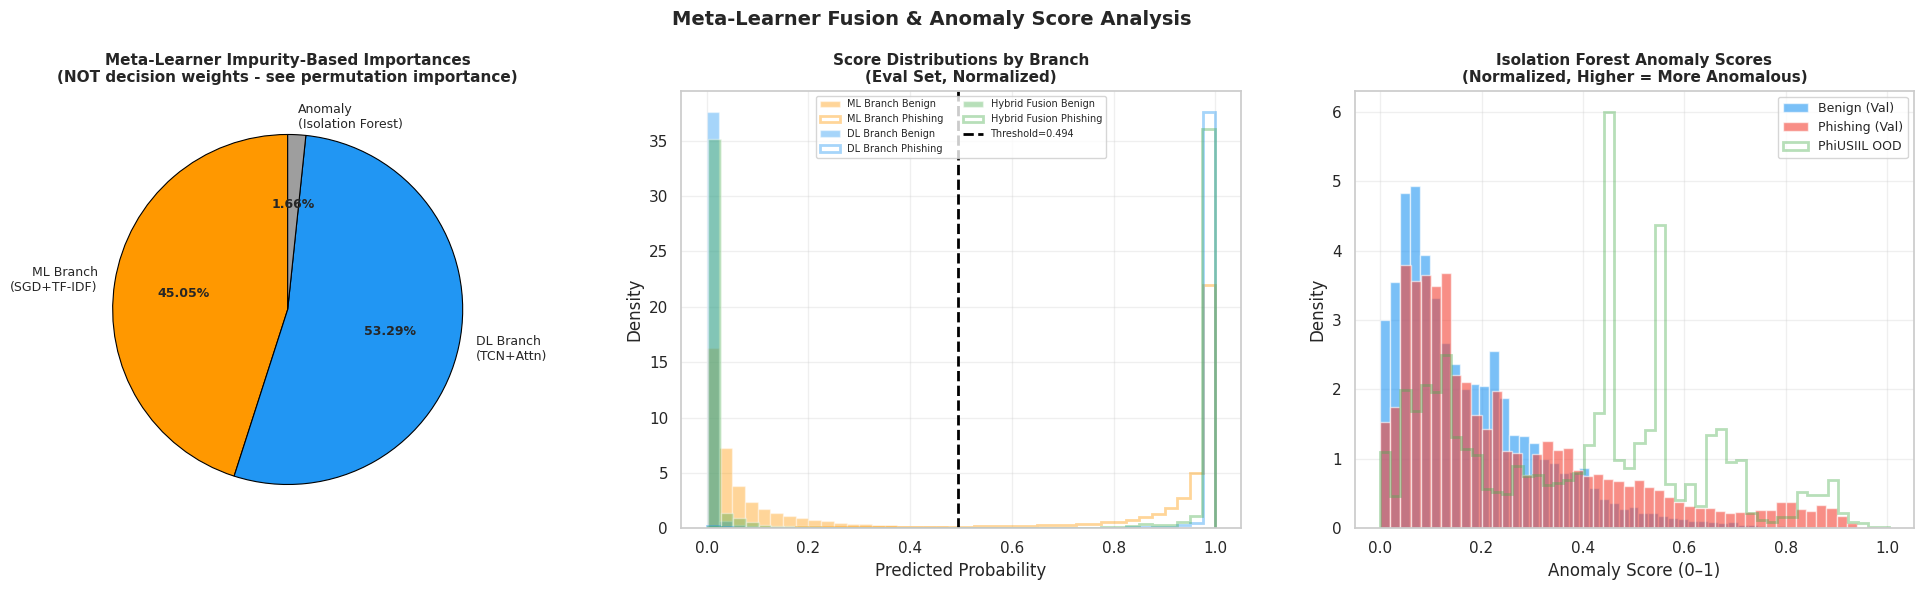

Saved → /content/drive/MyDrive/graph7_meta_anomaly_analysis.png


In [22]:
# ==========================================================
# GRAPH 7: META-LEARNER & ANOMALY ANALYSIS
# ==========================================================
print("\n================ GRAPH 7: META-LEARNER & ANOMALY ================")

fig, axes = plt.subplots(1, 3, figsize=(20, 6))
fig.suptitle("Meta-Learner Fusion & Anomaly Score Analysis", fontsize=14, fontweight='bold')

ax = axes[0]
meta_importance = meta_clf.feature_importances_
branch_names    = ['ML Branch\n(SGD+TF-IDF)', 'DL Branch\n(TCN+Attn)', 'Anomaly\n(Isolation Forest)']
colors_meta     = ['#FF9800', '#2196F3', '#9E9E9E']
wedges, texts, autotexts = ax.pie(
    meta_importance, labels=branch_names, colors=colors_meta,
    autopct='%1.2f%%', startangle=90,
    textprops={'fontsize': 9},
    wedgeprops={'edgecolor': 'black', 'linewidth': 0.8}
)
for at in autotexts:
    at.set_fontweight('bold')
ax.set_title("Meta-Learner Impurity-Based Importances\n(NOT decision weights - see permutation importance)", fontsize=11, fontweight='bold')

ax = axes[1]
for scores, name, color in [
    (p_ml_eval, 'ML Branch',     '#FF9800'),
    (p_dl_eval, 'DL Branch',     '#2196F3'),
    (S_eval,    'Hybrid Fusion', '#4CAF50'),
]:
    ax.hist(scores[eval_true==0], bins=40, alpha=0.4, color=color, label=f'{name} Benign',   density=True)
    ax.hist(scores[eval_true==1], bins=40, alpha=0.4, color=color, label=f'{name} Phishing', density=True,
            histtype='step', linewidth=2)
ax.axvline(best_thr, color='black', linestyle='--', linewidth=2, label=f'Threshold={best_thr:.3f}')
ax.set_title("Score Distributions by Branch\n(Eval Set, Normalized)", fontsize=11, fontweight='bold')
ax.set_xlabel("Predicted Probability"); ax.set_ylabel("Density")
ax.legend(fontsize=7, ncol=2); ax.grid(alpha=0.3)

ax = axes[2]
a_val_benign   = a_val[val_df.labels.values == 0]
a_val_phishing = a_val[val_df.labels.values == 1]
ax.hist(a_val_benign,   bins=50, alpha=0.6, color='#2196F3', label='Benign (Val)',   density=True)
ax.hist(a_val_phishing, bins=50, alpha=0.6, color='#F44336', label='Phishing (Val)', density=True)
ax.hist(a_phi, bins=50, alpha=0.4, color='#4CAF50', label='PhiUSIIL OOD', density=True,
        histtype='step', linewidth=2)
ax.set_title("Isolation Forest Anomaly Scores\n(Normalized, Higher = More Anomalous)",
             fontsize=11, fontweight='bold')
ax.set_xlabel("Anomaly Score (0–1)"); ax.set_ylabel("Density")
ax.legend(fontsize=9); ax.grid(alpha=0.3)

plt.tight_layout()
save_and_show("/content/drive/MyDrive/graph7_meta_anomaly_analysis.png")



================ GRAPH 8: DETAILED DRIFT ANALYSIS ================


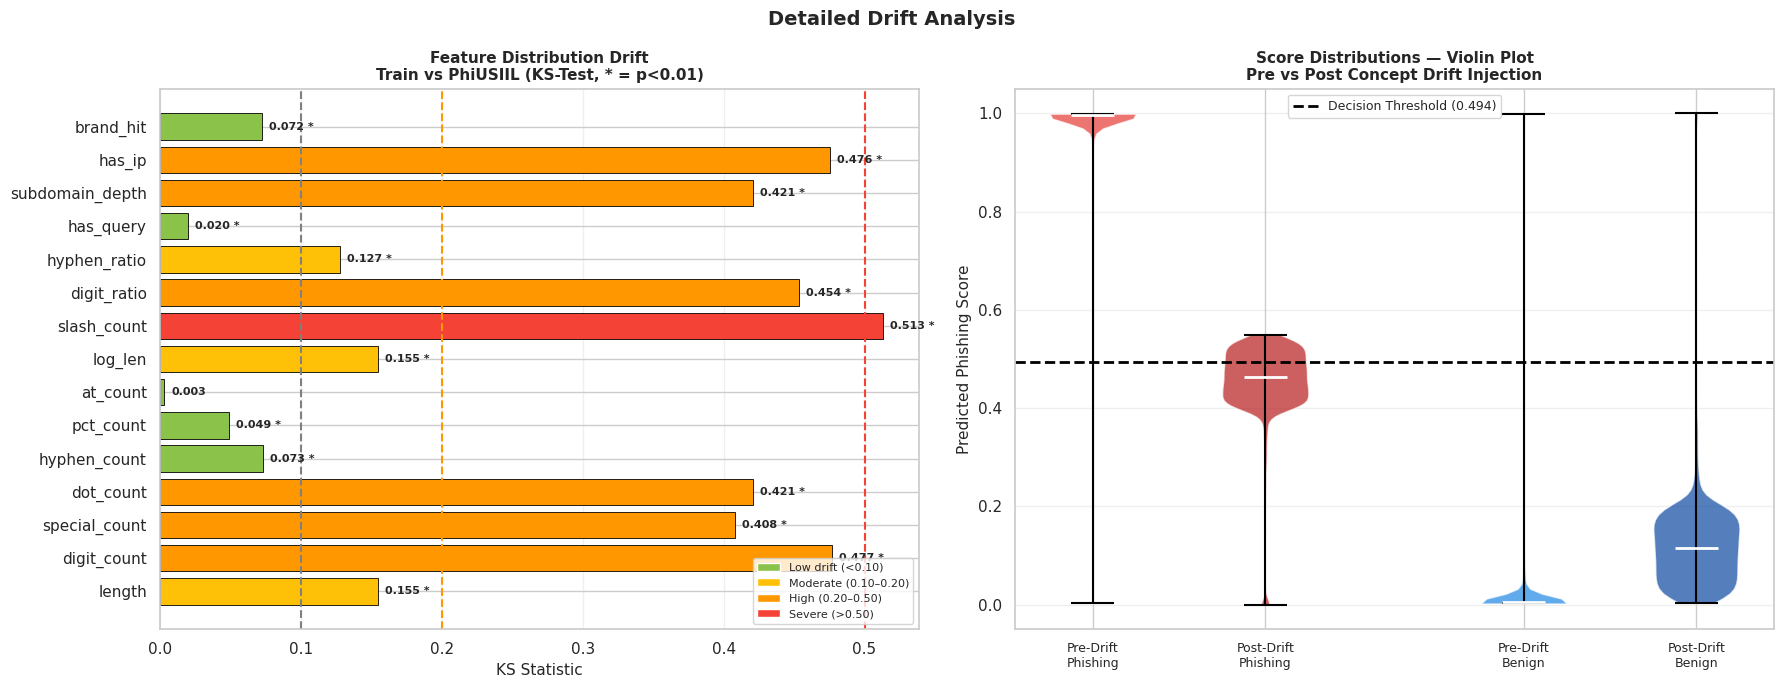

Saved → /content/drive/MyDrive/graph8_drift_detailed.png


In [23]:
# ==========================================================
# GRAPH 8: DETAILED DRIFT ANALYSIS
# ==========================================================
print("\n================ GRAPH 8: DETAILED DRIFT ANALYSIS ================")

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle("Detailed Drift Analysis", fontsize=14, fontweight='bold')

ax = axes[0]
all_ks_stats = []
all_ks_pvals = []
for i, name in enumerate(LEX_NAMES):
    stat, p = ks_2samp(X_lex_train[:, i], X_lex_phi[:, i])
    all_ks_stats.append(stat)
    all_ks_pvals.append(p)

bar_colors = ['#F44336' if s > 0.5 else '#FF9800' if s > 0.2 else '#FFC107' if s > 0.1 else '#8BC34A'
              for s in all_ks_stats]
bars = ax.barh(LEX_NAMES, all_ks_stats, color=bar_colors, edgecolor='black', linewidth=0.6)
ax.axvline(0.1, color='gray',    linestyle='--', linewidth=1.5)
ax.axvline(0.2, color='#FF9800', linestyle='--', linewidth=1.5)
ax.axvline(0.5, color='#F44336', linestyle='--', linewidth=1.5)
for bar, val, pv in zip(bars, all_ks_stats, all_ks_pvals):
    label = f'{val:.3f}' + (' *' if pv < 0.01 else '')
    ax.text(val + 0.005, bar.get_y() + bar.get_height()/2, label, va='center', fontsize=8, fontweight='bold')
ax.set_xlabel("KS Statistic", fontsize=11)
ax.set_title("Feature Distribution Drift\nTrain vs PhiUSIIL (KS-Test, * = p<0.01)", fontsize=11, fontweight='bold')
legend_patches = [
    mpatches.Patch(facecolor='#8BC34A', label='Low drift (<0.10)'),
    mpatches.Patch(facecolor='#FFC107', label='Moderate (0.10–0.20)'),
    mpatches.Patch(facecolor='#FF9800', label='High (0.20–0.50)'),
    mpatches.Patch(facecolor='#F44336', label='Severe (>0.50)'),
]
ax.legend(handles=legend_patches, fontsize=8, loc='lower right')
ax.grid(axis='x', alpha=0.3)

ax = axes[1]
pre_phish   = S_eval_sim[:drift_start][eval_df.labels.iloc[:drift_start].values == 1]
post_phish  = S_eval_sim[drift_start:][eval_df.labels.iloc[drift_start:].values == 1]
pre_benign  = S_eval_sim[:drift_start][eval_df.labels.iloc[:drift_start].values == 0]
post_benign = S_eval_sim[drift_start:][eval_df.labels.iloc[drift_start:].values == 0]

violin_data   = [pre_phish, post_phish, pre_benign, post_benign]
violin_pos    = [1, 2, 3.5, 4.5]
violin_labels = ['Pre-Drift\nPhishing', 'Post-Drift\nPhishing', 'Pre-Drift\nBenign', 'Post-Drift\nBenign']
violin_colors = ['#E53935', '#B71C1C', '#1E88E5', '#0D47A1']

parts = ax.violinplot(violin_data, positions=violin_pos, showmedians=True, showextrema=True)
for pc, color in zip(parts['bodies'], violin_colors):
    pc.set_facecolor(color); pc.set_alpha(0.7)
parts['cmedians'].set_color('white'); parts['cmedians'].set_linewidth(2)
parts['cmaxes'].set_color('black');   parts['cmins'].set_color('black')
parts['cbars'].set_color('black')
ax.axhline(best_thr, color='black', linestyle='--', linewidth=2, label=f'Decision Threshold ({best_thr:.3f})')
ax.set_xticks(violin_pos); ax.set_xticklabels(violin_labels, fontsize=9)
ax.set_ylabel("Predicted Phishing Score", fontsize=11)
ax.set_title("Score Distributions — Violin Plot\nPre vs Post Concept Drift Injection",
             fontsize=11, fontweight='bold')
ax.legend(fontsize=9); ax.grid(axis='y', alpha=0.3); ax.set_ylim(-0.05, 1.05)

plt.tight_layout()
save_and_show("/content/drive/MyDrive/graph8_drift_detailed.png")



================ GRAPH 9: THRESHOLD SENSITIVITY ================


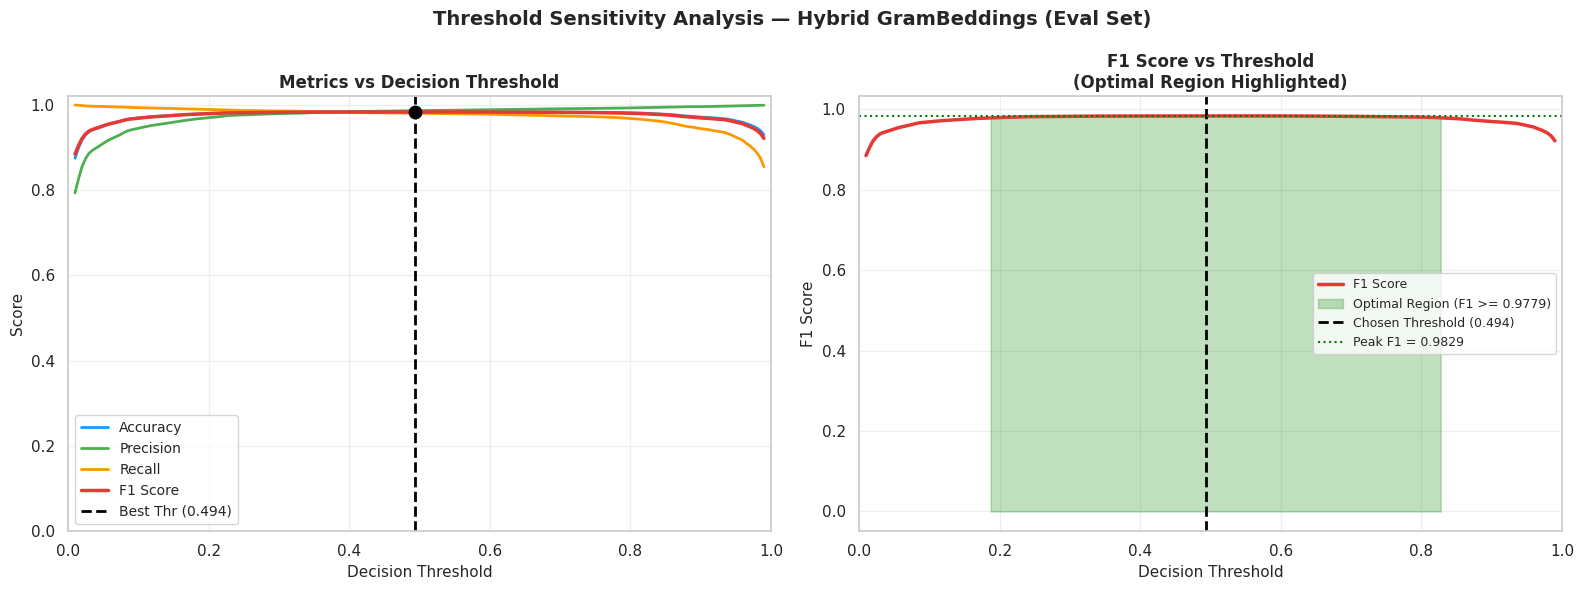

Saved → /content/drive/MyDrive/graph9_threshold_sensitivity.png


In [24]:
# ==========================================================
# GRAPH 9: THRESHOLD SENSITIVITY ANALYSIS
# ==========================================================
print("\n================ GRAPH 9: THRESHOLD SENSITIVITY ================")

thresholds  = np.linspace(0.01, 0.99, 200)
results_thr = {'acc': [], 'prec': [], 'rec': [], 'f1': []}
for thr in thresholds:
    yp = (S_eval > thr).astype(int)
    results_thr['acc'].append(accuracy_score(eval_true, yp))
    results_thr['prec'].append(precision_score(eval_true, yp, zero_division=0))
    results_thr['rec'].append(recall_score(eval_true, yp, zero_division=0))
    results_thr['f1'].append(f1_score(eval_true, yp, zero_division=0))

fig, axes = plt.subplots(1, 2, figsize=(16, 6))
fig.suptitle("Threshold Sensitivity Analysis — Hybrid GramBeddings (Eval Set)",
             fontsize=14, fontweight='bold')

ax = axes[0]
ax.plot(thresholds, results_thr['acc'],  color='#2196F3', linewidth=2, label='Accuracy')
ax.plot(thresholds, results_thr['prec'], color='#4CAF50', linewidth=2, label='Precision')
ax.plot(thresholds, results_thr['rec'],  color='#FF9800', linewidth=2, label='Recall')
ax.plot(thresholds, results_thr['f1'],   color='#E53935', linewidth=2.5, label='F1 Score')
ax.axvline(best_thr, color='black', linestyle='--', linewidth=2, label=f'Best Thr ({best_thr:.3f})')
ax.scatter([best_thr], [max(results_thr['f1'])], color='black', zorder=5, s=80)
ax.set_xlabel("Decision Threshold", fontsize=11); ax.set_ylabel("Score", fontsize=11)
ax.set_title("Metrics vs Decision Threshold", fontsize=12, fontweight='bold')
ax.legend(fontsize=10); ax.grid(alpha=0.3); ax.set_xlim(0, 1); ax.set_ylim(0, 1.02)

ax = axes[1]
f1_arr_thr  = np.array(results_thr['f1'])
best_f1_val = f1_arr_thr.max()
region_mask = f1_arr_thr >= best_f1_val - 0.005
ax.plot(thresholds, f1_arr_thr, color='#E53935', linewidth=2.5, label='F1 Score')
ax.fill_between(thresholds, f1_arr_thr, where=region_mask, alpha=0.25, color='green',
                label=f'Optimal Region (F1 >= {best_f1_val - 0.005:.4f})')
ax.axvline(best_thr, color='black', linestyle='--', linewidth=2, label=f'Chosen Threshold ({best_thr:.3f})')
ax.axhline(best_f1_val, color='green', linestyle=':', linewidth=1.5, label=f'Peak F1 = {best_f1_val:.4f}')
ax.set_xlabel("Decision Threshold", fontsize=11); ax.set_ylabel("F1 Score", fontsize=11)
ax.set_title("F1 Score vs Threshold\n(Optimal Region Highlighted)", fontsize=12, fontweight='bold')
ax.legend(fontsize=9); ax.grid(alpha=0.3); ax.set_xlim(0, 1)

plt.tight_layout()
save_and_show("/content/drive/MyDrive/graph9_threshold_sensitivity.png")



================ GRAPH 10: SUMMARY DASHBOARD ================


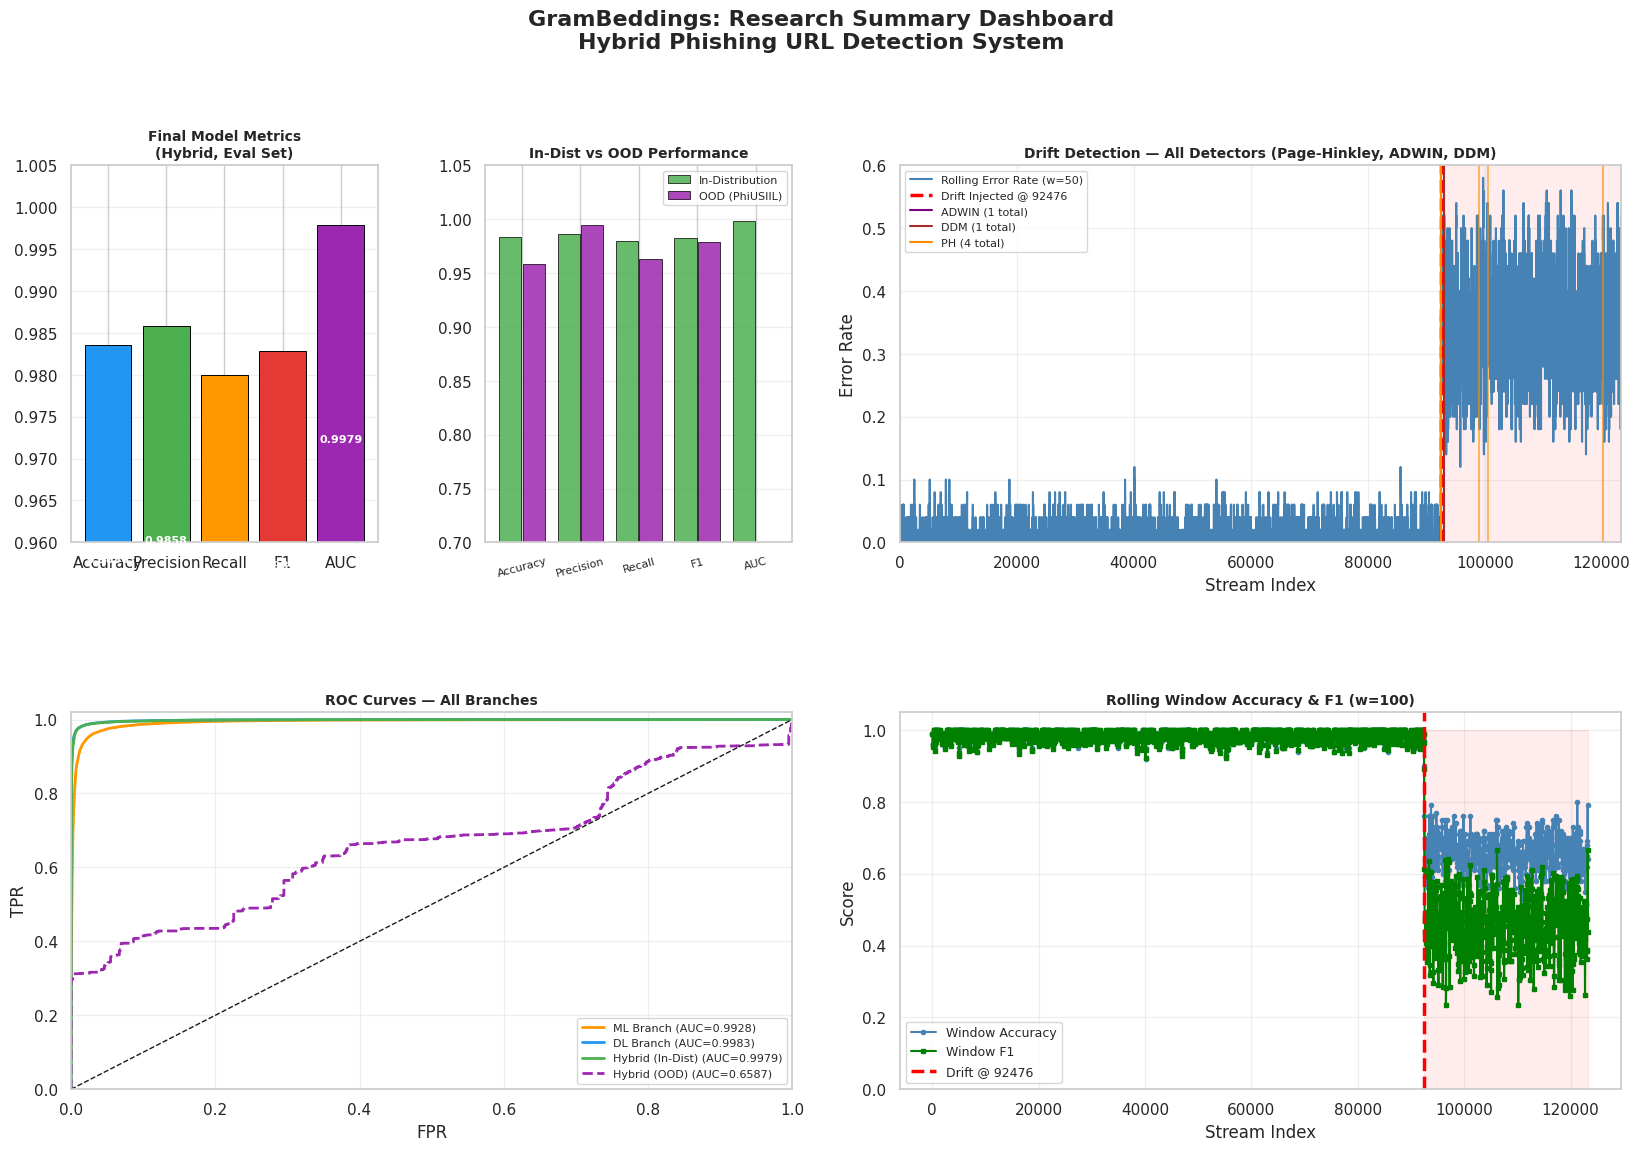

Saved → /content/drive/MyDrive/graph10_summary_dashboard.png

███████████████████████████████████████████████████████
  ACTIVE LEARNING LOOP WITH AUTOMATIC RETRAINING
███████████████████████████████████████████████████████

Config: budget=500, threshold=0.15, max_rounds=5


  DRIFT DETECTED at index 93060 → Retraining Round 1
  Queried 284 uncertain samples via oracle...
  Retraining ML branch...
    [ML]   partial_fit on 284 samples — done.
  Fine-tuning TCN+Attention...
    [DL]   Fine-tune epoch 1/2 | Loss: 0.0723
    [DL]   Fine-tune epoch 2/2 | Loss: 0.0199
    [Forgetting Probe] Val F1 before fine-tune: 0.9845 | after fine-tune: 0.9831 | delta: +0.0014
  Recomputing val branch scores...
  Retraining meta-learner...
    [Meta] Random Forest retrained on 123301 samples.
  Re-scoring remaining stream...
    [Post-retrain round 1] Accuracy: 0.6413 | F1: 0.4812  (n=499, leakage-free)
    [Leakage Guard] Excluded 1/500 samples from this window — they were oracle-queried (this or an ear

In [25]:
# ==========================================================
# GRAPH 10: RESEARCH SUMMARY DASHBOARD
# ==========================================================
print("\n================ GRAPH 10: SUMMARY DASHBOARD ================")

fig = plt.figure(figsize=(20, 12))
fig.suptitle("GramBeddings: Research Summary Dashboard\nHybrid Phishing URL Detection System",
             fontsize=16, fontweight='bold', y=1.01)

gs = fig.add_gridspec(2, 4, hspace=0.45, wspace=0.35)

ax_a = fig.add_subplot(gs[0, 0])
final_metrics = {
    'Accuracy':  accuracy_score(eval_true, yhat_eval),
    'Precision': precision_score(eval_true, yhat_eval),
    'Recall':    recall_score(eval_true, yhat_eval),
    'F1':        f1_score(eval_true, yhat_eval),
}
fpr_f, tpr_f, _ = roc_curve(eval_true, S_eval)
final_metrics['AUC'] = auc(fpr_f, tpr_f)
colors_bar = ['#2196F3','#4CAF50','#FF9800','#E53935','#9C27B0']
bars = ax_a.bar(final_metrics.keys(), final_metrics.values(), color=colors_bar,
                edgecolor='black', linewidth=0.7)
for bar, val in zip(bars, final_metrics.values()):
    ax_a.text(bar.get_x() + bar.get_width()/2, bar.get_height() - 0.025,
              f'{val:.4f}', ha='center', va='top', fontsize=8, fontweight='bold', color='white')
ax_a.set_ylim(0.96, 1.005)
ax_a.set_title("Final Model Metrics\n(Hybrid, Eval Set)", fontsize=10, fontweight='bold')
ax_a.grid(axis='y', alpha=0.3)

ax_b = fig.add_subplot(gs[0, 1])
categories = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']
ind_vals   = [accuracy_score(eval_true, yhat_eval), precision_score(eval_true, yhat_eval),
              recall_score(eval_true, yhat_eval),   f1_score(eval_true, yhat_eval), auc(fpr_f, tpr_f)]
phi_true   = phi_df.labels.values
fpr_p, tpr_p, _ = roc_curve(phi_true, S_phi)
ood_vals   = [accuracy_score(phi_true, yhat_phi), precision_score(phi_true, yhat_phi),
              recall_score(phi_true, yhat_phi),   f1_score(phi_true, yhat_phi), auc(fpr_p, tpr_p)]
x_pos = np.arange(len(categories))
ax_b.bar(x_pos - 0.2, ind_vals, 0.38, label='In-Distribution', color='#4CAF50', alpha=0.85,
         edgecolor='black', linewidth=0.6)
ax_b.bar(x_pos + 0.2, ood_vals, 0.38, label='OOD (PhiUSIIL)',  color='#9C27B0', alpha=0.85,
         edgecolor='black', linewidth=0.6)
ax_b.set_xticks(x_pos); ax_b.set_xticklabels(categories, fontsize=8, rotation=15)
ax_b.set_ylim(0.7, 1.05)
ax_b.set_title("In-Dist vs OOD Performance", fontsize=10, fontweight='bold')
ax_b.legend(fontsize=8); ax_b.grid(axis='y', alpha=0.3)

ax_c = fig.add_subplot(gs[0, 2:])
roll_err2 = pd.Series(rolling_errors).rolling(50, min_periods=1).mean()
ax_c.plot(roll_err2, color='steelblue', linewidth=1.5, label='Rolling Error Rate (w=50)')
ax_c.axvline(drift_start, color='red', linestyle='--', linewidth=2.5, label=f'Drift Injected @ {drift_start}')
for d in adwin_drifts[:5]: ax_c.axvline(d, color='purple',     alpha=0.7, linewidth=1.2)
for d in ddm_drifts[:5]:   ax_c.axvline(d, color='brown',      alpha=0.7, linewidth=1.2)
for d in ph_drifts[:5]:    ax_c.axvline(d, color='darkorange', alpha=0.7, linewidth=1.2)
if adwin_drifts: ax_c.axvline(adwin_drifts[0], color='purple',     linewidth=1.5, label=f'ADWIN ({len(adwin_drifts)} total)')
if ddm_drifts:   ax_c.axvline(ddm_drifts[0],   color='brown',      linewidth=1.5, label=f'DDM ({len(ddm_drifts)} total)')
if ph_drifts:    ax_c.axvline(ph_drifts[0],    color='darkorange', linewidth=1.5, label=f'PH ({len(ph_drifts)} total)')
ax_c.fill_between(range(drift_start, n_eval), 0, 1, alpha=0.07, color='red')
ax_c.set_xlabel("Stream Index"); ax_c.set_ylabel("Error Rate")
ax_c.set_title("Drift Detection — All Detectors (Page-Hinkley, ADWIN, DDM)", fontsize=10, fontweight='bold')
ax_c.legend(fontsize=8); ax_c.set_xlim(0, n_eval); ax_c.set_ylim(0, 0.6); ax_c.grid(alpha=0.3)

ax_d = fig.add_subplot(gs[1, 0:2])
for name, scores, true, color, ls in [
    ("ML Branch",        p_ml_eval, eval_true,         '#FF9800', '-'),
    ("DL Branch",        p_dl_eval, eval_true,         '#2196F3', '-'),
    ("Hybrid (In-Dist)", S_eval,    eval_true,         '#4CAF50', '-'),
    ("Hybrid (OOD)",     S_phi,     phi_df.labels.values, '#9C27B0', '--'),
]:
    fpr_, tpr_, _ = roc_curve(true, scores)
    ax_d.plot(fpr_, tpr_, color=color, linewidth=2, linestyle=ls,
              label=f'{name} (AUC={auc(fpr_, tpr_):.4f})')
ax_d.plot([0,1],[0,1],'k--',linewidth=1)
ax_d.set_xlim(0,1); ax_d.set_ylim(0,1.02)
ax_d.set_xlabel("FPR"); ax_d.set_ylabel("TPR")
ax_d.set_title("ROC Curves — All Branches", fontsize=10, fontweight='bold')
ax_d.legend(fontsize=8, loc='lower right'); ax_d.grid(alpha=0.3)

ax_e = fig.add_subplot(gs[1, 2:])
ax_e.plot(win_idx, win_acc, marker='o', markersize=3, color='steelblue', linewidth=1.5, label='Window Accuracy')
ax_e.plot(win_idx, win_f1,  marker='s', markersize=3, color='green',     linewidth=1.5, label='Window F1')
ax_e.axvline(drift_start, color='red', linestyle='--', linewidth=2.5, label=f'Drift @ {drift_start}')
ax_e.fill_between([drift_start, n_eval], 0, 1, alpha=0.07, color='red')
ax_e.set_xlabel("Stream Index"); ax_e.set_ylabel("Score")
ax_e.set_title(f"Rolling Window Accuracy & F1 (w={win_size})", fontsize=10, fontweight='bold')
ax_e.legend(fontsize=9); ax_e.set_ylim(0, 1.05); ax_e.grid(alpha=0.3)

save_and_show("/content/drive/MyDrive/graph10_summary_dashboard.png")


# ==========================================================
# ACTIVE LEARNING LOOP
# ==========================================================
print("\n" + "█"*55)
print("  ACTIVE LEARNING LOOP WITH AUTOMATIC RETRAINING")
print("█"*55)

# ==========================================================
# ALGORITHM: Zero-Leakage Active Learning Loop
# (Addresses reviewer point 3 — oracle protocol + evaluation leakage)
#
#   Notation:
#     E              : the eval stream (eval_df), indices 0..n_eval-1
#     Q              : global set of ALL indices ever queried+labeled by
#                       the oracle across ALL retraining rounds so far
#                       (Q starts empty, only grows, never resets)
#     Oracle(idx)     : returns eval_df.labels.iloc[idx] — i.e. the oracle
#                       is a SIMULATED ground-truth lookup on the held-out
#                       test set, not a human or external labeling service.
#                       This is made explicit so results are read as a
#                       simulation of an oracle-labeling budget, not as
#                       genuinely-unlabeled production data.
#
#   for i in 0 .. n_eval-1:
#       observe (score_i, true_i, pred_i) from the current stream state
#       update drift detectors (Page-Hinkley, ADWIN, DDM) with the error
#       if drift triggered AND rounds_used < max_rounds:
#           1. window   <- indices [i-2000, i+500) ∩ [0, n_eval)
#           2. g_idx    <- uncertainty_sample(window, budget=500)   # subset of `window`
#           3. Q        <- Q ∪ g_idx                                 # <-- accumulate, never forget
#           4. labels   <- Oracle(g_idx)                             # simulated oracle read
#           5. retrain SGD.partial_fit(features[g_idx], labels)
#              fine-tune TCN on (urls[g_idx], labels)
#              rebuild meta-learner RF on val_df (never touched by AL)
#           6. re-score stream[i:] with the updated models
#           7. EVALUATION BOUNDARY (this is the leakage fix):
#                report_window <- [i, i+500) \ Q     # remove ANY index
#                                                       ever queried, in
#                                                       this round or any
#                                                       earlier round
#                post_acc, post_f1 <- metrics(stream_true[report_window],
#                                              stream_pred[report_window])
#              Only `report_window` (never-queried indices) is used for
#              any reported accuracy/F1 — a sample that was ever used to
#              update SGD/TCN/meta is permanently excluded from every
#              subsequent "test" metric, not just the round it was drawn in.
#
#   After the loop: Graphs 11 and 13 ("with AL" curves/metrics) are
#   computed ONLY over indices not in Q (see `al_queried_mask` below),
#   so the reported drift-recovery numbers never include a sample the
#   models were trained on.
# ==========================================================

# FIX-2: re-apply the SAME score perturbation to the re-scored stream after every retraining round.
# True  = fair, equivalent pre/post-retraining conditions (use this for the paper).
# False = old behaviour (re-scored stream is clean -> recovery is partly an artefact).
REAPPLY_PERTURBATION_AFTER_RETRAIN = True

# FIX-3 companion: after a drift trigger wait this many samples, then query the oracle on the
# CAUSAL window [i-2000, i] (the old code instead queried the next 500 UNSEEN samples).
AL_COLLECT_AFTER_TRIGGER = 500
al_armed_at = None

AL_CONFIG = {
    "uncertainty_budget"   : 500,
    "confidence_threshold" : 0.15,
    "min_drift_triggers"   : 1,
    "max_rounds"           : 5,
    "tcn_finetune_epochs"  : 2,
    "tcn_finetune_lr"      : 1e-4,
    "batch_size"           : 128,
    "window_size"          : 100,
}

def oracle_label(indices, true_labels_series):
    return true_labels_series.iloc[indices].values

def uncertainty_sample(scores, budget, threshold):
    uncertainty    = 1 - np.abs(scores - 0.5) * 2
    uncertain_mask = np.abs(scores - 0.5) < threshold
    candidates     = np.where(uncertain_mask)[0]
    if len(candidates) == 0:
        candidates = np.argsort(uncertainty)[::-1][:budget]
    elif len(candidates) > budget:
        ranked     = candidates[np.argsort(uncertainty[candidates])[::-1]]
        candidates = ranked[:budget]
    return candidates

def retrain_ml_branch(clf_model, new_X_ml, new_y):
    clf_model.partial_fit(new_X_ml, new_y, classes=[0, 1])
    print(f"    [ML]   partial_fit on {len(new_y)} samples — done.")
    return clf_model

# ── FIXED finetune_tcn: use .squeeze(1) and .view(-1) to handle batch-size-1 ──
def finetune_tcn(net, new_urls, new_y_array, config, device):
    new_y_series = pd.Series(new_y_array)
    # drop_last only if dataset is larger than one batch to avoid empty loader
    do_drop = len(new_y_array) > config["batch_size"]
    ft_dl = DataLoader(
        URLDS(new_urls, new_y_series),
        batch_size=config["batch_size"],
        shuffle=True,
        drop_last=do_drop,
    )
    ft_opt   = torch.optim.Adam(net.parameters(), lr=config["tcn_finetune_lr"])
    ft_lossf = nn.BCEWithLogitsLoss()
    net.train()
    for ep in range(config["tcn_finetune_epochs"]):
        total = 0
        for X_b, y_b in ft_dl:
            X_b, y_b = X_b.to(device), y_b.to(device)
            ft_opt.zero_grad()
            logits = net(X_b).view(-1)   # safe reshape regardless of batch size
            y_b    = y_b.view(-1)
            loss   = ft_lossf(logits, y_b)
            loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            ft_opt.step()
            total += loss.item()
        print(f"    [DL]   Fine-tune epoch {ep+1}/{config['tcn_finetune_epochs']} "
              f"| Loss: {total/max(len(ft_dl),1):.4f}")
    return net

def retrain_meta(p_ml, p_dl, p_anom, y_true):
    meta_X = np.column_stack([p_ml, p_dl, p_anom])
    new_meta = RandomForestClassifier(
        n_estimators=200, max_depth=6,
        class_weight='balanced', random_state=42, n_jobs=-1
    )
    new_meta.fit(meta_X, y_true)
    print(f"    [Meta] Random Forest retrained on {len(y_true)} samples.")
    return new_meta

def evaluate_window(y_true_arr, y_pred_arr, label=""):
    # Leakage-aware: caller is expected to have already stripped out any
    # index that was ever oracle-queried (see al_queried_indices_global).
    # An empty window (rare — only if every sample in the report window
    # happened to be queried) is reported as NaN rather than silently
    # scored, so it can't be mistaken for a real metric.
    if len(y_true_arr) == 0:
        print(f"    [{label}] 0 leakage-free samples in this window — metric skipped (NaN).")
        return float('nan'), float('nan')
    acc = accuracy_score(y_true_arr, y_pred_arr)
    f1v = f1_score(y_true_arr, y_pred_arr, zero_division=0)
    print(f"    [{label}] Accuracy: {acc:.4f} | F1: {f1v:.4f}  (n={len(y_true_arr)}, leakage-free)")
    return acc, f1v

al_clf      = copy.deepcopy(clf)
al_model    = copy.deepcopy(model)
al_meta_clf = copy.deepcopy(meta_clf)

al_adwin = ADWIN(delta=0.002, min_window=30, max_window=1000)
al_ddm   = DDM(warning_level=2.0, drift_level=3.0)
al_ph    = PageHinkley(delta=0.005, lam=8)

stream_scores = S_eval_sim.copy()
stream_true   = eval_df.labels.values.copy()
stream_preds  = yhat_sim.copy()

drift_trigger_count = 0
retraining_rounds   = 0
round_log           = []

# Global, ever-growing set of every index the oracle has EVER labeled for
# retraining, across all rounds. Used to strip leaked samples out of every
# reported "test" metric from this point on (see algorithm box above).
al_queried_indices_global = set()

print(f"\nConfig: budget={AL_CONFIG['uncertainty_budget']}, "
      f"threshold={AL_CONFIG['confidence_threshold']}, "
      f"max_rounds={AL_CONFIG['max_rounds']}\n")

for i in range(n_eval):
    score      = stream_scores[i]
    true_label = stream_true[i]
    pred_label = stream_preds[i]
    err        = int(pred_label != true_label)

    al_ph.update(1 - abs(score - best_thr))
    adwin_fired = al_adwin.update(float(err))
    ddm_status  = al_ddm.update(err)

    if adwin_fired or ddm_status == "DRIFT":
        drift_trigger_count += 1

    if drift_trigger_count >= AL_CONFIG["min_drift_triggers"] and al_armed_at is None:
        al_armed_at = i + AL_COLLECT_AFTER_TRIGGER

    if (al_armed_at is not None and i >= al_armed_at
            and retraining_rounds < AL_CONFIG["max_rounds"]):

        print(f"\n{'='*55}")
        print(f"  DRIFT DETECTED at index {i} → Retraining Round {retraining_rounds+1}")
        print(f"{'='*55}")

        w_start  = max(0, i - 2000)
        w_end    = min(n_eval, i + 1)   # FIX-3: causal window - only samples already seen (was i + 500)
        w_scores = stream_scores[w_start:w_end]
        q_indices = uncertainty_sample(
            w_scores, AL_CONFIG["uncertainty_budget"],
            AL_CONFIG["confidence_threshold"]
        )
        g_indices = q_indices + w_start
        print(f"  Queried {len(g_indices)} uncertain samples via oracle...")

        # Leakage tracking: these indices are now permanently "spent" —
        # they were used to update model weights and must never again
        # contribute to a reported test/eval metric.
        al_queried_indices_global.update(g_indices.tolist())

        q_labels = oracle_label(g_indices, eval_df.labels)
        q_urls   = eval_df.url.iloc[g_indices].values

        # PERF FIX: reuse precomputed eval-set features instead of
        # recomputing tfidf.transform() / lexical_features() for the
        # queried subset — these were already computed once for the
        # full eval set in Steps 2-3, and tfidf/scaler_lex are never
        # refit during AL, so slicing gives numerically identical
        # results to recomputation.
        X_ng_q  = X_ng_eval[g_indices]
        X_lex_q = X_lex_eval[g_indices]
        X_ml_q  = hstack([X_ng_q, X_lex_q]).tocsr()

        print("  Retraining ML branch...")
        al_clf = retrain_ml_branch(al_clf, X_ml_q, q_labels)

        # ADDED: catastrophic-forgetting probe — TCN performance on the
        # untouched validation set (val_df, never queried by AL) BEFORE
        # this round's fine-tuning update.
        pre_ft_val_f1 = f1_score(
            val_df.labels.values, (dl_scores(val_dl, net=al_model) > 0.5).astype(int)
        )

        print("  Fine-tuning TCN+Attention...")
        al_model = finetune_tcn(
            al_model, pd.Series(q_urls), q_labels, AL_CONFIG, device
        )

        # ADDED: same validation set AFTER fine-tuning — the gap between
        # pre_ft_val_f1 and post_ft_val_f1 quantifies forgetting of the
        # original (pre-drift) distribution caused by this round's update.
        post_ft_val_f1 = f1_score(
            val_df.labels.values, (dl_scores(val_dl, net=al_model) > 0.5).astype(int)
        )
        print(f"    [Forgetting Probe] Val F1 before fine-tune: {pre_ft_val_f1:.4f} | "
              f"after fine-tune: {post_ft_val_f1:.4f} | "
              f"delta: {pre_ft_val_f1 - post_ft_val_f1:+.4f}")

        print("  Recomputing val branch scores...")
        p_ml_val_new = al_clf.predict_proba(X_val_ml)[:, 1]

        al_model.eval()
        p_dl_val_new_arr = []
        with torch.no_grad():
            for X_b, _ in val_dl:
                p_dl_val_new_arr.extend(
                    torch.sigmoid(al_model(X_b.to(device))).cpu().numpy()
                )
        p_dl_val_new = np.array(p_dl_val_new_arr)

        print("  Retraining meta-learner...")
        al_meta_clf = retrain_meta(
            p_ml_val_new, p_dl_val_new, a_val, val_df.labels.values
        )

        print("  Re-scoring remaining stream...")
        rem_urls  = eval_df.url.iloc[i:].values

        # PERF FIX: slice precomputed eval-set TF-IDF/lexical features
        # instead of recomputing tfidf.transform()/lexical_features() on
        # the remaining stream every round (these features are static —
        # only the classifiers change round to round).
        X_ng_rem  = X_ng_eval[i:]
        X_lex_rem = X_lex_eval[i:]
        X_ml_rem  = hstack([X_ng_rem, X_lex_rem]).tocsr()
        p_ml_rem  = al_clf.predict_proba(X_ml_rem)[:, 1]

        rem_series = pd.Series(rem_urls)
        rem_y_ser  = eval_df.labels.iloc[i:].reset_index(drop=True)
        rem_dl_new = DataLoader(
            URLDS(rem_series, rem_y_ser), batch_size=512, shuffle=False
        )
        p_dl_rem_arr = []
        al_model.eval()
        with torch.no_grad():
            for X_b, _ in rem_dl_new:
                p_dl_rem_arr.extend(
                    torch.sigmoid(al_model(X_b.to(device))).cpu().numpy()
                )
        p_dl_rem = np.array(p_dl_rem_arr)

        # PERF FIX: Isolation Forest anomaly scores over the remaining
        # stream are static (iso / scaler_anom are never retrained during
        # AL) — reuse the precomputed a_eval slice instead of recomputing
        # iso.score_samples() every round.
        a_rem = a_eval[i:]

        meta_X_rem    = np.column_stack([p_ml_rem, p_dl_rem, a_rem])
        S_rem_updated = al_meta_clf.predict_proba(meta_X_rem)[:, 1]

        if REAPPLY_PERTURBATION_AFTER_RETRAIN:
            S_rem_updated = perturb_scores(S_rem_updated, i)   # FIX-2
        stream_scores[i:] = S_rem_updated
        stream_preds[i:]  = (S_rem_updated > best_thr).astype(int)

        # LEAKAGE FIX: strip out every index ever oracle-queried (this round
        # OR any earlier round) before computing the "post-retrain" metric.
        # The naive window [i, i+500) can and does overlap with g_indices
        # (the query window extends to i+500 too), so without this filter
        # samples that were just used to update SGD/TCN/meta would be
        # scored as if they were held-out test data.
        report_end   = min(i + 500, n_eval)
        report_range = np.arange(i, report_end)
        queried_arr  = np.fromiter(al_queried_indices_global, dtype=int) if al_queried_indices_global else np.array([], dtype=int)
        leak_free_mask = ~np.isin(report_range, queried_arr)
        clean_report_idx = report_range[leak_free_mask]
        n_excluded_leaked = len(report_range) - len(clean_report_idx)

        ev_true = stream_true[clean_report_idx]
        ev_pred = stream_preds[clean_report_idx]
        acc_r, f1_r = evaluate_window(
            ev_true, ev_pred, f"Post-retrain round {retraining_rounds+1}"
        )
        if n_excluded_leaked > 0:
            print(f"    [Leakage Guard] Excluded {n_excluded_leaked}/{len(report_range)} "
                  f"samples from this window — they were oracle-queried (this or an earlier round).")

        round_log.append({
            "round"             : retraining_rounds + 1,
            "drift_index"       : i,
            "queried"           : len(g_indices),
            "queried_indices"   : g_indices.tolist(),  # exact oracle-labeled indices, needed for zero-leakage post-AL evaluation
            "post_acc"          : acc_r,               # computed ONLY on indices never queried (leakage-free)
            "post_f1"           : f1_r,                # computed ONLY on indices never queried (leakage-free)
            "n_report_window"   : len(report_range),
            "n_excluded_leaked" : n_excluded_leaked,
            "pre_ft_val_f1"     : pre_ft_val_f1,   # catastrophic-forgetting probe (before fine-tune)
            "post_ft_val_f1"    : post_ft_val_f1,  # catastrophic-forgetting probe (after fine-tune)
        })

        al_adwin = ADWIN(delta=0.002, min_window=30, max_window=1000)
        al_ddm   = DDM(warning_level=2.0, drift_level=3.0)
        al_ph    = PageHinkley(delta=0.005, lam=8)
        drift_trigger_count = 0
        al_armed_at         = None
        retraining_rounds  += 1

print(f"\n{'='*55}")
print(f"  ACTIVE LEARNING LOOP COMPLETE")
print(f"  Total retraining rounds : {retraining_rounds}")
print(f"{'='*55}")
print(f"\n  {'Round':<8} {'Drift@':<10} {'Queried':<10} {'Post-Acc':<12} {'Post-F1'}")
print(f"  {'-'*52}")
for r in round_log:
    print(f"  {r['round']:<8} {r['drift_index']:<10} {r['queried']:<10} "
          f"{r['post_acc']:<12.4f} {r['post_f1']:.4f}")

# ── Global leakage mask: True for any index ever used to update a model ──
# Used below (Graphs 11 & 13) so every "with AL" performance curve/number
# is computed strictly on samples the models never trained on.
al_queried_mask = np.zeros(n_eval, dtype=bool)
if al_queried_indices_global:
    al_queried_mask[np.fromiter(al_queried_indices_global, dtype=int)] = True

print(f"\n  Leakage summary: {al_queried_mask.sum()} / {n_eval} eval-stream samples "
      f"({al_queried_mask.mean()*100:.2f}%) were oracle-queried at some point and are "
      f"EXCLUDED from all downstream 'with AL' evaluation curves/metrics (Graphs 11 & 13).")



================ NEW GRAPH 11: AL RECOVERY PLOT ================


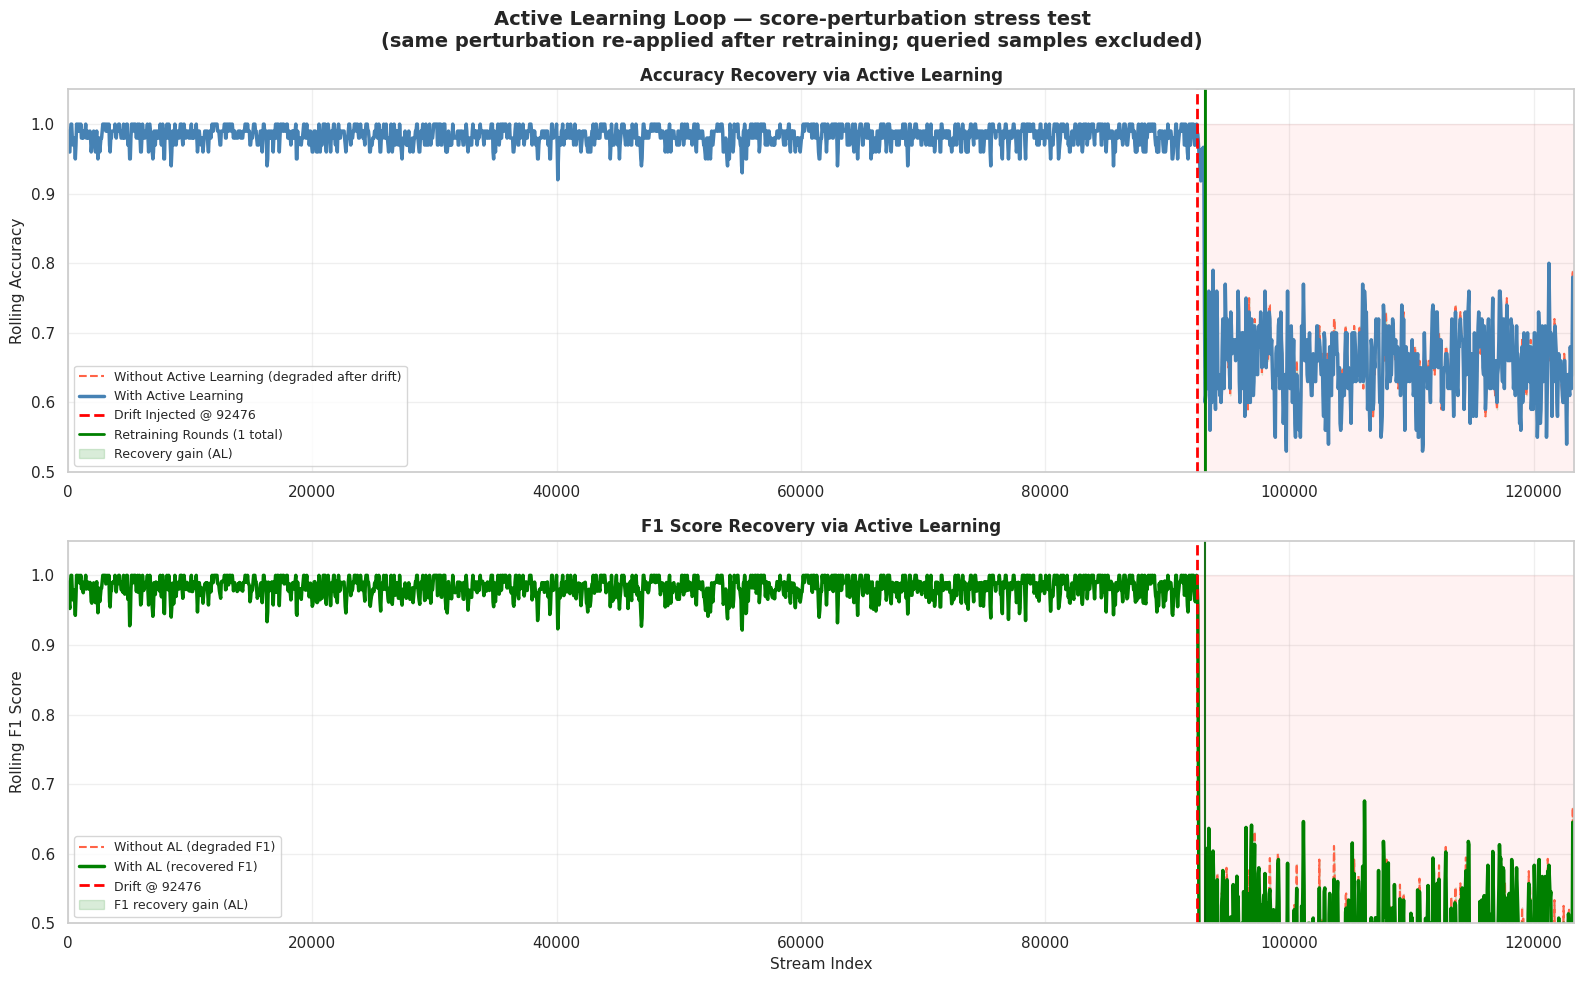

Saved → /content/drive/MyDrive/graph11_al_recovery.png


In [26]:
# ==========================================================
# NEW GRAPH 11: ACTIVE LEARNING — RECOVERY PLOT
# ==========================================================
print("\n================ NEW GRAPH 11: AL RECOVERY PLOT ================")

win_al = 100

# LEAKAGE FIX: both curves below are computed only on indices that were
# NEVER oracle-queried (al_queried_mask), and on the SAME clean index set
# per window, so "with AL" vs "without AL" is an apples-to-apples,
# leakage-free comparison rather than partly scoring the with-AL curve on
# samples its own models were just trained on.
al_win_acc, al_win_f1, al_win_idx = [], [], []
no_al_acc,  no_al_f1              = [], []
for start in range(0, n_eval - win_al, win_al // 2):
    end       = start + win_al
    idx_range = np.arange(start, end)
    clean_idx = idx_range[~al_queried_mask[idx_range]]
    if len(clean_idx) == 0:
        continue
    yt = stream_true[clean_idx]
    if len(np.unique(yt)) < 2:
        continue

    yp_al = stream_preds[clean_idx]
    al_win_acc.append(accuracy_score(yt, yp_al))
    al_win_f1.append(f1_score(yt, yp_al, zero_division=0))
    al_win_idx.append(start + win_al // 2)

    yp_no_al = yhat_sim[clean_idx]
    no_al_acc.append(accuracy_score(yt, yp_no_al))
    no_al_f1.append(f1_score(yt, yp_no_al, zero_division=0))

fig, axes = plt.subplots(2, 1, figsize=(16, 10))
fig.suptitle("Active Learning Loop — score-perturbation stress test\n(same perturbation re-applied after retraining; queried samples excluded)",
             fontsize=14, fontweight='bold')

ax = axes[0]
ax.plot(al_win_idx, no_al_acc, color='tomato',    linewidth=1.5, linestyle='--',
        label='Without Active Learning (degraded after drift)')
ax.plot(al_win_idx, al_win_acc, color='steelblue', linewidth=2.5,
        label='With Active Learning')
ax.axvline(drift_start, color='red', linestyle='--', linewidth=2,
           label=f'Drift Injected @ {drift_start}')
for r in round_log:
    ax.axvline(r['drift_index'], color='green', linewidth=1.5, alpha=0.9)
if round_log:
    ax.axvline(round_log[0]['drift_index'], color='green', linewidth=2,
               label=f'Retraining Rounds ({len(round_log)} total)')
ax.fill_between(range(drift_start, n_eval), 0, 1, alpha=0.05, color='red')
if round_log:
    first_retrain = round_log[0]['drift_index']
    ax.fill_between(al_win_idx,
                    no_al_acc[:len(al_win_idx)],
                    al_win_acc[:len(al_win_idx)],
                    where=[x >= first_retrain for x in al_win_idx],
                    alpha=0.15, color='green', label='Recovery gain (AL)')
ax.set_ylabel("Rolling Accuracy", fontsize=11)
ax.set_title("Accuracy Recovery via Active Learning", fontsize=12, fontweight='bold')
ax.legend(fontsize=9); ax.set_ylim(0.5, 1.05); ax.set_xlim(0, n_eval); ax.grid(alpha=0.3)

ax = axes[1]
ax.plot(al_win_idx, no_al_f1,  color='tomato',  linewidth=1.5, linestyle='--',
        label='Without AL (degraded F1)')
ax.plot(al_win_idx, al_win_f1, color='green',   linewidth=2.5,
        label='With AL (recovered F1)')
ax.axvline(drift_start, color='red', linestyle='--', linewidth=2,
           label=f'Drift @ {drift_start}')
for r in round_log:
    ax.axvline(r['drift_index'], color='darkgreen', linewidth=1.5, alpha=0.9)
    ax.annotate(
        f"Round {r['round']}\nF1={r['post_f1']:.3f}",
        xy=(r['drift_index'], r['post_f1']),
        xytext=(r['drift_index'] + 800, r['post_f1'] - 0.07),
        fontsize=8, color='darkgreen',
        arrowprops=dict(arrowstyle='->', color='darkgreen', lw=1.2)
    )
if round_log:
    first_retrain = round_log[0]['drift_index']
    ax.fill_between(al_win_idx,
                    no_al_f1[:len(al_win_idx)],
                    al_win_f1[:len(al_win_idx)],
                    where=[x >= first_retrain for x in al_win_idx],
                    alpha=0.15, color='green', label='F1 recovery gain (AL)')
ax.fill_between(range(drift_start, n_eval), 0, 1, alpha=0.05, color='red')
ax.set_xlabel("Stream Index", fontsize=11); ax.set_ylabel("Rolling F1 Score", fontsize=11)
ax.set_title("F1 Score Recovery via Active Learning", fontsize=12, fontweight='bold')
ax.legend(fontsize=9); ax.set_ylim(0.5, 1.05); ax.set_xlim(0, n_eval); ax.grid(alpha=0.3)

plt.tight_layout()
save_and_show("/content/drive/MyDrive/graph11_al_recovery.png")



================ NEW GRAPH 12: AL ROUND ANALYSIS ================


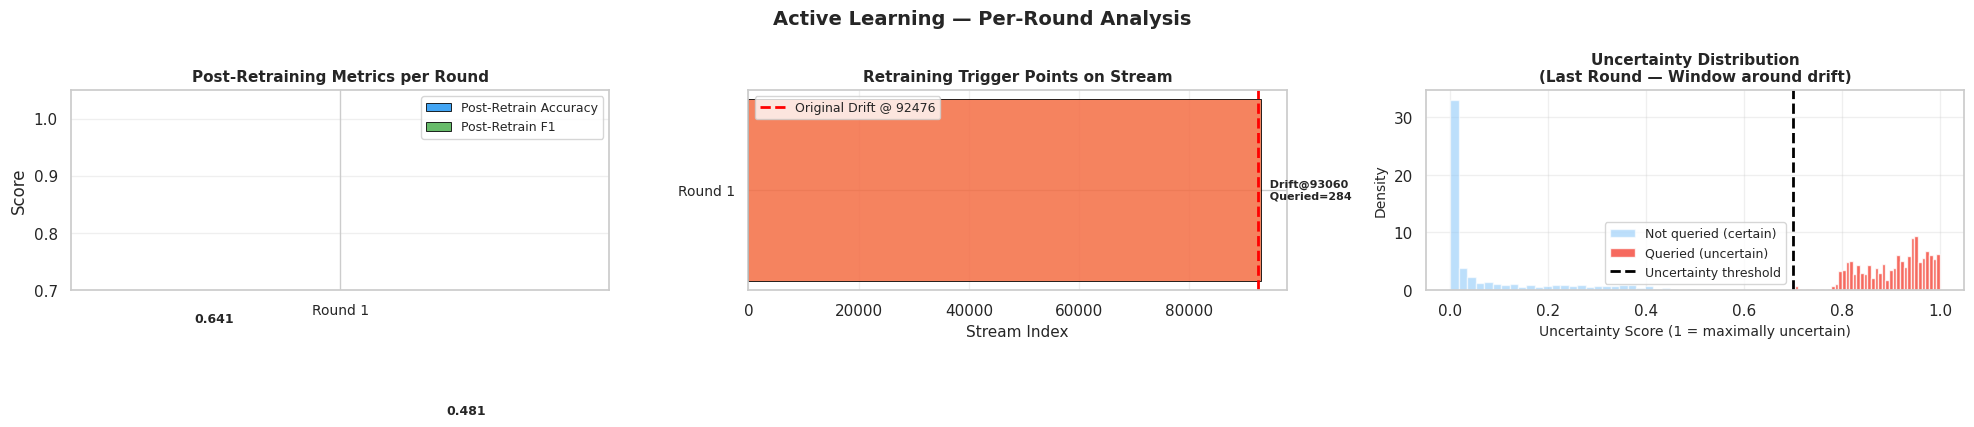

Saved → /content/drive/MyDrive/graph12_al_round_analysis.png


In [27]:
# ==========================================================
# NEW GRAPH 12: ACTIVE LEARNING — ROUND-BY-ROUND ANALYSIS
# ==========================================================
print("\n================ NEW GRAPH 12: AL ROUND ANALYSIS ================")

if round_log:
    n_rounds = len(round_log)
    fig, axes = plt.subplots(1, 3, figsize=(20, 6))
    fig.suptitle("Active Learning — Per-Round Analysis",
                 fontsize=14, fontweight='bold')

    ax = axes[0]
    rounds_x   = [r['round'] for r in round_log]
    post_accs  = [r['post_acc'] for r in round_log]
    post_f1s   = [r['post_f1']  for r in round_log]
    x_pos_r    = np.arange(n_rounds)
    ax.bar(x_pos_r - 0.18, post_accs, 0.34, label='Post-Retrain Accuracy',
           color='#2196F3', alpha=0.85, edgecolor='black', linewidth=0.7)
    ax.bar(x_pos_r + 0.18, post_f1s,  0.34, label='Post-Retrain F1',
           color='#4CAF50', alpha=0.85, edgecolor='black', linewidth=0.7)
    for xi, (a, f) in enumerate(zip(post_accs, post_f1s)):
        ax.text(xi - 0.18, a + 0.002, f'{a:.3f}', ha='center', fontsize=9, fontweight='bold')
        ax.text(xi + 0.18, f + 0.002, f'{f:.3f}', ha='center', fontsize=9, fontweight='bold')
    ax.set_xticks(x_pos_r)
    ax.set_xticklabels([f'Round {r}' for r in rounds_x], fontsize=10)
    ax.set_ylim(0.7, 1.05); ax.set_ylabel("Score")
    ax.set_title("Post-Retraining Metrics per Round", fontsize=11, fontweight='bold')
    ax.legend(fontsize=9); ax.grid(axis='y', alpha=0.3)

    ax = axes[1]
    drift_indices  = [r['drift_index'] for r in round_log]
    queried_counts = [r['queried'] for r in round_log]
    colors_r = plt.cm.RdYlGn(np.linspace(0.2, 0.9, n_rounds))
    for ri, (di, qi, col) in enumerate(zip(drift_indices, queried_counts, colors_r)):
        ax.barh(ri, di, color=col, edgecolor='black', linewidth=0.7, alpha=0.85)
        ax.text(di + 200, ri, f'  Drift@{di}\n  Queried={qi}',
                va='center', fontsize=8, fontweight='bold')
    ax.axvline(drift_start, color='red', linestyle='--', linewidth=2,
               label=f'Original Drift @ {drift_start}')
    ax.set_yticks(range(n_rounds))
    ax.set_yticklabels([f'Round {r["round"]}' for r in round_log], fontsize=10)
    ax.set_xlabel("Stream Index", fontsize=11)
    ax.set_title("Retraining Trigger Points on Stream", fontsize=11, fontweight='bold')
    ax.legend(fontsize=9); ax.grid(axis='x', alpha=0.3)

    ax = axes[2]
    last_round  = round_log[-1]
    w_start_vis = max(0, last_round['drift_index'] - 2000)
    w_end_vis   = min(n_eval, last_round['drift_index'] + 500)
    vis_scores  = stream_scores[w_start_vis:w_end_vis]
    uncertainty_vals = 1 - np.abs(vis_scores - 0.5) * 2
    sampled_mask     = np.abs(vis_scores - 0.5) < AL_CONFIG["confidence_threshold"]

    ax.hist(uncertainty_vals[~sampled_mask], bins=40, alpha=0.6, color='#90CAF9',
            label='Not queried (certain)', density=True)
    ax.hist(uncertainty_vals[sampled_mask],  bins=40, alpha=0.8, color='#F44336',
            label='Queried (uncertain)',    density=True)
    ax.axvline(1 - AL_CONFIG["confidence_threshold"]*2, color='black',
               linestyle='--', linewidth=2, label='Uncertainty threshold')
    ax.set_xlabel("Uncertainty Score (1 = maximally uncertain)", fontsize=10)
    ax.set_ylabel("Density", fontsize=10)
    ax.set_title(f"Uncertainty Distribution\n(Last Round — Window around drift)",
                 fontsize=11, fontweight='bold')
    ax.legend(fontsize=9); ax.grid(alpha=0.3)

    plt.tight_layout()
    save_and_show("/content/drive/MyDrive/graph12_al_round_analysis.png")
else:
    print("  No retraining rounds completed — skipping graph 12.")



================ NEW GRAPH 14: CATASTROPHIC FORGETTING TREND ================


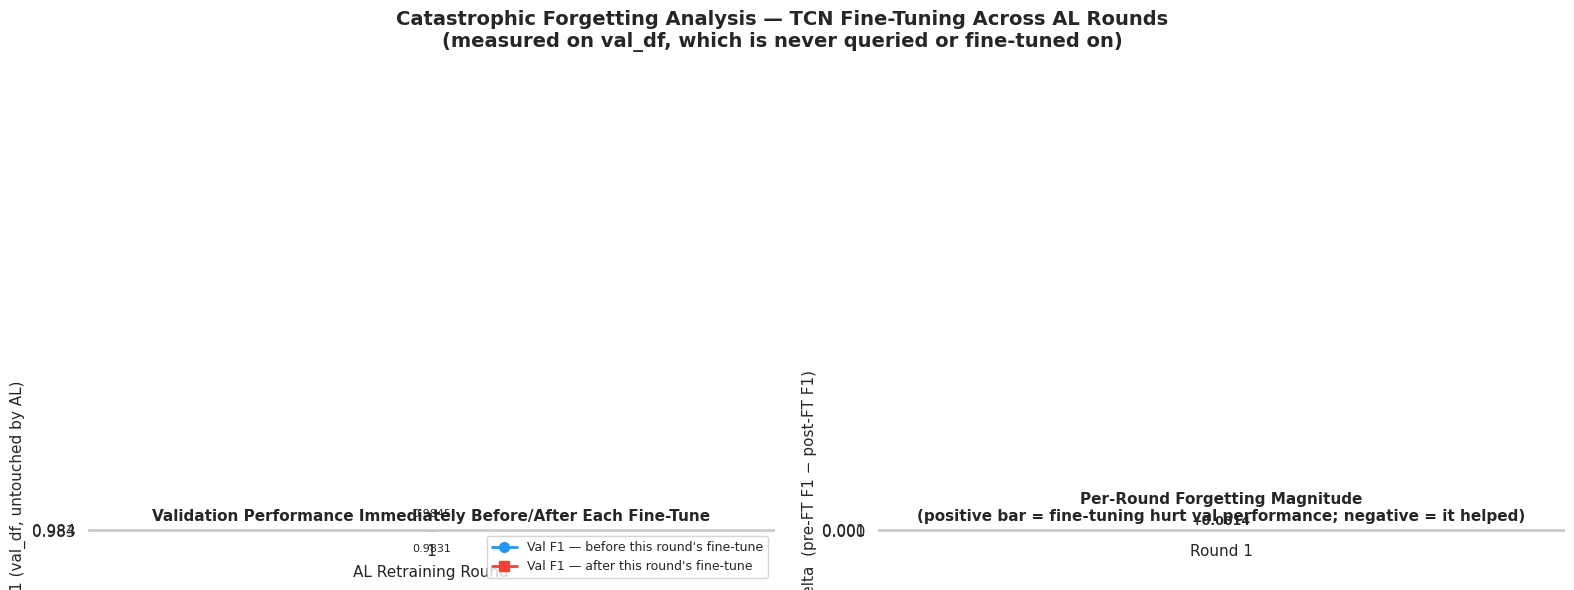

Saved → /content/drive/MyDrive/graph14_forgetting_trend.png
  Mean per-round forgetting delta        : +0.0014
  Cumulative drift (Round-1 pre-FT val F1 vs final post-FT val F1): +0.0014
  No strong evidence of cumulative catastrophic forgetting over these rounds (mean per-round delta is small), but this is only 5 rounds on one drift scenario — not a general guarantee.


In [28]:
# ==========================================================
# NEW GRAPH 14: CATASTROPHIC FORGETTING TREND
# (Addresses reviewer point 4 — does small-batch TCN fine-tuning erode
#  performance on previously-learned, non-drifted patterns over successive
#  rounds? The probe data (pre_ft_val_f1 / post_ft_val_f1) was already
#  collected each round on the untouched val_df; this graph analyzes it.)
# ==========================================================
print("\n================ NEW GRAPH 14: CATASTROPHIC FORGETTING TREND ================")

if round_log:
    rounds_x    = [r['round'] for r in round_log]
    pre_f1s     = [r['pre_ft_val_f1']  for r in round_log]
    post_f1s_ft = [r['post_ft_val_f1'] for r in round_log]
    deltas      = [pre - post for pre, post in zip(pre_f1s, post_f1s_ft)]

    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    fig.suptitle("Catastrophic Forgetting Analysis — TCN Fine-Tuning Across AL Rounds\n"
                 "(measured on val_df, which is never queried or fine-tuned on)",
                 fontsize=14, fontweight='bold')

    ax = axes[0]
    ax.plot(rounds_x, pre_f1s,     marker='o', color='#2196F3', linewidth=2, markersize=7,
            label='Val F1 — before this round\'s fine-tune')
    ax.plot(rounds_x, post_f1s_ft, marker='s', color='#F44336', linewidth=2, markersize=7,
            label='Val F1 — after this round\'s fine-tune')
    for x, y in zip(rounds_x, pre_f1s):
        ax.annotate(f'{y:.4f}', (x, y), textcoords="offset points", xytext=(0, 9), ha='center', fontsize=8)
    for x, y in zip(rounds_x, post_f1s_ft):
        ax.annotate(f'{y:.4f}', (x, y), textcoords="offset points", xytext=(0, -15), ha='center', fontsize=8)
    ax.set_xticks(rounds_x)
    ax.set_xlabel("AL Retraining Round", fontsize=11)
    ax.set_ylabel("Validation F1 (val_df, untouched by AL)", fontsize=11)
    ax.set_title("Validation Performance Immediately Before/After Each Fine-Tune", fontsize=11, fontweight='bold')
    ax.legend(fontsize=9); ax.grid(alpha=0.3)

    ax = axes[1]
    bar_colors = ['#F44336' if d > 0 else '#4CAF50' for d in deltas]
    bars = ax.bar([f'Round {r}' for r in rounds_x], deltas, color=bar_colors,
                  edgecolor='black', linewidth=0.7)
    ax.axhline(0, color='black', linewidth=1)
    for bar, val in zip(bars, deltas):
        ax.text(bar.get_x() + bar.get_width() / 2, val + (0.0015 if val >= 0 else -0.0035),
                f'{val:+.4f}', ha='center', va='bottom' if val >= 0 else 'top',
                fontsize=9, fontweight='bold')
    ax.set_ylabel("Forgetting Delta  (pre-FT F1 − post-FT F1)", fontsize=11)
    ax.set_title("Per-Round Forgetting Magnitude\n(positive bar = fine-tuning hurt val performance; negative = it helped)",
                 fontsize=11, fontweight='bold')
    ax.grid(axis='y', alpha=0.3)

    plt.tight_layout()
    save_and_show("/content/drive/MyDrive/graph14_forgetting_trend.png")

    cumulative_forgetting = pre_f1s[0] - post_f1s_ft[-1]
    mean_round_delta = float(np.mean(deltas))
    print(f"  Mean per-round forgetting delta        : {mean_round_delta:+.4f}")
    print(f"  Cumulative drift (Round-1 pre-FT val F1 vs final post-FT val F1): {cumulative_forgetting:+.4f}")
    if mean_round_delta > 0.01:
        print("  ⚠  Average forgetting delta exceeds 0.01 — small-batch fine-tuning is "
              "measurably eroding performance on non-drifted patterns; consider replay "
              "buffers or regularized fine-tuning (e.g. EWC) in future work.")
    else:
        print("  No strong evidence of cumulative catastrophic forgetting over these rounds "
              "(mean per-round delta is small), but this is only 5 rounds on one drift "
              "scenario — not a general guarantee.")
else:
    print("  No retraining rounds completed — skipping graph 14.")



================ NEW GRAPH 13: SYSTEM COMPARISON DASHBOARD ================
  Post-drift leakage guard: excluded 275/30826 oracle-queried samples from Phase B/C metrics.


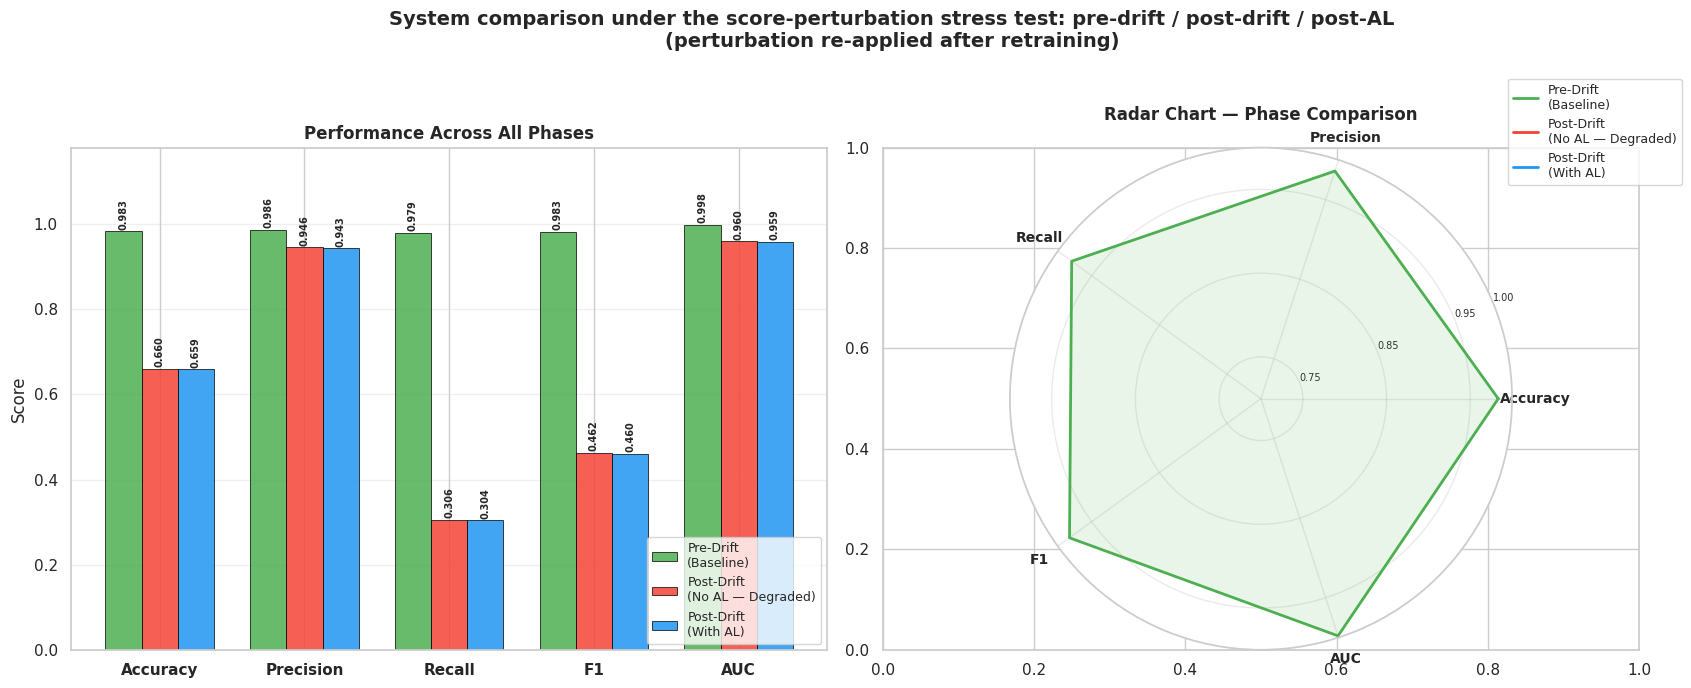

Saved → /content/drive/MyDrive/graph13_system_comparison.png

  FULL PIPELINE + ACTIVE LEARNING — COMPLETED
  Graphs saved to Google Drive:
    drift_detection_dashboard.png
    rolling_window_metrics.png
    graph1_data_exploration.png
    graph2_lexical_features.png
    graph3_training_curves.png
    graph4_roc_pr_curves.png
    graph5_confusion_matrices.png
    graph6_model_comparison.png
    graph7_meta_anomaly_analysis.png
    graph8_drift_detailed.png
    graph9_threshold_sensitivity.png
    graph10_summary_dashboard.png
    graph11_al_recovery.png          ← NEW (leakage-free)
    graph12_al_round_analysis.png    ← NEW
    graph14_forgetting_trend.png     ← NEW
    graph13_system_comparison.png    ← NEW (leakage-free)
    graph_latency_comparison.png     ← NEW
    latency_benchmark_table.csv      ← NEW

  Active Learning retraining rounds  : 1
  Samples excluded from AL metrics as leaked : 284 / 123302
  Total graphs produced              : 17


In [29]:
# ==========================================================
# NEW GRAPH 13: COMPLETE SYSTEM COMPARISON DASHBOARD
# ==========================================================
print("\n================ NEW GRAPH 13: SYSTEM COMPARISON DASHBOARD ================")

def phase_metrics(y_true, y_pred, y_score):
    fpr_, tpr_, _ = roc_curve(y_true, y_score)
    return {
        'Accuracy' : accuracy_score(y_true, y_pred),
        'Precision': precision_score(y_true, y_pred, zero_division=0),
        'Recall'   : recall_score(y_true, y_pred, zero_division=0),
        'F1'       : f1_score(y_true, y_pred, zero_division=0),
        'AUC'      : auc(fpr_, tpr_),
    }

# Pre-drift phase: AL hasn't started yet, so no leakage is possible here.
pre_true_ph  = stream_true[:drift_start]
pre_pred_ph  = yhat_sim[:drift_start]
pre_score_ph = S_eval_sim[:drift_start]
phase_A = phase_metrics(pre_true_ph, pre_pred_ph, pre_score_ph)

# LEAKAGE FIX: Phase B ("No AL") and Phase C ("With AL") are both computed
# on the SAME leakage-free index set — every index ever oracle-queried
# during the AL loop is excluded from both, so the comparison isolates the
# effect of retraining rather than partly comparing against samples the
# AL models were trained on.
post_idx_all   = np.arange(drift_start, n_eval)
post_clean_idx = post_idx_all[~al_queried_mask[post_idx_all]]
n_post_excluded = len(post_idx_all) - len(post_clean_idx)
print(f"  Post-drift leakage guard: excluded {n_post_excluded}/{len(post_idx_all)} "
      f"oracle-queried samples from Phase B/C metrics.")

post_true_ph_clean = stream_true[post_clean_idx]

post_pred_no_al_clean  = yhat_sim[post_clean_idx]
post_score_no_al_clean = S_eval_sim[post_clean_idx]
phase_B = phase_metrics(post_true_ph_clean, post_pred_no_al_clean, post_score_no_al_clean)

post_pred_al_clean  = stream_preds[post_clean_idx]
post_score_al_clean = stream_scores[post_clean_idx]
phase_C = phase_metrics(post_true_ph_clean, post_pred_al_clean, post_score_al_clean)

fig, axes = plt.subplots(1, 2, figsize=(18, 7))
fig.suptitle("System comparison under the score-perturbation stress test: pre-drift / post-drift / post-AL\n(perturbation re-applied after retraining)",
             fontsize=14, fontweight='bold')

metric_names_c = ['Accuracy', 'Precision', 'Recall', 'F1', 'AUC']
phase_labels   = ['Pre-Drift\n(Baseline)', 'Post-Drift\n(No AL — Degraded)', 'Post-Drift\n(With AL)']
phase_colors   = ['#4CAF50', '#F44336', '#2196F3']
phases         = [phase_A, phase_B, phase_C]

ax = axes[0]
x_m     = np.arange(len(metric_names_c))
width_c = 0.25
for pi, (ph, label, color) in enumerate(zip(phases, phase_labels, phase_colors)):
    vals = [ph[m] for m in metric_names_c]
    bars = ax.bar(x_m + (pi - 1) * width_c, vals, width_c,
                  label=label, color=color, alpha=0.85,
                  edgecolor='black', linewidth=0.6)
    for bar, val in zip(bars, vals):
        ax.text(bar.get_x() + bar.get_width()/2,
                bar.get_height() + 0.004,
                f'{val:.3f}', ha='center', va='bottom',
                fontsize=7, rotation=90, fontweight='bold')
ax.set_xticks(x_m)
ax.set_xticklabels(metric_names_c, fontsize=11, fontweight='bold')
ax.set_ylim(0, 1.18); ax.set_ylabel("Score", fontsize=12)
ax.set_title("Performance Across All Phases", fontsize=12, fontweight='bold')
ax.legend(fontsize=9, loc='lower right'); ax.grid(axis='y', alpha=0.3)

cats   = metric_names_c + [metric_names_c[0]]
n_cats = len(metric_names_c)
angles = np.linspace(0, 2 * np.pi, n_cats, endpoint=False).tolist()
angles += angles[:1]

ax = plt.subplot(122, polar=True)
for ph, label, color in zip(phases, phase_labels, phase_colors):
    values = [ph[m] for m in metric_names_c]
    values += values[:1]
    ax.plot(angles, values, color=color, linewidth=2, label=label)
    ax.fill(angles, values, color=color, alpha=0.12)

ax.set_xticks(angles[:-1])
ax.set_xticklabels(metric_names_c, fontsize=10, fontweight='bold')
ax.set_ylim(0.7, 1.0)
ax.set_yticks([0.75, 0.85, 0.95, 1.0])
ax.set_yticklabels(['0.75', '0.85', '0.95', '1.00'], fontsize=7)
ax.set_title("Radar Chart — Phase Comparison", fontsize=12, fontweight='bold', pad=20)
ax.legend(loc='upper right', bbox_to_anchor=(1.35, 1.15), fontsize=9)
ax.grid(alpha=0.4)

plt.tight_layout()
save_and_show("/content/drive/MyDrive/graph13_system_comparison.png")


# ==========================================================
# FINAL SUMMARY
# ==========================================================
print("\n" + "="*55)
print("  FULL PIPELINE + ACTIVE LEARNING — COMPLETED")
print("="*55)
print("  Graphs saved to Google Drive:")
print("    drift_detection_dashboard.png")
print("    rolling_window_metrics.png")
print("    graph1_data_exploration.png")
print("    graph2_lexical_features.png")
print("    graph3_training_curves.png")
print("    graph4_roc_pr_curves.png")
print("    graph5_confusion_matrices.png")
print("    graph6_model_comparison.png")
print("    graph7_meta_anomaly_analysis.png")
print("    graph8_drift_detailed.png")
print("    graph9_threshold_sensitivity.png")
print("    graph10_summary_dashboard.png")
print("    graph11_al_recovery.png          ← NEW (leakage-free)")
print("    graph12_al_round_analysis.png    ← NEW")
print("    graph14_forgetting_trend.png     ← NEW")
print("    graph13_system_comparison.png    ← NEW (leakage-free)")
print("    graph_latency_comparison.png     ← NEW")
print("    latency_benchmark_table.csv      ← NEW")
print(f"\n  Active Learning retraining rounds  : {retraining_rounds}")
print(f"  Samples excluded from AL metrics as leaked : {int(al_queried_mask.sum())} / {n_eval}")
print(f"  Total graphs produced              : 17")
print("="*55)


---
# Revision experiments (Reviewers 1, 4, 5)
Everything below reuses the models trained above. Findings in earlier runs worth knowing before you rewrite the paper:
* with the perturbation **re-applied** after retraining, active learning shows **no recovery** in the score-perturbation stress test (the perturbation acts after the model) — the earlier "recovery" came from the evaluation protocol;
* the Hybrid is **not better than DeepTCN in AUC** (paired CI excludes 0 in DeepTCN's favour) and only marginally different in F1/accuracy;
* input-level drift **does** show genuine recovery with active learning.


In [30]:
# ==========================================================================================
# ██████████████████████████  REVISION EXPERIMENTS (R1 / R4 / R5)  ███████████████████████████
# Everything below is NEW. It reuses the trained models/variables created above and never
# touches eval_df to choose a threshold or a hyper-parameter.
# Every experiment is wrapped so one failure does not stop the others.
# Results are written to  /content/drive/MyDrive/revision_results/
# ==========================================================================================
print("\n" + "█" * 60)
print("  REVISION EXPERIMENTS  (Reviewers 1, 4, 5)")
print("█" * 60)

import io, json, contextlib, traceback
from collections import Counter
from scipy.sparse import vstack as sp_vstack
from scipy.stats import binomtest
from sklearn.metrics import roc_auc_score
from sklearn.inspection import permutation_importance
from sklearn.naive_bayes import MultinomialNB
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_val_predict

# ---- switches (set False to skip) ----
RUN_OVERLAP_CHECK      = True
RUN_BASELINES          = True    # classical baselines (NB, gradient boosting) – NOT SOTA
RUN_BOOTSTRAP          = True    # R1-3, R4-4, R5: CIs + paired tests
RUN_PERM_IMPORTANCE    = True    # R4-5
RUN_META_ABLATION      = True    # R4-4/5, R1-1: branch ablation + meta-learner sensitivity
RUN_OOD_ANALYSIS       = True    # R5: OOD AUC per branch + small-sample adaptation
RUN_DETECTOR_GRID      = True    # R1-1: detector hyper-parameter sensitivity
RUN_STREAM_EXPERIMENTS = True    # R4-1/2/3, R5: label availability, input-level drift, noisy/delayed oracle
N_NOISE_SEEDS          = 3       # repeats for noisy-oracle runs (use 1 for a quick pass)

OUT_DIR = "/content/drive/MyDrive/revision_results"
os.makedirs(OUT_DIR, exist_ok=True)
RESULTS = {}


def _jsonable(o):
    if isinstance(o, (np.integer,)):  return int(o)
    if isinstance(o, (np.floating,)): return float(o)
    if isinstance(o, np.ndarray):     return o.tolist()
    return str(o)


def save_json(name, obj):
    with open(os.path.join(OUT_DIR, name), "w") as f:
        json.dump(obj, f, indent=2, default=_jsonable)


def save_csv(name, df):
    df.to_csv(os.path.join(OUT_DIR, name), index=False)


def _safe(name, fn):
    print("\n" + "=" * 60 + f"\n  {name}\n" + "=" * 60)
    t0 = time.time()
    try:
        fn()
        print(f"  [{name}] done in {time.time() - t0:.0f}s")
        try: save_json('all_results.json', RESULTS)   # checkpoint after every experiment
        except Exception: pass
    except Exception as e:
        print(f"  [{name}] FAILED: {e}")
        traceback.print_exc()


y_eval_arr = eval_df.labels.values
y_val_arr  = val_df.labels.values

# <<HELPERS_BEGIN>>
def _best_f1_thr(y, s):
    p, r, t = precision_recall_curve(y, s)
    f = 2 * p * r / (p + r + 1e-9)
    return float(t[int(np.argmax(f[:-1]))])


def _m(yt, yp, s=None):
    yt = np.asarray(yt); yp = np.asarray(yp)
    if len(yt) == 0:
        return dict(n=0, acc=np.nan, prec=np.nan, rec=np.nan, f1=np.nan, auc=np.nan)
    out = dict(n=int(len(yt)),
               acc=accuracy_score(yt, yp),
               prec=precision_score(yt, yp, zero_division=0),
               rec=recall_score(yt, yp, zero_division=0),
               f1=f1_score(yt, yp, zero_division=0))
    out["auc"] = (roc_auc_score(yt, s) if (s is not None and len(np.unique(yt)) == 2) else np.nan)
    return out


def al_stream_run(*, y, drift_start, X_ml, a, Z, clf0, dl0, meta0,
                  X_val_ml, Z_val, a_val, y_val, p_dl_val0, thr,
                  post_hook=None, hook_on_rescore=True,
                  label_frac=1.0, trigger_mode="adwin_ddm",
                  oracle_noise=0.0, oracle_delay=0,
                  budget=500, conf_thr=0.15, max_rounds=5,
                  query_back=2000, report_len=500, query_strategy="uncertainty",
                  collect_after_trigger=500, meta_update="refit_val", seed=0):
    """
    Silent, causal drift-monitoring + active-learning simulation.

    * Causal: at trigger time i the oracle is queried ONLY on already-seen samples
      [i-query_back, i]  (the original loop also queried the next 500 unseen samples).
    * label_frac    : fraction of stream samples whose true label is observed online
                      (only these feed ADWIN / DDM).  Page-Hinkley (confidence) never needs labels.
    * trigger_mode  : "adwin_ddm" (needs labels)  or  "ph" (label-free trigger).
    * oracle_noise  : probability that an oracle answer is flipped.
    * oracle_delay  : labels arrive this many stream steps after the query is issued.
    * post_hook     : optional score-level perturbation hook(scores, start_idx) -> scores.
      hook_on_rescore=True re-applies the SAME perturbation after retraining
      (equivalent pre/post conditions); False reproduces the old, confounded behaviour.
    * collect_after_trigger: after a detection the system waits this many samples (so that post-drift
      samples exist in the causal query window), then queries the oracle on [i-query_back, i].
      (The original loop achieved this non-causally by also querying the next 500 UNSEEN samples.)
    * meta_update: how the meta-learner is updated after a round -
        "refit_val"   : refit on the clean validation set only (the design in the paper),
        "none"        : keep the old meta-learner, only the base branches are updated,
        "val+queried" : refit on validation + the oracle-labelled (drifted) queried samples.
    * query_strategy: "uncertainty" (as in the paper), "uncertainty+random" (top up to the budget with random
      samples when too few uncertain ones exist, e.g. when evasion makes errors CONFIDENT) or "random".
    * Every queried index is added to Q at query time and excluded from ALL reported metrics.
    """
    rng = np.random.default_rng(seed)
    y = np.asarray(y); y_val = np.asarray(y_val); n = len(y)
    clf = copy.deepcopy(clf0); dl = dl0.copy(); meta = copy.deepcopy(meta0)

    def score_from(start, clf_, dl_, meta_):
        p_ml_ = clf_.predict_proba(X_ml[start:])[:, 1]
        p_dl_ = dl_.score(Z[start:])
        return meta_.predict_proba(np.column_stack([p_ml_, p_dl_, a[start:]]))[:, 1]

    S0 = score_from(0, clf, dl, meta)
    if post_hook is not None:
        S0 = post_hook(S0, 0)
    scores = S0.copy()
    preds0 = (S0 > thr).astype(int)
    preds = preds0.copy()

    new_dets = lambda: (ADWIN(delta=0.002, min_window=30, max_window=1000),
                        DDM(warning_level=2.0, drift_level=3.0),
                        PageHinkley(delta=0.005, lam=8))
    adwin, ddm, ph = new_dets()
    p_dl_val_cur = np.asarray(p_dl_val0)
    Q = set(); rounds = []; fired_log = []; pending = None; armed_at = None

    for i in range(n):
        # ---- labels of an earlier query arrive: retrain, re-score the remaining stream ----
        if pending is not None and i >= pending["exec_at"]:
            g, q = pending["g"], pending["q"]
            trig = pending["trigger_idx"]; pending = None
            clf.partial_fit(X_ml[g], q, classes=[0, 1])
            f_pre = f1_score(y_val, (p_dl_val_cur > 0.5).astype(int), zero_division=0)
            dl.finetune(Z[g], q)
            p_dl_val_cur = dl.score(Z_val)
            f_post = f1_score(y_val, (p_dl_val_cur > 0.5).astype(int), zero_division=0)
            p_ml_val_new = clf.predict_proba(X_val_ml)[:, 1]
            if meta_update != "none":
                Mx = np.column_stack([p_ml_val_new, p_dl_val_cur, a_val]); yy = y_val
                if meta_update == "val+queried":
                    Mq = np.column_stack([clf.predict_proba(X_ml[g])[:, 1], dl.score(Z[g]), a[g]])
                    Mx = np.vstack([Mx, Mq]); yy = np.concatenate([y_val, q])
                meta = RandomForestClassifier(n_estimators=200, max_depth=6,
                                              class_weight="balanced", random_state=42, n_jobs=-1)
                meta.fit(Mx, yy)
            S_rem = score_from(i, clf, dl, meta)
            if post_hook is not None and hook_on_rescore:
                S_rem = post_hook(S_rem, i)
            scores[i:] = S_rem
            preds[i:] = (S_rem > thr).astype(int)
            rep = np.arange(i, min(i + report_len, n))
            rep = rep[~np.isin(rep, np.fromiter(Q, dtype=int))]
            mm = _m(y[rep], preds[rep])
            rounds.append(dict(round=len(rounds) + 1, trigger_idx=int(trig), exec_idx=int(i),
                               n_queried=int(len(g)), label_noise_actual=float((q != y[g]).mean()),
                               post_acc=mm["acc"], post_f1=mm["f1"], n_report=mm["n"],
                               val_f1_pre=float(f_pre), val_f1_post=float(f_post)))
            adwin, ddm, ph = new_dets()

        # ---- observe sample i ----
        err = int(preds[i] != y[i])
        ph_fired = ph.update(1 - abs(scores[i] - thr))              # label-free
        adwin_fired = ddm_fired = False
        if label_frac >= 1.0 or rng.random() < label_frac:           # label observed online
            adwin_fired = adwin.update(float(err))
            ddm_fired = (ddm.update(err) == "DRIFT")
        fired = (adwin_fired or ddm_fired) if trigger_mode == "adwin_ddm" else ph_fired

        if fired:
            fired_log.append(i)
            if armed_at is None and pending is None and len(rounds) < max_rounds:
                armed_at = i + int(collect_after_trigger)

        if armed_at is not None and i >= armed_at:                   # time to query the oracle
            armed_at = None
            pool = np.arange(max(0, i - query_back), i + 1)          # causal window: only seen samples
            if Q:
                pool = pool[~np.isin(pool, np.fromiter(Q, dtype=int))]
            if len(pool) > 0:
                if query_strategy == "random":
                    loc = rng.choice(len(pool), size=min(budget, len(pool)), replace=False)
                else:
                    loc = uncertainty_sample(scores[pool], budget, conf_thr)
                    if query_strategy == "uncertainty+random" and len(loc) < budget:
                        rest = np.setdiff1d(np.arange(len(pool)), loc)
                        extra = rng.choice(rest, size=min(budget - len(loc), len(rest)), replace=False)
                        loc = np.concatenate([loc, extra])
                g = pool[loc]
                q = y[g].copy()
                if oracle_noise > 0:
                    flip = rng.random(len(g)) < oracle_noise
                    q = np.where(flip, 1 - q, q)
                Q.update(g.tolist())
                pending = dict(exec_at=i + 1 + int(oracle_delay), g=g, q=q, trigger_idx=i)

    qmask = np.zeros(n, dtype=bool)
    if Q:
        qmask[np.fromiter(Q, dtype=int)] = True
    pre_idx = np.arange(0, drift_start)
    post_idx = np.arange(drift_start, n)
    post_clean = post_idx[~qmask[post_idx]]
    first_exec = rounds[0]["exec_idx"] if rounds else None
    after_clean = post_clean[post_clean >= first_exec] if rounds else post_clean[:0]

    det_after = [d for d in fired_log if d >= drift_start]
    return dict(
        n_rounds=len(rounds), n_queried_total=int(qmask.sum()),
        first_detect_delay=(int(det_after[0] - drift_start) if det_after else None),
        false_alarms_before_drift=int(sum(d < drift_start for d in fired_log)),
        pre=_m(y[pre_idx], preds0[pre_idx], S0[pre_idx]),
        post_noAL=_m(y[post_clean], preds0[post_clean], S0[post_clean]),
        post_AL=_m(y[post_clean], preds[post_clean], scores[post_clean]),
        after_noAL=_m(y[after_clean], preds0[after_clean], S0[after_clean]),
        after_AL=_m(y[after_clean], preds[after_clean], scores[after_clean]),
        mean_forgetting=(float(np.mean([r["val_f1_pre"] - r["val_f1_post"] for r in rounds])) if rounds else None),
        rounds=rounds, _arr=dict(preds0=preds0.astype(np.int8), preds=preds.astype(np.int8), qmask=qmask, y=y.astype(np.int8)))


def bootstrap_report(models, y, B=1000, B_auc=200, seed=42, ref="Hybrid (GramBeddings)"):
    """models: name -> (eval_scores, threshold). Paired bootstrap on the eval set (same resamples
    for every model), 95% percentile CIs, paired differences vs `ref`, and McNemar tests."""
    y = np.asarray(y); n = len(y); rng = np.random.default_rng(seed)
    names = list(models)
    pre = {}
    for k, (s, t) in models.items():
        yp = (np.asarray(s) > t).astype(int)
        pre[k] = dict(tp=((yp == 1) & (y == 1)).astype(np.float64),
                      fp=((yp == 1) & (y == 0)).astype(np.float64),
                      fn=((yp == 0) & (y == 1)).astype(np.float64),
                      ok=(yp == y).astype(np.float64), yp=yp, s=np.asarray(s))
    acc = {k: np.empty(B) for k in names}; f1b = {k: np.empty(B) for k in names}
    for b in range(B):
        cnt = np.bincount(rng.integers(0, n, n), minlength=n).astype(np.float64)
        for k, p in pre.items():
            tp, fp, fn = cnt @ p["tp"], cnt @ p["fp"], cnt @ p["fn"]
            acc[k][b] = (cnt @ p["ok"]) / n
            f1b[k][b] = 2 * tp / (2 * tp + fp + fn + 1e-12)
    auc = {k: np.empty(B_auc) for k in names}
    for b in range(B_auc):
        idx = rng.integers(0, n, n); yb = y[idx]
        for k in names:
            auc[k][b] = roc_auc_score(yb, pre[k]["s"][idx])
    ci = lambda v: (float(np.percentile(v, 2.5)), float(np.percentile(v, 97.5)))
    rows = []
    for k in names:
        p = pre[k]
        tp, fp, fn = p["tp"].sum(), p["fp"].sum(), p["fn"].sum()
        rows.append(dict(model=k, thr=float(models[k][1]),
                         acc=float(p["ok"].mean()), acc_lo=ci(acc[k])[0], acc_hi=ci(acc[k])[1],
                         f1=float(2 * tp / (2 * tp + fp + fn)), f1_lo=ci(f1b[k])[0], f1_hi=ci(f1b[k])[1],
                         auc=float(roc_auc_score(y, p["s"])), auc_lo=ci(auc[k])[0], auc_hi=ci(auc[k])[1]))
    drows = []
    if ref in pre:
        for k in names:
            if k == ref:
                continue
            da, df_, du = acc[ref] - acc[k], f1b[ref] - f1b[k], auc[ref] - auc[k]
            b01 = int(((pre[ref]["ok"] == 1) & (pre[k]["ok"] == 0)).sum())   # ref right, other wrong
            c01 = int(((pre[ref]["ok"] == 0) & (pre[k]["ok"] == 1)).sum())   # ref wrong, other right
            pval = float(binomtest(b01, b01 + c01, 0.5).pvalue) if (b01 + c01) > 0 else 1.0
            drows.append(dict(ref=ref, vs=k,
                              d_acc=float((pre[ref]["ok"] - pre[k]["ok"]).mean()), d_acc_lo=ci(da)[0], d_acc_hi=ci(da)[1],
                              d_f1=float(rows[names.index(ref)]["f1"] - rows[names.index(k)]["f1"]), d_f1_lo=ci(df_)[0], d_f1_hi=ci(df_)[1],
                              d_auc=float(rows[names.index(ref)]["auc"] - rows[names.index(k)]["auc"]), d_auc_lo=ci(du)[0], d_auc_hi=ci(du)[1],
                              ref_right_other_wrong=b01, ref_wrong_other_right=c01, mcnemar_exact_p=pval))
    return pd.DataFrame(rows), pd.DataFrame(drows)
# <<HELPERS_END>>



████████████████████████████████████████████████████████████
  REVISION EXPERIMENTS  (Reviewers 1, 4, 5)
████████████████████████████████████████████████████████████


In [31]:
# ------------------------------------------------------------------ model registry (eval scores + val-tuned thresholds)
MODEL_EVAL = {}     # name -> (eval_scores, threshold)
MODEL_PHI = {}      # name -> scores on Dataset-2 (OOD)
thr_ml = _best_f1_thr(y_val_arr, p_ml_val)     # branch thresholds tuned on VALIDATION only
thr_dl = _best_f1_thr(y_val_arr, p_dl_val)
MODEL_EVAL["ML branch (SGD)"]        = (p_ml_eval, thr_ml)
MODEL_EVAL["DL branch (DeepTCN)"]    = (p_dl_eval, thr_dl)
MODEL_EVAL["Hybrid (GramBeddings)"]  = (S_eval, float(best_thr))
MODEL_PHI.update({"ML branch (SGD)": p_ml_phi, "DL branch (DeepTCN)": p_dl_phi, "Hybrid (GramBeddings)": S_phi})


# ------------------------------------------------------------------ 0. URL overlap / duplicate-leakage check
def exp_overlap():
    tr = set(train_df.url.astype(str))
    ov_eval = eval_df.url.astype(str).isin(tr).values
    ov_val  = val_df.url.astype(str).isin(tr).values
    dup_train = int(train_df.url.duplicated().sum())
    print(f"  eval URLs that also occur in train : {int(ov_eval.sum())} ({ov_eval.mean()*100:.3f}%)")
    print(f"  val  URLs that also occur in train : {int(ov_val.sum())} ({ov_val.mean()*100:.3f}%)")
    print(f"  duplicated URLs inside train       : {dup_train}")
    res = dict(eval_overlap=int(ov_eval.sum()), eval_overlap_frac=float(ov_eval.mean()),
               val_overlap=int(ov_val.sum()), train_internal_dups=dup_train)
    keep = ~ov_eval
    if ov_eval.sum() > 0:
        yh = (S_eval > best_thr).astype(int)
        m_all  = _m(y_eval_arr, yh, S_eval)
        m_dedup = _m(y_eval_arr[keep], yh[keep], S_eval[keep])
        print(f"  Hybrid on full eval        : acc={m_all['acc']:.4f} F1={m_all['f1']:.4f} AUC={m_all['auc']:.4f}")
        print(f"  Hybrid on de-duplicated eval: acc={m_dedup['acc']:.4f} F1={m_dedup['f1']:.4f} AUC={m_dedup['auc']:.4f} (n={m_dedup['n']})")
        res.update(full=m_all, dedup=m_dedup)
    RESULTS["overlap"] = res
    save_json("overlap_check.json", res)


# ------------------------------------------------------------------ 1. classical baselines (NOT SOTA)
def exp_baselines():
    t0 = time.time()
    nb = MultinomialNB(alpha=0.1).fit(X_ng_train, train_df.labels.values)
    MODEL_EVAL["Baseline: char-TFIDF + MultinomialNB"] = (nb.predict_proba(X_ng_eval)[:, 1],
                                                         _best_f1_thr(y_val_arr, nb.predict_proba(X_ng_val)[:, 1]))
    MODEL_PHI["Baseline: char-TFIDF + MultinomialNB"] = nb.predict_proba(X_ng_phi)[:, 1]
    hgb = HistGradientBoostingClassifier(max_iter=200, learning_rate=0.1, random_state=42)
    hgb.fit(X_lex_train, train_df.labels.values)
    MODEL_EVAL["Baseline: lexical + HistGradientBoosting"] = (hgb.predict_proba(X_lex_eval)[:, 1],
                                                             _best_f1_thr(y_val_arr, hgb.predict_proba(X_lex_val)[:, 1]))
    MODEL_PHI["Baseline: lexical + HistGradientBoosting"] = hgb.predict_proba(X_lex_phi)[:, 1]
    print(f"  baselines trained in {time.time() - t0:.0f}s (thresholds tuned on validation)")


# ------------------------------------------------------------------ 2. bootstrap CIs + paired tests
def exp_bootstrap():
    tab, diff = bootstrap_report(MODEL_EVAL, y_eval_arr, B=1000, B_auc=200)
    pd.set_option("display.width", 220); pd.set_option("display.max_columns", 30)
    print("\n  95% bootstrap CIs on the evaluation set (1000 resamples; AUC: 200):")
    print(tab.round(5).to_string(index=False))
    print("\n  Paired differences  (Hybrid − other)  + exact McNemar test:")
    print(diff.round(5).to_string(index=False))
    save_csv("bootstrap_ci.csv", tab); save_csv("bootstrap_paired_diff.csv", diff)
    RESULTS["bootstrap"] = tab.to_dict("records"); RESULTS["bootstrap_diff"] = diff.to_dict("records")
    print("\n  READ: a hybrid advantage is only 'supported' if the paired CI for d_f1 / d_auc excludes 0.")


# ------------------------------------------------------------------ 3. permutation importance (replaces 'decision weight')
def exp_perm_importance():
    names = ["ML (SGD)", "DL (DeepTCN)", "Anomaly (IsoForest)"]
    out = {}
    for scoring in ["roc_auc", "f1"]:
        pi = permutation_importance(meta_clf, meta_X_eval, y_eval_arr, scoring=scoring,
                                    n_repeats=10, random_state=42, n_jobs=1)
        out[scoring] = {n: (float(m), float(s)) for n, m, s in zip(names, pi.importances_mean, pi.importances_std)}
        print(f"  permutation importance on eval, drop in {scoring} (mean ± sd over 10 shuffles):")
        for n, m, s in zip(names, pi.importances_mean, pi.importances_std):
            print(f"    {n:22s} {m:+.5f} ± {s:.5f}")
    out["rf_impurity_importance_(NOT decision weights)"] = dict(zip(names, map(float, meta_clf.feature_importances_)))
    RESULTS["perm_importance"] = out; save_json("perm_importance.json", out)


# ------------------------------------------------------------------ 4. branch ablation + meta-learner sensitivity
def _fit_meta_eval(cols, depth=6, n_est=200, folds=5):
    Mv, Me = meta_X_val[:, cols], meta_X_eval[:, cols]
    rf_kw = dict(n_estimators=n_est, max_depth=depth, class_weight="balanced", random_state=42, n_jobs=-1)
    oof = cross_val_predict(RandomForestClassifier(**rf_kw), Mv, y_val_arr,
                            cv=StratifiedKFold(folds, shuffle=True, random_state=42), method="predict_proba")[:, 1]
    t = _best_f1_thr(y_val_arr, oof)
    rf = RandomForestClassifier(**rf_kw).fit(Mv, y_val_arr)
    s = rf.predict_proba(Me)[:, 1]
    return _m(y_eval_arr, (s > t).astype(int), s), t


def exp_meta_ablation():
    rows = []
    for label, cols in [("ML+DL+Anomaly (full)", [0, 1, 2]), ("ML+DL", [0, 1]), ("ML+Anomaly", [0, 2]),
                        ("DL+Anomaly", [1, 2]), ("DL only (meta-RF)", [1]), ("ML only (meta-RF)", [0])]:
        m, t = _fit_meta_eval(cols)
        rows.append(dict(config=label, thr=t, acc=m["acc"], f1=m["f1"], auc=m["auc"]))
    ab = pd.DataFrame(rows); print("\n  Branch ablation (meta-RF refit on val, threshold from val OOF, scored on eval):")
    print(ab.round(5).to_string(index=False)); save_csv("meta_branch_ablation.csv", ab)

    rows = []
    for depth in [3, 6, 10]:
        for n_est in [100, 200]:
            m, t = _fit_meta_eval([0, 1, 2], depth=depth, n_est=n_est, folds=3)
            rows.append(dict(max_depth=depth, n_estimators=n_est, thr=t, acc=m["acc"], f1=m["f1"], auc=m["auc"]))
    sens = pd.DataFrame(rows); print("\n  Meta-learner hyper-parameter sensitivity:")
    print(sens.round(5).to_string(index=False)); save_csv("meta_hyperparam_sensitivity.csv", sens)
    RESULTS["meta_ablation"] = ab.to_dict("records"); RESULTS["meta_sensitivity"] = sens.to_dict("records")


# ------------------------------------------------------------------ 5. OOD analysis (R5)
def exp_ood():
    yphi = phi_df.labels.values
    Mphi = np.column_stack([p_ml_phi, p_dl_phi, a_phi])
    br = {"ML branch": roc_auc_score(yphi, p_ml_phi), "DL branch": roc_auc_score(yphi, p_dl_phi),
          "Anomaly branch": roc_auc_score(yphi, a_phi), "Hybrid": roc_auc_score(yphi, S_phi)}
    print("  OOD (Dataset-2) AUC per branch:")
    for k, v in br.items():
        print(f"    {k:16s} {v:.4f}")
    rows = []
    for n_lab in [n for n in [500, 2000, 5000] if n < 0.8 * len(yphi)]:
        for rep in range(5):
            idx = np.random.RandomState(rep).permutation(len(yphi)); L, T = idx[:n_lab], idx[n_lab:]
            if len(np.unique(yphi[L])) < 2:
                continue
            rf_kw = dict(n_estimators=200, max_depth=6, class_weight="balanced", random_state=42, n_jobs=-1)
            rf = RandomForestClassifier(**rf_kw).fit(Mphi[L], yphi[L])
            sT = rf.predict_proba(Mphi[T])[:, 1]
            oof = cross_val_predict(RandomForestClassifier(**rf_kw), Mphi[L], yphi[L], cv=3, method="predict_proba")[:, 1]
            t_new = _best_f1_thr(yphi[L], oof)
            t_only = _best_f1_thr(yphi[L], S_phi[L])
            rows.append(dict(n_labelled=n_lab, rep=rep,
                             auc_original=roc_auc_score(yphi[T], S_phi[T]), f1_original=f1_score(yphi[T], yhat_phi[T]),
                             f1_threshold_only=f1_score(yphi[T], (S_phi[T] > t_only).astype(int)),
                             auc_meta_refit=roc_auc_score(yphi[T], sT), f1_meta_refit=f1_score(yphi[T], (sT > t_new).astype(int))))
    df = pd.DataFrame(rows)
    summ = df.groupby("n_labelled").agg(["mean", "std"]).drop(columns="rep")
    print("\n  Adapting the meta-learner with a few labelled OOD samples (mean/std over 5 draws):")
    print(summ.round(4).to_string())
    save_csv("ood_adaptation.csv", df); RESULTS["ood_branch_auc"] = br
    save_json("ood_branch_auc.json", br)


# ------------------------------------------------------------------ 6. detector hyper-parameter sensitivity
def detector_grid(tag, scores, thr_):
    y = y_eval_arr; preds = (scores > thr_).astype(int); err = (preds != y).astype(float)
    conf = 1 - np.abs(scores - thr_); rows = []

    def summarise(name, fires):
        after = [f for f in fires if f >= drift_start]
        rows.append(dict(stream=tag, detector=name, first_detect_delay=(after[0] - drift_start if after else None),
                         false_alarms_before_drift=sum(f < drift_start for f in fires), total_fires=len(fires)))

    for dlt in [0.0005, 0.002, 0.01]:
        d = ADWIN(delta=dlt, min_window=30, max_window=1000)
        summarise(f"ADWIN delta={dlt}", [i for i, e in enumerate(err) if d.update(e)])
    for lam in [4, 8, 16]:
        d = PageHinkley(delta=0.005, lam=lam)
        summarise(f"PageHinkley lam={lam}", [i for i, c in enumerate(conf) if d.update(c)])
    for dl_ in [2.5, 3.0, 4.0]:
        d = DDM(warning_level=2.0, drift_level=dl_)
        summarise(f"DDM drift_level={dl_}", [i for i, e in enumerate(err.astype(int)) if d.update(e) == "DRIFT"])
    return rows


In [32]:
# ------------------------------------------------------------------ torch wrapper + encodings for stream experiments
def encode_matrix(urls):
    return np.array([encode(u) for u in urls], dtype=np.int32)


class TorchDL:
    """Wraps the trained DeepTCN so the AL simulator can score / fine-tune / copy it."""
    def __init__(self, net): self.net = net
    def copy(self): return TorchDL(copy.deepcopy(self.net))
    def score(self, Z, bs=2048):
        self.net.eval(); out = []
        with torch.no_grad():
            for s in range(0, len(Z), bs):
                xb = torch.from_numpy(np.ascontiguousarray(Z[s:s + bs])).long().to(device)
                out.append(torch.sigmoid(self.net(xb)).cpu().numpy())
        return np.concatenate(out) if out else np.array([])
    def finetune(self, Zq, yq, epochs=None, lr=None, bs=None):
        epochs = epochs or AL_CONFIG["tcn_finetune_epochs"]; lr = lr or AL_CONFIG["tcn_finetune_lr"]
        bs = bs or AL_CONFIG["batch_size"]
        opt_ = torch.optim.Adam(self.net.parameters(), lr=lr); lossf_ = nn.BCEWithLogitsLoss()
        Zq = np.asarray(Zq); yq = np.asarray(yq, dtype=np.float32); self.net.train()
        for _ in range(epochs):
            perm = np.random.permutation(len(Zq))
            stop = (len(perm) // bs) * bs if len(perm) > bs else len(perm)     # drop_last only if > 1 batch
            for s in range(0, max(stop, 1), bs):
                b = perm[s:s + bs]
                if len(b) == 0: continue
                xb = torch.from_numpy(Zq[b]).long().to(device); yb = torch.from_numpy(yq[b]).to(device)
                opt_.zero_grad(); loss = lossf_(self.net(xb).view(-1), yb.view(-1)); loss.backward()
                nn.utils.clip_grad_norm_(self.net.parameters(), 1.0); opt_.step()
        self.net.eval()


def build_input_drift_stream(pad_lo=4, pad_hi=8, seed=42):
    """INPUT-level drift (R4-2): from drift_start on, every phishing URL gets benign-looking path
    tokens (drawn from legitimate training URLs) appended – a standard 'benign-word padding'
    evasion. The URL itself changes, so ALL branches see a genuinely shifted input distribution and
    retraining can genuinely adapt; no score is touched after the model."""
    legit = train_df.url[train_df.labels == 0].astype(str).sample(min(20000, int((train_df.labels == 0).sum())), random_state=42)
    cnt = Counter(t for u in legit for t in re.split(r"[^a-z]+", u.lower()) if 3 <= len(t) <= 12)
    pool = np.array([t for t, _ in cnt.most_common(2000)])
    rng_ = np.random.default_rng(seed)
    urls = eval_df.url.astype(str).values.copy()
    idx = np.where(y_eval_arr[drift_start:] == 1)[0] + drift_start
    for i in idx:
        k = int(rng_.integers(pad_lo, pad_hi + 1))
        urls[i] = urls[i].rstrip("/") + "/" + "/".join(rng_.choice(pool, k))
    return urls, idx


def exp_stream():
    print("  encoding validation / eval URLs for the TCN ...")
    Z_val  = encode_matrix(val_df.url); Z_eval = encode_matrix(eval_df.url)
    dl0 = TorchDL(model); p_dl_val0 = dl0.score(Z_val)

    print("  building INPUT-level drift stream (benign-token padding of phishing URLs) ...")
    urls_B, mut_idx = build_input_drift_stream()
    tail = urls_B[drift_start:]
    X_ng_t = tfidf.transform(tail)
    X_lex_t = scaler_lex.transform(np.array([lexical_features(u) for u in tail]))
    a_t = scaler_anom.transform((-iso.score_samples(X_lex_t)).reshape(-1, 1)).ravel()
    X_ml_B = sp_vstack([X_eval_ml[:drift_start], hstack([X_ng_t, X_lex_t]).tocsr()]).tocsr()
    a_B = np.concatenate([a_eval[:drift_start], a_t])
    Z_B = np.concatenate([Z_eval[:drift_start], encode_matrix(tail)])
    print(f"  mutated {len(mut_idx)} phishing URLs; mean length {np.mean([len(u) for u in eval_df.url.iloc[mut_idx]]):.1f} "
          f"-> {np.mean([len(urls_B[i]) for i in mut_idx]):.1f}")

    common = dict(y=y_eval_arr, drift_start=drift_start, clf0=clf, dl0=dl0, meta0=meta_clf,
                  X_val_ml=X_val_ml, Z_val=Z_val, a_val=a_val, y_val=y_val_arr,
                  p_dl_val0=p_dl_val0, thr=float(best_thr))
    ctxA = dict(common, X_ml=X_eval_ml, a=a_eval, Z=Z_eval, post_hook=perturb_scores)       # score-perturbation stress test
    ctxB = dict(common, X_ml=X_ml_B,    a=a_B,    Z=Z_B,    post_hook=None)                  # input-level drift

    runs = []

    def go(tag, ctx, **kw):
        t0 = time.time()
        r = al_stream_run(**ctx, **kw)
        STREAM_ARR[tag] = dict(r.pop('_arr'), rounds=r['rounds'], drift_start=drift_start)
        flat = dict(tag=tag, seed=kw.get("seed", 0), rounds=r["n_rounds"], queried=r["n_queried_total"],
                    detect_delay=r["first_detect_delay"], false_alarms=r["false_alarms_before_drift"],
                    pre_f1=r["pre"]["f1"], noAL_post_f1=r["post_noAL"]["f1"], AL_post_f1=r["post_AL"]["f1"],
                    noAL_after_f1=r["after_noAL"]["f1"], AL_after_f1=r["after_AL"]["f1"],
                    noAL_after_acc=r["after_noAL"]["acc"], AL_after_acc=r["after_AL"]["acc"],
                    noAL_after_auc=r["after_noAL"]["auc"], AL_after_auc=r["after_AL"]["auc"],
                    mean_forgetting=r["mean_forgetting"], secs=round(time.time() - t0))
        runs.append(flat); RESULTS.setdefault("stream_runs_full", {})[f"{tag}_s{flat['seed']}"] = r
        print(f"  [{tag:34s}] rounds={flat['rounds']} q={flat['queried']:>4} delay={flat['detect_delay']} FA={flat['false_alarms']} | "
              f"pre F1={flat['pre_f1']:.4f} | postdrift F1 noAL={flat['noAL_post_f1']:.4f} AL={flat['AL_post_f1']:.4f} | "
              f"after-retrain F1 noAL={flat['noAL_after_f1']:.4f} AL={flat['AL_after_f1']:.4f}  ({flat['secs']}s)")
        return r

    print("\n  --- A. score-perturbation stress test (drift is injected AFTER the model) ---")
    go("A_legacy_no_reapply (old, confounded)", ctxA, hook_on_rescore=False)
    go("A_perturbation_reapplied (fair)",       ctxA, hook_on_rescore=True)

    print("\n  --- B. input-level drift (URLs actually change) ---")
    base = go("B_base (ADWIN/DDM, all labels)", ctxB)
    print("      no-AL accuracy pre vs post drift:",
          f"{base['pre']['acc']:.4f} -> {base['post_noAL']['acc']:.4f}  (if ~equal the padding is too weak: raise pad_lo/pad_hi)")

    print("\n  --- B. which labels are needed online? (R4-1) ---")
    go("B_labels_observed_10pct",  ctxB, label_frac=0.10, seed=0)
    go("B_labels_observed_1pct",   ctxB, label_frac=0.01, seed=0)
    go("B_label_free_trigger(PH)", ctxB, trigger_mode="ph")

    print("\n  --- B. delayed oracle (labels arrive k samples after the query) ---")
    for d in [1000, 5000]:
        go(f"B_oracle_delay_{d}", ctxB, oracle_delay=d)

    print("\n  --- B. noisy oracle (probability a label is flipped) ---")
    for p in [0.05, 0.10, 0.20]:
        for s in range(N_NOISE_SEEDS):
            go(f"B_oracle_noise_{int(p*100)}pct", ctxB, oracle_noise=p, seed=s)

    print("\n  --- B. how to update the meta-learner (paper design drops the base-model adaptation?) ---")
    go("B_meta_update_none",         ctxB, meta_update="none")
    go("B_meta_update_val+queried",  ctxB, meta_update="val+queried")

    print("\n  --- B. query strategy (uncertainty sampling fails if evasion makes errors CONFIDENT) ---")
    go("B_query_uncertainty+random", ctxB, query_strategy="uncertainty+random")
    go("B_query_random",             ctxB, query_strategy="random")

    print("\n  --- B. query-budget sensitivity ---")
    for bud in [100, 250, 1000]:
        go(f"B_budget_{bud}", ctxB, budget=bud)

    df = pd.DataFrame(runs); save_csv("stream_experiments.csv", df)
    pd.set_option("display.width", 250); pd.set_option("display.max_columns", 40)
    agg = df.groupby("tag", sort=False).agg(rounds=("rounds", "mean"), queried=("queried", "mean"),
                                            noAL_after_f1=("noAL_after_f1", "mean"), AL_after_f1=("AL_after_f1", "mean"),
                                            AL_after_f1_sd=("AL_after_f1", "std"), AL_after_auc=("AL_after_auc", "mean"))
    print("\n  SUMMARY (leakage-free, after the first retraining round; mean over seeds where repeated):")
    print(agg.round(4).to_string())
    save_csv("stream_experiments_summary.csv", agg.reset_index())
    RESULTS["stream_summary"] = agg.reset_index().to_dict("records")

    if RUN_DETECTOR_GRID:
        rows = detector_grid("A_score_perturbation", S_eval_sim, float(best_thr))
        S_B0 = ctxB["meta0"].predict_proba(np.column_stack([clf.predict_proba(X_ml_B)[:, 1],
                                                            dl0.score(Z_B), a_B]))[:, 1]
        rows += detector_grid("B_input_drift", S_B0, float(best_thr))
        g = pd.DataFrame(rows); print("\n  Detector hyper-parameter sensitivity (delay in samples after drift onset):")
        print(g.to_string(index=False)); save_csv("detector_sensitivity.csv", g)
        RESULTS["detector_grid"] = rows


## Revision-2: additional experiments (definitions)
The cells below only **define** functions and switches. Edit `EXTRA_OOD_DATASETS` / `TEMPORAL_DATA` in the first one if you have more data; everything runs in the driver cell at the end.

In [33]:
# ==========================================================================================
# REVISION-2  —  additional experiments that close the remaining reviewer points
#   R1-2 / R5 : stronger / more recent baselines (char-Transformer, char-BiGRU, pretrained transformer)
#   R1-3 / R4-4 / R5 : block-wise Wilcoxon + repeated independent runs (new seeds AND new splits)
#   R1-4      : domain-disjoint evaluation + domain-grouped re-training (leakage-proof protocol)
#   R1-1      : hyper-parameter sensitivity for the ML branch and for the drift severity
#   R5        : more OOD datasets, label-free shift-aware fallback to improve OOD robustness
#   R5        : temporal split hook (needs a timestamp column - see TEMPORAL_DATA)
#   R4-2      : plot of the input-level drift experiment
#   all       : auto-generated "claims & limitations" report written from the numbers above
# Nothing here touches eval_df to choose a threshold or a hyper-parameter.
# ==========================================================================================
print("\n" + "█" * 60)
print("  REVISION-2 definitions")
print("█" * 60)

from urllib.parse import urlparse
from scipy.stats import wilcoxon, ttest_rel
from sklearn.metrics import balanced_accuracy_score, matthews_corrcoef
from sklearn.model_selection import GroupShuffleSplit, train_test_split
from torch.utils.data import Subset, TensorDataset

# ------------------------------------------------------------------ switches
RUN_DEEP_BASELINES   = True    # char-Transformer + char-BiGRU baselines (trained here, same split)
RUN_PRETRAINED_TF    = True    # fine-tune a pretrained transformer (needs `pip install transformers` + internet)
RUN_BLOCK_TESTS      = True    # Wilcoxon / paired-t over disjoint evaluation blocks
RUN_OOD_EXTENDED     = True    # OOD table (Dataset-2 + EXTRA_OOD_DATASETS) incl. shift-aware fallback
RUN_STREAM_PLOT      = True
RUN_HPARAM_SENS      = True    # ML-branch hyper-parameter sweep + drift-severity sweep
RUN_DOMAIN_EVAL      = True    # evaluation restricted to eval URLs whose domain never occurs in train
RUN_REPEATED_RUNS    = True    # repeated independent runs (random splits + domain-grouped splits)  -> SLOW
RUN_TEMPORAL         = True    # only runs if TEMPORAL_DATA is configured

# ---- knobs
DEEP_BASELINE_EPOCHS  = 5
DEEP_BASELINE_TRAIN_N = 250_000     # training subsample for the heavy neural baselines (speed); None = all
HF_MODEL    = "distilbert-base-uncased"
HF_TRAIN_N  = 100_000
HF_EPOCHS   = 1
HF_MAXLEN   = 96
HF_BS       = 128
N_REPEATS_RANDOM  = 3               # independent random 70/15/15 splits (different seed each)
N_REPEATS_DOMAIN  = 2               # independent domain-grouped splits
REPEAT_TRAIN_FRAC = 0.30            # fraction of the training part used in repeated runs (speed)
REPEAT_EPOCHS     = 6
N_BLOCKS          = 30              # disjoint evaluation blocks for the block-wise tests

# ---- optional extra data (fill these in to close the 'only one OOD dataset' / 'no temporal split' points)
# Each entry: name -> dict(path=<csv>, url_col=<col>, label_col=<col>, flip=<True if 1 means legitimate>,
#                          label_map=<optional dict, e.g. {"bad":1,"good":0}>)
EXTRA_OOD_DATASETS = {
    # "Mendeley-2020": dict(path=BASE + "/third_dataset.csv", url_col="url", label_col="label", flip=False),
}
# Chronological split needs a timestamp per URL. None => the temporal experiment is skipped and reported
# as a limitation.   Example:
# TEMPORAL_DATA = dict(path=BASE + "/dated_urls.csv", url_col="url", label_col="label", time_col="date", flip=False)
TEMPORAL_DATA = None

STREAM_ARR = {}     # arrays kept for the input-level drift plot
MODEL_PHI = globals().get("MODEL_PHI", {})


# ------------------------------------------------------------------ small helpers
_SLD = {"co", "com", "org", "net", "gov", "edu", "ac", "or", "ne", "go"}
_IP_RE = re.compile(r"^\d{1,3}(\.\d{1,3}){3}$")


def url_domain(u):
    """Registered-domain heuristic (no external suffix list needed)."""
    u = str(u).strip().lower()
    if "://" not in u:
        u = "http://" + u
    try:
        host = urlparse(u).hostname or ""
    except Exception:
        host = ""
    if _IP_RE.match(host):
        return host
    parts = [p for p in host.split(".") if p]
    if len(parts) <= 2:
        return host
    if len(parts[-1]) == 2 and parts[-2] in _SLD:
        return ".".join(parts[-3:])
    return ".".join(parts[-2:])


def holm(pvals):
    """Holm-Bonferroni adjusted p-values."""
    p = np.asarray(pvals, dtype=float); n = len(p); order = np.argsort(p); adj = np.empty(n)
    run = 0.0
    for rank, i in enumerate(order):
        run = max(run, (n - rank) * p[i]); adj[i] = min(1.0, run)
    return adj


def _logit(p, eps=1e-6):
    p = np.clip(np.asarray(p, dtype=float), eps, 1 - eps)
    return np.log(p / (1 - p))


# ------------------------------------------------------------------ neural baselines (R1-2, R5)
class CharTransformer(nn.Module):
    """Small character-level Transformer encoder (a 'transformer-based URL classifier' trained on the same split)."""
    def __init__(self, vocab, d=128, heads=4, layers=3, ff=256, max_len=None, drop=0.1):
        super().__init__()
        max_len = max_len or MAX_LEN
        self.emb = nn.Embedding(vocab, d, padding_idx=0)
        self.pos = nn.Embedding(max_len, d)
        layer = nn.TransformerEncoderLayer(d, heads, ff, drop, batch_first=True, norm_first=True)
        self.enc = nn.TransformerEncoder(layer, layers, enable_nested_tensor=False)
        self.fc = nn.Linear(d, 1)

    def forward(self, x):
        pad = (x == 0)
        pad = pad & ~pad.all(1, keepdim=True)            # never mask an entire row
        h = self.emb(x) + self.pos(torch.arange(x.size(1), device=x.device))[None]
        h = self.enc(h, src_key_padding_mask=pad)
        m = (~(x == 0)).unsqueeze(-1).float()
        h = (h * m).sum(1) / m.sum(1).clamp(min=1)
        return self.fc(h).squeeze(1)


class CharBiGRU(nn.Module):
    def __init__(self, vocab, d=64, hid=128):
        super().__init__()
        self.emb = nn.Embedding(vocab, d, padding_idx=0)
        self.rnn = nn.GRU(d, hid, batch_first=True, bidirectional=True)
        self.fc = nn.Linear(2 * hid, 1)

    def forward(self, x):
        h, _ = self.rnn(self.emb(x))
        m = (x != 0).unsqueeze(-1)
        h = h.masked_fill(~m, -1e4).max(1).values
        return self.fc(h).squeeze(1)


def train_torch_clf(net, epochs, lr, name, tr_dl, va_dl, y_va):
    net = net.to(device)
    opt_ = torch.optim.Adam(net.parameters(), lr=lr, weight_decay=1e-5)
    lossf_ = nn.BCEWithLogitsLoss()
    best, best_state = -1.0, None
    for e in range(epochs):
        net.train(); tot = 0.0
        for X, y in tr_dl:
            X, y = X.to(device), y.to(device)
            opt_.zero_grad(); loss = lossf_(net(X), y); loss.backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt_.step(); tot += loss.item()
        s = dl_scores(va_dl, net)
        f = f1_score(y_va, (s > 0.5).astype(int))
        print(f"    [{name}] epoch {e+1}/{epochs}  loss={tot/len(tr_dl):.4f}  val F1={f:.4f}")
        if f > best:
            best = f; best_state = {k: v.cpu().clone() for k, v in net.state_dict().items()}
    net.load_state_dict(best_state)
    return net


def _register(name, s_val, s_eval, s_phi=None):
    MODEL_EVAL[name] = (np.asarray(s_eval), _best_f1_thr(y_val_arr, s_val))
    if s_phi is not None:
        MODEL_PHI[name] = np.asarray(s_phi)


def exp_deep_baselines():
    if DEEP_BASELINE_TRAIN_N and DEEP_BASELINE_TRAIN_N < len(train_dl.dataset):
        idx = np.random.RandomState(42).choice(len(train_dl.dataset), DEEP_BASELINE_TRAIN_N, replace=False)
        tr_dl_ = DataLoader(Subset(train_dl.dataset, idx.tolist()), batch_size=256, shuffle=True, num_workers=2)
        print(f"  neural baselines are trained on a {DEEP_BASELINE_TRAIN_N:,}-URL subsample of the training split")
    else:
        tr_dl_ = DataLoader(train_dl.dataset, batch_size=256, shuffle=True, num_workers=2)   # 256: attention memory
    V = len(char2idx)
    for name, net, lr in [("Baseline: char-Transformer (3L, d=128)", CharTransformer(V), 5e-4),
                          ("Baseline: char-BiGRU", CharBiGRU(V), 1e-3)]:
        t0 = time.time(); torch.manual_seed(42)
        net = train_torch_clf(net, DEEP_BASELINE_EPOCHS, lr, name, tr_dl_, val_dl, y_val_arr)
        _register(name, dl_scores(val_dl, net), dl_scores(eval_dl, net), dl_scores(phi_dl, net))
        print(f"  {name}: {sum(p.numel() for p in net.parameters()):,} params, {time.time()-t0:.0f}s")
        del net
        if device.type == "cuda": torch.cuda.empty_cache()


def exp_pretrained_tf():
    try:
        from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup
    except ImportError:
        print("  `transformers` not installed -> run  !pip install -q transformers  and re-run this cell. Skipped.")
        RESULTS["pretrained_tf"] = "skipped: transformers not installed"
        return
    tok = AutoTokenizer.from_pretrained(HF_MODEL)
    net = AutoModelForSequenceClassification.from_pretrained(HF_MODEL, num_labels=1).to(device)
    rs = np.random.RandomState(42)
    idx = rs.choice(len(train_df), min(HF_TRAIN_N, len(train_df)), replace=False)
    tr_u = train_df.url.astype(str).values[idx]; tr_y = train_df.labels.values[idx].astype(np.float32)
    steps = HF_EPOCHS * int(np.ceil(len(tr_u) / HF_BS))
    opt_ = torch.optim.AdamW(net.parameters(), lr=3e-5, weight_decay=0.01)
    sch = get_linear_schedule_with_warmup(opt_, int(0.06 * steps), steps)
    use_amp = device.type == "cuda"
    scaler = torch.amp.GradScaler("cuda", enabled=use_amp) if use_amp else None
    lossf_ = nn.BCEWithLogitsLoss()

    def enc(batch):
        return {k: v.to(device) for k, v in tok(list(batch), padding=True, truncation=True,
                                                max_length=HF_MAXLEN, return_tensors="pt").items()}

    t0 = time.time()
    for ep in range(HF_EPOCHS):
        net.train(); perm = rs.permutation(len(tr_u)); tot = 0.0; nb = 0
        for s in range(0, len(perm), HF_BS):
            b = perm[s:s + HF_BS]
            opt_.zero_grad()
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                logits = net(**enc(tr_u[b])).logits.squeeze(-1)
            loss = lossf_(logits.float(), torch.from_numpy(tr_y[b]).to(device))
            if use_amp:
                scaler.scale(loss).backward(); scaler.unscale_(opt_)
                nn.utils.clip_grad_norm_(net.parameters(), 1.0); scaler.step(opt_); scaler.update()
            else:
                loss.backward(); nn.utils.clip_grad_norm_(net.parameters(), 1.0); opt_.step()
            sch.step(); tot += loss.item(); nb += 1
            if nb % 200 == 0:
                print(f"    [{HF_MODEL}] epoch {ep+1} step {nb} loss={tot/nb:.4f}")
    print(f"  fine-tuned {HF_MODEL} on {len(tr_u):,} URLs in {time.time()-t0:.0f}s")

    @torch.no_grad()
    def score(urls, bs=512):
        net.eval(); out = []
        urls = np.asarray(urls, dtype=object)
        for s in range(0, len(urls), bs):
            with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=use_amp):
                out.append(torch.sigmoid(net(**enc(urls[s:s + bs])).logits.squeeze(-1).float()).cpu().numpy())
        return np.concatenate(out)

    name = f"Baseline: pretrained {HF_MODEL} (fine-tuned, {len(tr_u)//1000}k URLs)"
    _register(name, score(val_df.url.astype(str).values), score(eval_df.url.astype(str).values),
              score(phi_df.url.astype(str).values))
    del net
    if device.type == "cuda": torch.cuda.empty_cache()


# ------------------------------------------------------------------ block-wise tests (R1-3, R4-4)
def exp_block_tests():
    """Splits the evaluation set into K disjoint random blocks, computes F1/acc/AUC per block for every model and
    runs paired Wilcoxon signed-rank + paired t-tests (Holm-corrected) of Hybrid vs every other model.
    This quantifies TEST-SET sampling variability only (not training randomness - see repeated runs)."""
    y = y_eval_arr; rng = np.random.default_rng(42)
    blocks = np.array_split(rng.permutation(len(y)), N_BLOCKS)
    per = {}
    for name, (s, t) in MODEL_EVAL.items():
        yp = (np.asarray(s) > t).astype(int)
        per[name] = {k: np.array([fn(y[b], yp[b], s[b]) for b in blocks]) for k, fn in
                     dict(f1=lambda yt, yh, ss: f1_score(yt, yh), acc=lambda yt, yh, ss: accuracy_score(yt, yh),
                          auc=lambda yt, yh, ss: roc_auc_score(yt, ss)).items()}
    ref = "Hybrid (GramBeddings)"; rows = []
    for name in per:
        if name == ref:
            continue
        for k in ["f1", "acc", "auc"]:
            d = per[ref][k] - per[name][k]
            try: pw = wilcoxon(d).pvalue
            except ValueError: pw = 1.0
            pt = ttest_rel(per[ref][k], per[name][k]).pvalue
            rows.append(dict(vs=name, metric=k, mean_diff=d.mean(), median_diff=np.median(d),
                             hybrid_better_blocks=int((d > 0).sum()), blocks=len(d),
                             wilcoxon_p=pw, paired_t_p=pt, cohens_dz=d.mean() / (d.std(ddof=1) + 1e-12)))
    df = pd.DataFrame(rows)
    df["wilcoxon_p_holm"] = holm(df.wilcoxon_p.values); df["paired_t_p_holm"] = holm(df.paired_t_p.values)
    pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
    print(f"  Paired tests over {N_BLOCKS} disjoint evaluation blocks (n≈{len(blocks[0])} each), Hybrid − other:")
    print(df.round(5).to_string(index=False))
    save_csv("block_wilcoxon.csv", df); RESULTS["block_tests"] = df.to_dict("records")
    summ = pd.DataFrame([{ "model": n, **{f"{k}_mean": v.mean() for k, v in d.items()}, **{f"{k}_sd": v.std(ddof=1) for k, v in d.items()}}
                         for n, d in per.items()])
    print("\n  Per-block mean ± sd:"); print(summ.round(5).to_string(index=False)); save_csv("block_summary.csv", summ)


# ------------------------------------------------------------------ domain-disjoint evaluation (R1-4)
def exp_domain_eval():
    dom_tr = set(train_df.url.map(url_domain)); dom_ev = eval_df.url.map(url_domain)
    unseen = ~dom_ev.isin(dom_tr).values
    print(f"  eval URLs whose registered domain never occurs in train: {unseen.sum():,} / {len(unseen):,} ({unseen.mean()*100:.1f}%)")
    rows = []
    for name, (s, t) in MODEL_EVAL.items():
        yp = (np.asarray(s) > t).astype(int)
        for tag, m in [("all eval", np.ones_like(unseen)), ("unseen-domain eval", unseen)]:
            r = _m(y_eval_arr[m], yp[m], np.asarray(s)[m]); r.update(model=name, subset=tag); rows.append(r)
    df = pd.DataFrame(rows)[["model", "subset", "n", "acc", "prec", "rec", "f1", "auc"]]
    print(df.round(5).to_string(index=False)); save_csv("domain_disjoint_eval.csv", df)
    RESULTS["domain_eval"] = df.to_dict("records")
    RESULTS["domain_eval_frac_unseen"] = float(unseen.mean())


# ------------------------------------------------------------------ ML-branch hyper-parameter sensitivity + drift severity (R1-1)
def exp_hparam_sens():
    rs = np.random.RandomState(0)
    ti = rs.choice(len(train_df), min(100_000, len(train_df)), replace=False)
    vi = rs.choice(len(val_df), min(50_000, len(val_df)), replace=False)
    tr_u = train_df.url.iloc[ti]; ytr = train_df.labels.values[ti]
    va_u = val_df.url.iloc[vi];   yva = val_df.labels.values[vi]
    lex_tr = scaler_lex.transform(np.array([lexical_features(u) for u in tr_u]))
    lex_va = scaler_lex.transform(np.array([lexical_features(u) for u in va_u]))
    rows = []

    def run(ngram, feats, alpha):
        tf = TfidfVectorizer(analyzer="char", ngram_range=ngram, min_df=2, max_features=feats, sublinear_tf=True)
        Xt = hstack([tf.fit_transform(tr_u), lex_tr]).tocsr(); Xv = hstack([tf.transform(va_u), lex_va]).tocsr()
        c = SGDClassifier(loss="log_loss", class_weight=SGD_CLASS_WEIGHT, alpha=alpha, max_iter=1000, tol=1e-4,
                          random_state=42, n_jobs=-1).fit(Xt, ytr)
        p = c.predict_proba(Xv)[:, 1]
        rows.append(dict(ngram=str(ngram), max_features=feats, alpha=alpha,
                         val_auc=roc_auc_score(yva, p), val_f1_at_0p5=f1_score(yva, (p > 0.5).astype(int)),
                         val_f1_best_thr=f1_score(yva, (p > _best_f1_thr(yva, p)).astype(int))))
        print(f"    ngram={ngram} feats={feats} alpha={alpha:g}  val AUC={rows[-1]['val_auc']:.4f}  F1={rows[-1]['val_f1_best_thr']:.4f}")

    print("  ML-branch sweep (100k-URL train subsample, 50k-URL val subsample; the paper config is (2,6) / 80000 / 1e-5):")
    for ng in [(2, 4), (2, 6), (3, 8)]:
        for ft in [20000, 80000]:
            run(ng, ft, 1e-5)
    for al in [1e-6, 1e-4]:
        run((2, 6), 80000, al)
    df = pd.DataFrame(rows); save_csv("ml_hparam_sensitivity.csv", df); RESULTS["ml_hparam"] = df.to_dict("records")

    # drift-severity sweep for the score-perturbation stress test
    out = []
    for ns in [0.15, 0.30, 0.45, 0.60]:
        S = np.asarray(S_eval).copy(); j = np.arange(len(S)); m = j >= drift_start
        u = _U_drift[j[m] - drift_start]; lab = _y_stream[j[m]]
        down = ns + (0.6 - ns) * u if ns < 0.6 else np.full(m.sum(), ns)
        S[m] = np.where(lab == 1, np.maximum(0, S[m] - down), np.minimum(1, S[m] + 0.2 * u))
        yp = (S > best_thr).astype(int)
        r = _m(y_eval_arr[drift_start:], yp[drift_start:], S[drift_start:])
        g = detector_grid(f"noise_scale={ns}", S, float(best_thr))
        first = {x["detector"]: x["first_detect_delay"] for x in g}
        out.append(dict(noise_scale=ns, post_drift_f1=r["f1"], post_drift_acc=r["acc"], post_drift_auc=r["auc"],
                        ADWIN_delay=first.get("ADWIN delta=0.002"), PH_delay=first.get("PageHinkley lam=8"),
                        DDM_delay=first.get("DDM drift_level=3.0")))
    d2 = pd.DataFrame(out); print("\n  Drift-severity sweep (score-perturbation stress test):"); print(d2.round(4).to_string(index=False))
    save_csv("drift_severity_sweep.csv", d2); RESULTS["drift_severity"] = d2.to_dict("records")



████████████████████████████████████████████████████████████
  REVISION-2 definitions
████████████████████████████████████████████████████████████


In [34]:
# ------------------------------------------------------------------ OOD: more datasets + shift-aware fallback (R5, R1-4)
_META_NODL = {}


def _meta_without_dl():
    """Meta-learner on [ML, Anomaly] only (trained on the same validation split). Used as a label-free fallback."""
    if _META_NODL:
        return _META_NODL["rf"], _META_NODL["thr"]
    kw = dict(n_estimators=200, max_depth=6, class_weight="balanced", random_state=42, n_jobs=-1)
    X = meta_X_val[:, [0, 2]]
    oof = cross_val_predict(RandomForestClassifier(**kw), X, y_val_arr,
                            cv=StratifiedKFold(5, shuffle=True, random_state=42), method="predict_proba")[:, 1]
    _META_NODL.update(rf=RandomForestClassifier(**kw).fit(X, y_val_arr), thr=_best_f1_thr(y_val_arr, oof))
    return _META_NODL["rf"], _META_NODL["thr"]


def _gate_tau():
    """Label-free decision rule: fall back to the [ML, Anomaly] meta-learner when the DeepTCN score distribution of the
    incoming batch is further from the validation distribution than random in-distribution batches ever are.
    tau = 3 x the 95th percentile of the KS statistic between validation DL scores and random 5000-sample eval batches."""
    rng = np.random.default_rng(0)
    null = np.array([ks_2samp(p_dl_val, p_dl_eval[rng.choice(len(p_dl_eval), min(5000, len(p_dl_eval) // 2), replace=False)]).statistic
                     for _ in range(20)])
    return max(3 * float(np.percentile(null, 95)), 0.05), null


def branch_scores_for_urls(urls):
    urls = pd.Series(list(urls)).astype(str)
    Xng = tfidf.transform(urls)
    Xlex = scaler_lex.transform(np.array([lexical_features(u) for u in urls]))
    p_ml = clf.predict_proba(hstack([Xng, Xlex]).tocsr())[:, 1]
    a = scaler_anom.transform((-iso.score_samples(Xlex)).reshape(-1, 1)).ravel()
    p_dl = TorchDL(model).score(encode_matrix(urls))
    return p_ml, p_dl, a


def ood_eval_one(name, p_ml, p_dl, a, y, tau):
    y = np.asarray(y); rf2, thr2 = _meta_without_dl()
    S = meta_clf.predict_proba(np.column_stack([p_ml, p_dl, a]))[:, 1]
    S2 = rf2.predict_proba(np.column_stack([p_ml, a]))[:, 1]
    rng = np.random.default_rng(1)
    ks = ks_2samp(p_dl_val, p_dl[rng.choice(len(p_dl), min(5000, len(p_dl)), replace=False)]).statistic
    fallback = bool(ks > tau)
    Sg, tg = (S2, thr2) if fallback else (S, float(best_thr))
    two = len(np.unique(y)) == 2
    A = lambda s: roc_auc_score(y, s) if two else np.nan
    f1s = []
    for rep in range(5):
        idx = np.random.RandomState(rep).permutation(len(y)); L, T = idx[:500], idx[500:]
        if len(np.unique(y[L])) < 2: continue
        f1s.append(f1_score(y[T], (S[T] > _best_f1_thr(y[L], S[L])).astype(int)))
    return dict(dataset=name, n=len(y), phishing_rate=float(y.mean()),
                auc_ML=A(p_ml), auc_DL=A(p_dl), auc_Anomaly=A(a), auc_Hybrid=A(S), auc_Meta_noDL=A(S2),
                ks_DL_vs_val=float(ks), gate_tau=float(tau), fallback_used=fallback, auc_gated=A(Sg),
                f1_hybrid_at_val_thr=f1_score(y, (S > best_thr).astype(int)),
                bal_acc_hybrid_at_val_thr=balanced_accuracy_score(y, (S > best_thr).astype(int)),
                mcc_hybrid_at_val_thr=matthews_corrcoef(y, (S > best_thr).astype(int)),
                f1_gated=f1_score(y, (Sg > tg).astype(int)),
                f1_hybrid_thr_recal_500_labels=float(np.mean(f1s)) if f1s else np.nan)


def _load_extra(cfg, max_rows=200_000):
    df = pd.read_csv(cfg["path"])
    df = df[[cfg["url_col"], cfg["label_col"]]].dropna().rename(columns={cfg["url_col"]: "url", cfg["label_col"]: "labels"})
    if cfg.get("label_map"): df["labels"] = df["labels"].map(cfg["label_map"])
    df = df.dropna(); df["labels"] = df["labels"].astype(int)
    if cfg.get("flip"): df["labels"] = 1 - df["labels"]
    if len(df) > max_rows: df = df.sample(max_rows, random_state=42)
    return df.reset_index(drop=True)


def exp_ood_extended():
    tau, null = _gate_tau()
    print(f"  in-distribution KS null (DL score, 5000-batches vs val): max={null.max():.4f}  -> gate tau={tau:.4f}")
    rows = [ood_eval_one("In-dist eval (reference)", p_ml_eval, p_dl_eval, a_eval, y_eval_arr, tau),
            ood_eval_one("Dataset-2 (PhiUSIIL)", p_ml_phi, p_dl_phi, a_phi, phi_df.labels.values, tau)]
    for nm, cfg in EXTRA_OOD_DATASETS.items():
        try:
            d = _load_extra(cfg); print(f"  scoring extra OOD dataset '{nm}' ({len(d):,} URLs) ...")
            pm, pd_, aa = branch_scores_for_urls(d.url.values)
            rows.append(ood_eval_one(nm, pm, pd_, aa, d.labels.values, tau))
        except Exception as e:
            print(f"  extra OOD dataset '{nm}' FAILED: {e}")
    df = pd.DataFrame(rows); pd.set_option("display.width", 250); pd.set_option("display.max_columns", 30)
    print(df.round(4).T.to_string()); save_csv("ood_extended.csv", df); RESULTS["ood_extended"] = df.to_dict("records")
    if not EXTRA_OOD_DATASETS:
        print("\n  NOTE: only ONE external dataset was available -> report 'single external dataset' as a limitation, "
              "or fill EXTRA_OOD_DATASETS above and re-run this cell.")
    # per-model OOD AUC for every baseline that produced Dataset-2 scores
    yphi = phi_df.labels.values
    tab = [dict(model=k, ood_auc_dataset2=roc_auc_score(yphi, v)) for k, v in MODEL_PHI.items()]
    if tab:
        t = pd.DataFrame(tab); print("\n  Dataset-2 AUC of every model that was scored on it:"); print(t.round(4).to_string(index=False))
        save_csv("ood_auc_all_models.csv", t); RESULTS["ood_auc_all_models"] = t.to_dict("records")


# ------------------------------------------------------------------ plot of the input-level drift experiment (R4-2)
def _roll_f1(y, yp, excl, w=2000):
    keep = (~excl).astype(float)
    tp = np.cumsum(((yp == 1) & (y == 1)) * keep); fp = np.cumsum(((yp == 1) & (y == 0)) * keep); fn = np.cumsum(((yp == 0) & (y == 1)) * keep)
    def win(c): return c - np.concatenate([np.zeros(w), c[:-w]])
    a, b, c = win(tp), win(fp), win(fn)
    return 2 * a / (2 * a + b + c + 1e-9)


def exp_stream_plot():
    keys = [("A_perturbation_reapplied (fair)", "A. score-perturbation stress test\n(same perturbation re-applied after retraining)"),
            ("B_base (ADWIN/DDM, all labels)", "B. input-level drift, uncertainty sampling"),
            ("B_query_random", "B. input-level drift, random query")]
    keys = [(k, t) for k, t in keys if k in STREAM_ARR]
    if not keys:
        print("  no stream arrays stored (run the stream experiments first)"); return
    fig, axes = plt.subplots(1, len(keys), figsize=(6.2 * len(keys), 4.4), sharey=True)
    axes = np.atleast_1d(axes)
    for ax, (k, title) in zip(axes, keys):
        d = STREAM_ARR[k]; y = d["y"]; x = np.arange(len(y)); lo = max(0, d["drift_start"] - 20000)
        ex = d["qmask"]
        ax.plot(x[lo:], _roll_f1(y, d["preds0"], ex)[lo:], label="no active learning", color="#d62728", lw=1.6)
        ax.plot(x[lo:], _roll_f1(y, d["preds"], ex)[lo:], label="with active learning", color="#2ca02c", lw=1.6)
        ax.axvline(d["drift_start"], color="k", ls="--", lw=1, label="drift onset")
        for r_ in d["rounds"]: ax.axvline(r_["exec_idx"], color="#1f77b4", ls=":", lw=1)
        ax.set_title(title, fontsize=10); ax.set_xlabel("stream index"); ax.grid(alpha=.3)
    axes[0].set_ylabel("rolling F1 (window 2000, queried samples excluded)"); axes[0].legend(fontsize=8, loc="lower left")
    plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, "fig_input_drift_recovery.png"), dpi=300, bbox_inches="tight")
    ipy_display(plt.gcf()); plt.close()
    print("  saved fig_input_drift_recovery.png")


# ------------------------------------------------------------------ repeated independent runs (R1-3, R1-4, R4-4, R5)
def run_pipeline(df, split="random", seed=0, train_frac=1.0, epochs=6, time_col=None):
    """Self-contained re-run of the whole GramBeddings pipeline on `df` (columns url, labels[, time_col]).
    split: 'random'   stratified 70/15/15 with `seed`
           'domain'   70/15/15 with GROUPED registered domains (no domain appears in two parts)
           'temporal' chronological 70/15/15 on `time_col`
    Everything (TF-IDF, scalers, SGD, IsolationForest, DeepTCN, meta-RF, threshold) is re-fitted from scratch."""
    t0 = time.time(); df = df.reset_index(drop=True)
    if split == "random":
        tr, tmp = train_test_split(df, test_size=0.30, stratify=df.labels, random_state=seed)
        va, ev = train_test_split(tmp, test_size=0.50, stratify=tmp.labels, random_state=seed)
    elif split == "domain":
        dom = df.url.map(url_domain)
        a_, b_ = next(GroupShuffleSplit(1, test_size=0.30, random_state=seed).split(df, groups=dom))
        tr, tmp = df.iloc[a_], df.iloc[b_]
        c_, d_ = next(GroupShuffleSplit(1, test_size=0.50, random_state=seed).split(tmp, groups=dom.iloc[b_]))
        va, ev = tmp.iloc[c_], tmp.iloc[d_]
    elif split == "temporal":
        d = df.sort_values(time_col).reset_index(drop=True); n = len(d)
        tr, va, ev = d.iloc[:int(.70 * n)], d.iloc[int(.70 * n):int(.85 * n)], d.iloc[int(.85 * n):]
    else:
        raise ValueError(split)
    if train_frac < 1.0:
        tr = tr.sample(frac=train_frac, random_state=seed)
    tr, va, ev = tr.reset_index(drop=True), va.reset_index(drop=True), ev.reset_index(drop=True)
    ytr, yva, yev = tr.labels.values, va.labels.values, ev.labels.values
    np.random.seed(seed); torch.manual_seed(seed)

    lex = lambda s: np.array([lexical_features(u) for u in s])
    sc = StandardScaler(); Ltr = sc.fit_transform(lex(tr.url)); Lva = sc.transform(lex(va.url)); Lev = sc.transform(lex(ev.url))
    tf = TfidfVectorizer(analyzer="char", ngram_range=(2, 6), min_df=2, max_features=80000, sublinear_tf=True)
    Xtr = hstack([tf.fit_transform(tr.url), Ltr]).tocsr(); Xva = hstack([tf.transform(va.url), Lva]).tocsr()
    Xev = hstack([tf.transform(ev.url), Lev]).tocsr()
    cw = compute_class_weight(class_weight="balanced", classes=np.array([0, 1]), y=ytr)
    sgd = SGDClassifier(loss="log_loss", class_weight={0: cw[0], 1: cw[1]}, alpha=1e-5, max_iter=1000, tol=1e-4,
                        random_state=seed, n_jobs=-1).fit(Xtr, ytr)
    pm_va, pm_ev = sgd.predict_proba(Xva)[:, 1], sgd.predict_proba(Xev)[:, 1]
    iso_ = IsolationForest(n_estimators=200, contamination=0.05, random_state=seed, n_jobs=-1).fit(Ltr[ytr == 0])
    sa = MinMaxScaler(); a_va = sa.fit_transform((-iso_.score_samples(Lva)).reshape(-1, 1)).ravel()
    a_ev = sa.transform((-iso_.score_samples(Lev)).reshape(-1, 1)).ravel()

    c2i = {c: i + 1 for i, c in enumerate(sorted(set("".join(tr.url.astype(str)))))}
    def enc_(urls):
        Z = np.zeros((len(urls), MAX_LEN), dtype=np.int64)
        for i, u in enumerate(urls):
            s = [c2i.get(c, 0) for c in str(u)[:MAX_LEN]]; Z[i, :len(s)] = s
        return Z
    Ztr, Zva, Zev = enc_(tr.url), enc_(va.url), enc_(ev.url)
    g = torch.Generator().manual_seed(seed)
    tl = DataLoader(TensorDataset(torch.from_numpy(Ztr), torch.from_numpy(ytr.astype(np.float32))), batch_size=512, shuffle=True, generator=g)
    net = DeepTCN(len(c2i) + 1).to(device)
    o_ = torch.optim.Adam(net.parameters(), lr=0.0005, weight_decay=1e-5); lf = nn.BCEWithLogitsLoss()
    sc_ = torch.optim.lr_scheduler.CosineAnnealingLR(o_, T_max=epochs, eta_min=1e-5)

    def score(Z, bs=2048):
        net.eval(); out = []
        with torch.no_grad():
            for s in range(0, len(Z), bs): out.append(torch.sigmoid(net(torch.from_numpy(Z[s:s + bs]).to(device))).cpu().numpy())
        return np.concatenate(out)
    best, best_state = -1, None
    for e in range(epochs):
        net.train()
        for X, y in tl:
            X, y = X.to(device), y.to(device); o_.zero_grad(); lf(net(X), y).backward()
            nn.utils.clip_grad_norm_(net.parameters(), 1.0); o_.step()
        sc_.step(); f = f1_score(yva, (score(Zva) > 0.5).astype(int))
        if f > best: best, best_state = f, {k: v.cpu().clone() for k, v in net.state_dict().items()}
    net.load_state_dict(best_state); pd_va, pd_ev = score(Zva), score(Zev)

    Mva, Mev = np.column_stack([pm_va, pd_va, a_va]), np.column_stack([pm_ev, pd_ev, a_ev])
    kw = dict(n_estimators=200, max_depth=6, class_weight="balanced", random_state=seed, n_jobs=-1)
    oof = cross_val_predict(RandomForestClassifier(**kw), Mva, yva, cv=StratifiedKFold(5, shuffle=True, random_state=seed), method="predict_proba")[:, 1]
    thr_h = _best_f1_thr(yva, oof); S = RandomForestClassifier(**kw).fit(Mva, yva).predict_proba(Mev)[:, 1]
    models = {"ML": (pm_ev, _best_f1_thr(yva, pm_va)), "DL": (pd_ev, _best_f1_thr(yva, pd_va)), "Hybrid": (S, thr_h)}
    res = {}
    for k, (s, t) in models.items():
        r = _m(yev, (s > t).astype(int), s); res[k] = r
    yh = {k: (s > t).astype(int) for k, (s, t) in models.items()}
    b01 = int(((yh["Hybrid"] == yev) & (yh["DL"] != yev)).sum()); c01 = int(((yh["Hybrid"] != yev) & (yh["DL"] == yev)).sum())
    res["_mcnemar_hybrid_vs_dl"] = dict(hybrid_right_dl_wrong=b01, hybrid_wrong_dl_right=c01,
                                         p=float(binomtest(b01, b01 + c01, 0.5).pvalue) if b01 + c01 else 1.0)
    res["_sizes"] = dict(train=len(tr), val=len(va), eval=len(ev), seconds=round(time.time() - t0))
    if split == "domain":
        res["_domain_overlap_eval_in_train"] = float(ev.url.map(url_domain).isin(set(tr.url.map(url_domain))).mean())
    return res


def _summarise_runs(tag, runs):
    rows = []
    for i, r in enumerate(runs):
        for m in ["ML", "DL", "Hybrid"]:
            rows.append(dict(split=tag, run=i, model=m, **{k: r[m][k] for k in ["acc", "prec", "rec", "f1", "auc"]}))
    df = pd.DataFrame(rows)
    agg = df.groupby("model")[["acc", "f1", "auc"]].agg(["mean", "std"])
    print(f"\n  [{tag}] mean ± sd over {len(runs)} independent runs:"); print(agg.round(5).to_string())
    h = df[df.model == "Hybrid"].set_index("run"); d = df[df.model == "DL"].set_index("run")
    diff = pd.DataFrame({k: h[k] - d[k] for k in ["acc", "f1", "auc"]})
    print(f"  [{tag}] Hybrid − DeepTCN per run:"); print(diff.round(5).to_string())
    out = {}
    for k in ["acc", "f1", "auc"]:
        v = diff[k].values
        p_t = ttest_rel(h[k].values, d[k].values).pvalue if len(v) > 2 else np.nan
        try: p_w = wilcoxon(v).pvalue if len(v) > 4 else np.nan
        except ValueError: p_w = np.nan
        out[k] = dict(mean_diff=float(v.mean()), sd=float(v.std(ddof=1)) if len(v) > 1 else np.nan,
                      t_p=float(p_t), wilcoxon_p=float(p_w), n_runs=len(v), hybrid_better_runs=int((v > 0).sum()))
    print(f"  [{tag}] paired tests over runs (Wilcoxon needs >=5 runs for p<0.05; with fewer runs only t-test / sign counts are informative):")
    print(pd.DataFrame(out).round(5).to_string())
    return df, out


def exp_repeated_runs():
    all_rows = []; RESULTS["repeated_runs"] = {}
    print(f"  full re-training from scratch, {REPEAT_TRAIN_FRAC:.0%} of the training part, {REPEAT_EPOCHS} epochs per DeepTCN")
    plan = [("random", s) for s in range(1, N_REPEATS_RANDOM + 1)]
    if RUN_DOMAIN_SPLIT_RUNS: plan += [("domain", 100 + s) for s in range(N_REPEATS_DOMAIN)]
    by = {"random": [], "domain": []}
    for split, seed in plan:
        print(f"\n  >>> run: split={split} seed={seed}")
        r = run_pipeline(full_df, split=split, seed=seed, train_frac=REPEAT_TRAIN_FRAC, epochs=REPEAT_EPOCHS)
        by[split].append(r)
        print("      " + " | ".join(f"{m}: F1={r[m]['f1']:.4f} AUC={r[m]['auc']:.4f}" for m in ["ML", "DL", "Hybrid"]),
              f"| McNemar H-vs-DL p={r['_mcnemar_hybrid_vs_dl']['p']:.3g} | {r['_sizes']}",
              (f"| eval-domains-in-train={r['_domain_overlap_eval_in_train']:.3f}" if split == "domain" else ""))
    for tag, runs in by.items():
        if runs:
            df, out = _summarise_runs(tag, runs); all_rows.append(df); RESULTS["repeated_runs"][tag] = out
    if all_rows:
        save_csv("repeated_runs.csv", pd.concat(all_rows))


RUN_DOMAIN_SPLIT_RUNS = True


# ------------------------------------------------------------------ temporal split (R5) - only if timestamps are supplied
def exp_temporal():
    if not TEMPORAL_DATA:
        msg = ("No timestamped dataset configured (TEMPORAL_DATA is None). Neither first_dataset.csv nor second_dataset.csv "
               "carries collection dates, so a chronological evaluation cannot be done -> report as a limitation.")
        print("  " + msg); RESULTS["temporal"] = msg; return
    cfg = TEMPORAL_DATA
    d = pd.read_csv(cfg["path"])[[cfg["url_col"], cfg["label_col"], cfg["time_col"]]].dropna()
    d.columns = ["url", "labels", "t"]; d["t"] = pd.to_datetime(d["t"], errors="coerce"); d = d.dropna()
    d["labels"] = d["labels"].astype(int)
    if cfg.get("flip"): d["labels"] = 1 - d["labels"]
    print(f"  {len(d):,} timestamped URLs, {d.t.min()} -> {d.t.max()}")
    r_t = run_pipeline(d, split="temporal", seed=0, epochs=REPEAT_EPOCHS, time_col="t")
    r_r = run_pipeline(d.drop(columns="t"), split="random", seed=0, epochs=REPEAT_EPOCHS)
    rows = [dict(split=s, model=m, **{k: r[m][k] for k in ["acc", "f1", "auc"]}) for s, r in [("temporal", r_t), ("random", r_r)] for m in ["ML", "DL", "Hybrid"]]
    df = pd.DataFrame(rows); print(df.round(5).to_string(index=False)); save_csv("temporal_vs_random.csv", df)
    RESULTS["temporal"] = df.to_dict("records")


In [35]:
# ------------------------------------------------------------------ auto-generated claims & limitations report
def exp_report():
    L = []
    add = L.append
    add("# Claims supported by the experiments, and limitations (auto-generated from this run)\n")

    # --- hybrid vs DeepTCN
    try:
        bd = pd.DataFrame(RESULTS["bootstrap_diff"]); r = bd[bd.vs == "DL branch (DeepTCN)"].iloc[0]
        add("## 1. Is the hybrid better than its strongest branch (DeepTCN)?  [R4-4, R1-3, R5]")
        add(f"- Paired bootstrap (1000 resamples) Hybrid − DeepTCN: ΔF1 = {r.d_f1:+.5f} [{r.d_f1_lo:+.5f}, {r.d_f1_hi:+.5f}], "
            f"ΔAcc = {r.d_acc:+.5f} [{r.d_acc_lo:+.5f}, {r.d_acc_hi:+.5f}], ΔAUC = {r.d_auc:+.5f} [{r.d_auc_lo:+.5f}, {r.d_auc_hi:+.5f}]; "
            f"exact McNemar p = {r.mcnemar_exact_p:.4f}.")
        if r.d_auc_hi < 0:
            add("- The AUC difference is **negative with a CI excluding 0**: DeepTCN alone ranks URLs better than the hybrid. "
                "Do NOT claim a ranking improvement from fusion.")
        if r.d_f1_lo <= 0 <= r.d_f1_hi:
            add("- The F1 CI includes 0 -> no statistically supported F1 gain. Word it as 'comparable to DeepTCN'.")
        else:
            add("- The F1 CI excludes 0 but the effect is tiny (see Δ above); describe it as 'marginal', not 'meaningful'.")
        add("- The value of the hybrid must therefore be argued from **other** properties (drift monitoring, anomaly view, modularity, "
            "latency trade-offs), not from accuracy.\n")
    except Exception as e:
        add(f"- (bootstrap results unavailable: {e})\n")
    try:
        bt = pd.DataFrame(RESULTS["block_tests"]); x = bt[(bt.vs == "DL branch (DeepTCN)") & (bt.metric == "f1")].iloc[0]
        add(f"- Block-wise tests ({int(x.blocks)} disjoint blocks), Hybrid vs DeepTCN, F1: Wilcoxon p = {x.wilcoxon_p:.3g} "
            f"(Holm {x.wilcoxon_p_holm:.3g}), paired-t p = {x.paired_t_p:.3g}; hybrid better in {int(x.hybrid_better_blocks)}/{int(x.blocks)} blocks. "
            "These capture test-sampling variance only.")
    except Exception: pass
    try:
        for tag, o in RESULTS.get("repeated_runs", {}).items():
            add(f"- Repeated independent runs ({tag} splits, n={o['f1']['n_runs']}): Hybrid−DL ΔF1 = {o['f1']['mean_diff']:+.5f} ± {o['f1']['sd']:.5f}, "
                f"hybrid better in {o['f1']['hybrid_better_runs']}/{o['f1']['n_runs']} runs, t-test p = {o['f1']['t_p']:.3g}.")
    except Exception: pass

    # --- feature importance
    add("\n## 2. Meta-learner 'weights'  [R4-5]")
    try:
        pi = RESULTS["perm_importance"]
        add("- RF impurity importance is NOT a decision weight and must not be compared with runtime share. Use permutation importance instead "
            f"(drop in AUC on eval): " + ", ".join(f"{k} {v[0]:+.4f}" for k, v in pi["roc_auc"].items()) + ".")
    except Exception: pass

    # --- drift & AL
    add("\n## 3. Drift detection and active learning  [R4-1, R4-2, R4-3, R5]")
    try:
        ss = pd.DataFrame(RESULTS["stream_summary"]).set_index("tag")
        a_fair = ss.loc["A_perturbation_reapplied (fair)"]; a_old = ss.loc["A_legacy_no_reapply (old, confounded)"]
        b = ss.loc["B_base (ADWIN/DDM, all labels)"]
        add(f"- Score-perturbation stress test, perturbation **re-applied** after retraining (R4-3): F1 after first retraining round "
            f"no-AL {a_fair.noAL_after_f1:.3f} vs AL {a_fair.AL_after_f1:.3f}"
            + (" -> **no recovery**." if a_fair.AL_after_f1 < a_fair.noAL_after_f1 + 0.02 else " -> some recovery."))
        add(f"  The old protocol (perturbation silently removed after retraining) gave AL F1 = {a_old.AL_after_f1:.3f}; that 'recovery' was an artefact "
            "of the evaluation, because the perturbation is applied AFTER the model and cannot be undone by retraining the model.")
        add(f"- Input-level drift (phishing URLs padded with benign path tokens): F1 after first retraining round no-AL {b.noAL_after_f1:.3f} -> AL {b.AL_after_f1:.3f}. "
            "This is the experiment that supports a recovery claim; make it the main drift experiment of the paper.")
        for t in ["B_labels_observed_10pct", "B_labels_observed_1pct", "B_label_free_trigger(PH)"]:
            if t in ss.index: add(f"- {t}: AL F1 {ss.loc[t].AL_after_f1:.3f}")
        for t in ss.index:
            if t.startswith("B_oracle_noise") or t.startswith("B_oracle_delay"):
                add(f"- {t}: AL F1 {ss.loc[t].AL_after_f1:.3f}")
        if "B_query_random" in ss.index:
            add(f"- Uncertainty sampling vs random query: {b.AL_after_f1:.3f} vs {ss.loc['B_query_random'].AL_after_f1:.3f} "
                "(evasion makes errors confident, so uncertainty sampling misses them).")
    except Exception as e:
        add(f"- (stream results unavailable: {e})")
    add("- Which labels are needed online (R4-1): ADWIN and DDM need the true label of each monitored sample (or a labelled subsample); "
        "Page-Hinkley on the confidence score and KS tests on features need no labels. The simulator therefore reports a label-free trigger and a "
        "10 % / 1 % labelled-subsample trigger. In deployment labels arrive late and only for a fraction of traffic.")
    add("- The ADWIN used here is a simplified fixed-max-window (1000) variant with a Hoeffding-style cut, not the full bucket-based ADWIN of Bifet & Gavaldà; "
        "say so in the paper (or swap in `river.drift.ADWIN`).")

    # --- OOD
    add("\n## 4. Out-of-distribution robustness  [R5, R1-4]")
    try:
        od = pd.DataFrame(RESULTS["ood_extended"])
        for _, r in od.iterrows():
            add(f"- {r.dataset}: AUC ML {r.auc_ML:.3f} / DL {r.auc_DL:.3f} / Anomaly {r.auc_Anomaly:.3f} / Hybrid {r.auc_Hybrid:.3f}; "
                f"KS(DL scores) {r.ks_DL_vs_val:.3f} (gate tau {r.gate_tau:.3f}) -> fallback {'USED' if r.fallback_used else 'not used'}; gated AUC {r.auc_gated:.3f}; "
                f"phishing rate {r.phishing_rate:.2f}; F1 @ in-dist threshold {r.f1_hybrid_at_val_thr:.3f} (balanced acc {r.bal_acc_hybrid_at_val_thr:.3f}, MCC {r.mcc_hybrid_at_val_thr:.3f}), "
                f"after threshold re-calibration with 500 labels F1 {r.f1_hybrid_thr_recal_500_labels:.3f}.")
    except Exception as e:
        add(f"- (OOD results unavailable: {e})")
    try:
        ex = od[od.dataset != "In-dist eval (reference)"]
        worst = ex[["auc_ML", "auc_DL", "auc_Anomaly"]].mean().idxmin().replace("auc_", "")
        best = ex[["auc_ML", "auc_DL", "auc_Anomaly"]].mean().idxmax().replace("auc_", "")
        add(f"- Across the external datasets the weakest branch for ranking is **{worst}** and the strongest is **{best}**; the hybrid's mean external AUC is "
            f"{ex.auc_Hybrid.mean():.3f} versus {od[od.dataset == 'In-dist eval (reference)'].auc_Hybrid.iloc[0]:.3f} in-distribution.")
        add(f"- Threshold re-calibration with 500 labels moves mean F1 on the external data from {ex.f1_hybrid_at_val_thr.mean():.3f} to "
            f"{ex.f1_hybrid_thr_recal_500_labels.mean():.3f}; it changes the operating point, not the ranking (AUC unchanged).")
        add(f"- The label-free shift-aware fallback (drop the DeepTCN input when its score distribution shifts) was triggered on {int(ex.fallback_used.sum())}/{len(ex)} external datasets; "
            f"gated AUC {ex.auc_gated.mean():.3f} vs hybrid {ex.auc_Hybrid.mean():.3f}. It is a mitigation to be reported as exploratory, not a fix.")
    except Exception as e:
        add(f"- (OOD interpretation unavailable: {e})")
    # --- leakage
    add("\n## 5. Data integrity  [R1-4]")
    try:
        o = RESULTS["overlap"]
        add(f"- {o['eval_overlap']:,} eval URLs ({o['eval_overlap_frac']*100:.2f} %) also occur in train; results on the de-duplicated eval set are "
            f"F1 {o['dedup']['f1']:.4f} / AUC {o['dedup']['auc']:.4f} (full: {o['full']['f1']:.4f} / {o['full']['auc']:.4f}).")
        add(f"- Fraction of eval URLs whose registered domain is unseen in train: {RESULTS.get('domain_eval_frac_unseen', float('nan'))*100:.1f} %; "
            "see domain_disjoint_eval.csv and the 'domain' repeated runs for performance when whole domains are held out.")
    except Exception: pass
    add("- Protocol: TF-IDF, scalers, SGD, IsolationForest and DeepTCN are fitted on the training part only; the meta-learner is fitted on the validation part only; "
        "the decision threshold is chosen on 5-fold out-of-fold validation predictions; the evaluation part is touched once for reporting.")

    # --- static limitations
    add("\n## 6. Limitations to state explicitly in the paper")
    lims = [
        "No real temporal validation: the datasets carry no collection timestamps, so the split is random (stratified) and temporal drift is only simulated."
        if not TEMPORAL_DATA else "Temporal validation was run on the dataset supplied in TEMPORAL_DATA only (single dataset).",
        "Drift is simulated (score perturbation = oracle adversary applied after the model; input-level = benign-token padding). Neither is a naturally evolving phishing campaign.",
        "Active-learning labels come from a simulated oracle (ground truth of the held-out stream). Delayed / noisy / partially observed labels were simulated, not measured with human annotators.",
        "External generalisation is evidenced on " + (f"{1 + len(EXTRA_OOD_DATASETS)} external datasets" if EXTRA_OOD_DATASETS else "a single external dataset") +
        "; OOD AUC of the hybrid is far below in-distribution AUC.",
        "Baselines re-trained on the identical split: " + ", ".join(k.replace("Baseline: ", "") for k in MODEL_EVAL if k.startswith("Baseline")) +
        ". No published 2024-25 URL-detection system was re-implemented from its original code; numbers copied from other papers use other splits and are not comparable.",
        "Hyper-parameters of the DeepTCN (width, depth, dropout), the IsolationForest and the fine-tuning schedule were not swept; the ML branch, the meta-RF, detectors, budget, "
        "oracle noise/delay and drift severity were. Sweeps for the ML branch use training/validation subsamples.",
        "Repeated-run statistics use a reduced training fraction and few repeats (see N_REPEATS_*); with <5 runs a Wilcoxon test cannot reach p<0.05, so tests over runs are paired t-tests / sign counts.",
        "Statistical tests quantify sampling and training-seed variability on these datasets, not variability across phishing ecosystems.",
        "Latency figures are hardware-specific (Colab GPU/CPU) and exclude network/DNS cost; the system is lexical (URL-only): no page content, WHOIS or DNS features.",
        "Code must be deposited in a DOI-assigning repository (e.g. Zenodo) before resubmission; this cannot be done from the notebook.",
    ]
    for l in lims: add(f"- {l}")
    add("\n## 7. Wording to change in the manuscript  [R4-6]")
    for l in [
        "'no overfitting' -> 'no deterioration of validation F1 was observed over the reported epochs' (training/validation curves do not prove absence of overfitting).",
        "'interpretable attention' -> 'attention weights provide a visualisation of where the model attends; they are not a faithful explanation'.",
        "'robust to drift' -> 'detects and (for input-level drift) partially recovers from the specific simulated drifts studied'.",
        "'decision weight of branch X = Y %' -> permutation importance (drop in AUC / F1 when the branch is shuffled); impurity importance is not a decision weight.",
        "'hybrid improves on DeepTCN' -> only if the paired CI excludes 0 and the effect is practically relevant (see Section 1).",
        "'AL recovers accuracy after drift' -> restrict to the input-level drift experiment; for the score-perturbation stress test no recovery is expected or observed.",
    ]: add(f"- {l}")
    txt = "\n".join(L)
    print(txt)
    with open(os.path.join(OUT_DIR, "claims_and_limitations.md"), "w") as f:
        f.write(txt)
    RESULTS["report_file"] = "claims_and_limitations.md"


## Run all revision experiments
Order is cheap → expensive. Each experiment is isolated (one failure does not stop the others) and results are checkpointed to `revision_results/all_results.json` after every step.


  0. URL overlap / duplicate-leakage check
  eval URLs that also occur in train : 2952 (2.394%)
  val  URLs that also occur in train : 2917 (2.366%)
  duplicated URLs inside train       : 6986
  Hybrid on full eval        : acc=0.9836 F1=0.9829 AUC=0.9979
  Hybrid on de-duplicated eval: acc=0.9833 F1=0.9821 AUC=0.9978 (n=120350)
  [0. URL overlap / duplicate-leakage check] done in 1s

  1a. Classical baselines (NB, gradient boosting)
  baselines trained in 22s (thresholds tuned on validation)
  [1a. Classical baselines (NB, gradient boosting)] done in 22s

  1b. char-Transformer / char-BiGRU baselines
  neural baselines are trained on a 250,000-URL subsample of the training split
    [Baseline: char-Transformer (3L, d=128)] epoch 1/5  loss=0.2500  val F1=0.9229
    [Baseline: char-Transformer (3L, d=128)] epoch 2/5  loss=0.1741  val F1=0.9292
    [Baseline: char-Transformer (3L, d=128)] epoch 3/5  loss=0.1511  val F1=0.9388
    [Baseline: char-Transformer (3L, d=128)] epoch 4/5  loss=

config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  268MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertForSequenceClassification LOAD REPORT from: distilbert-base-uncased
Key                     | Status     | 
------------------------+------------+-
vocab_transform.bias    | UNEXPECTED | 
vocab_projector.bias    | UNEXPECTED | 
vocab_transform.weight  | UNEXPECTED | 
vocab_layer_norm.weight | UNEXPECTED | 
vocab_layer_norm.bias   | UNEXPECTED | 
classifier.weight       | MISSING    | 
classifier.bias         | MISSING    | 
pre_classifier.bias     | MISSING    | 
pre_classifier.weight   | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


    [distilbert-base-uncased] epoch 1 step 200 loss=0.2347
    [distilbert-base-uncased] epoch 1 step 400 loss=0.1645
    [distilbert-base-uncased] epoch 1 step 600 loss=0.1351
  fine-tuned distilbert-base-uncased on 100,000 URLs in 197s
  [1c. Pretrained transformer baseline] done in 485s

  2. Bootstrap CIs + paired significance tests

  95% bootstrap CIs on the evaluation set (1000 resamples; AUC: 200):
                                                               model     thr     acc  acc_lo  acc_hi      f1   f1_lo   f1_hi     auc  auc_lo  auc_hi
                                                     ML branch (SGD) 0.48763 0.96544 0.96440 0.96649 0.96395 0.96283 0.96508 0.99283 0.99251 0.99321
                                                 DL branch (DeepTCN) 0.51105 0.98337 0.98264 0.98408 0.98262 0.98185 0.98338 0.99829 0.99812 0.99843
                                               Hybrid (GramBeddings) 0.49429 0.98359 0.98289 0.98432 0.98288 0.98213 0.98364 0.99789 0.99772 0.

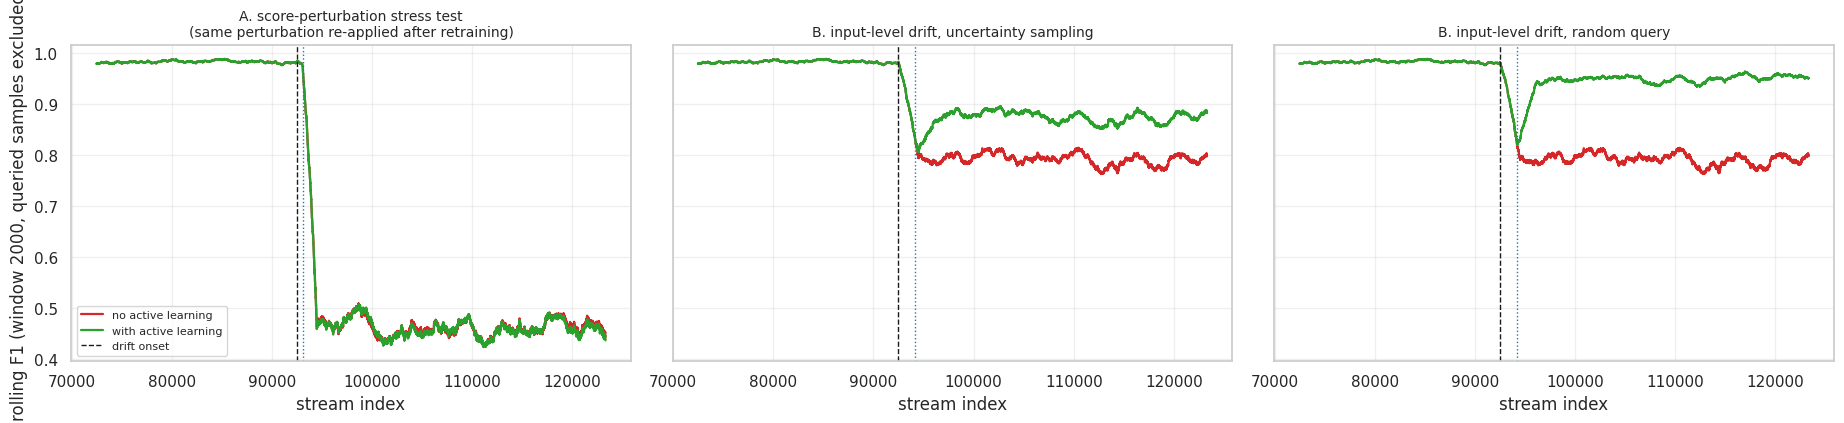

  saved fig_input_drift_recovery.png
  [6b. Plot: input-level drift recovery] done in 2s

  7. Hyper-parameter sensitivity (ML branch, drift severity)
  ML-branch sweep (100k-URL train subsample, 50k-URL val subsample; the paper config is (2,6) / 80000 / 1e-5):
    ngram=(2, 4) feats=20000 alpha=1e-05  val AUC=0.9914  F1=0.9597
    ngram=(2, 4) feats=80000 alpha=1e-05  val AUC=0.9913  F1=0.9606
    ngram=(2, 6) feats=20000 alpha=1e-05  val AUC=0.9923  F1=0.9614
    ngram=(2, 6) feats=80000 alpha=1e-05  val AUC=0.9920  F1=0.9621
    ngram=(3, 8) feats=20000 alpha=1e-05  val AUC=0.9902  F1=0.9554
    ngram=(3, 8) feats=80000 alpha=1e-05  val AUC=0.9915  F1=0.9593
    ngram=(2, 6) feats=80000 alpha=1e-06  val AUC=0.9933  F1=0.9643
    ngram=(2, 6) feats=80000 alpha=0.0001  val AUC=0.9819  F1=0.9340

  Drift-severity sweep (score-perturbation stress test):
 noise_scale  post_drift_f1  post_drift_acc  post_drift_auc  ADWIN_delay  PH_delay  DDM_delay
        0.15         0.8413          0.86

In [36]:
# ------------------------------------------------------------------ driver (cheap -> expensive)
if RUN_OVERLAP_CHECK:      _safe("0. URL overlap / duplicate-leakage check", exp_overlap)
if RUN_BASELINES:          _safe("1a. Classical baselines (NB, gradient boosting)", exp_baselines)
if RUN_DEEP_BASELINES:     _safe("1b. char-Transformer / char-BiGRU baselines", exp_deep_baselines)
if RUN_PRETRAINED_TF:      _safe("1c. Pretrained transformer baseline", exp_pretrained_tf)
if RUN_BOOTSTRAP:          _safe("2. Bootstrap CIs + paired significance tests", exp_bootstrap)
if RUN_BLOCK_TESTS:        _safe("2b. Block-wise Wilcoxon / paired-t tests", exp_block_tests)
if RUN_PERM_IMPORTANCE:    _safe("3. Permutation importance of the meta-learner", exp_perm_importance)
if RUN_META_ABLATION:      _safe("4. Branch ablation + meta-learner sensitivity", exp_meta_ablation)
if RUN_OOD_ANALYSIS:       _safe("5a. OOD analysis (per-branch AUC, few-label adaptation)", exp_ood)
if RUN_OOD_EXTENDED:       _safe("5b. OOD table: more datasets + shift-aware fallback", exp_ood_extended)
if RUN_DOMAIN_EVAL:        _safe("5c. Domain-disjoint evaluation", exp_domain_eval)
if RUN_STREAM_EXPERIMENTS: _safe("6. Drift / active-learning stream experiments", exp_stream)
if RUN_STREAM_PLOT:        _safe("6b. Plot: input-level drift recovery", exp_stream_plot)
if RUN_HPARAM_SENS:        _safe("7. Hyper-parameter sensitivity (ML branch, drift severity)", exp_hparam_sens)
if RUN_REPEATED_RUNS:      _safe("8. Repeated independent runs (random + domain-grouped splits)", exp_repeated_runs)
if RUN_TEMPORAL:           _safe("9. Temporal split (needs TEMPORAL_DATA)", exp_temporal)
_safe("10. Claims & limitations report", exp_report)

save_json("all_results.json", RESULTS)
print("\n" + "=" * 60)
print(f"  ALL REVISION EXPERIMENTS COMPLETE — files in {OUT_DIR}")
print("=" * 60)
